In [ ]:
# Librerías utilizadas durante el sprint

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import json
import os

# Nivel 1 : EDA estructurado y limpieza básica

## Ejercicio 1: Exploración inicial del dataset

Tenemos un dataset de empleados obtenido a partir de una encuesta interna. Antes de poder extraer conclusiones, es necesario asegurarnos de que los datos son correctos, consistentes y analizables.


    🎯 Objetivo: entender la estructura general del dataset y detectar posibles problemas antes de empezar a limpiar o transformar datos.

    En este ejercicio debes realizar una exploración inicial del DataFrame para responder, como mínimo, a las siguientes preguntas:

    » ¿Cuántas filas y columnas tiene el dataset?
    » ¿Qué tipo de datos contiene cada columna?
    » ¿Hay filas duplicadas?
    » ¿Los datos parecen coherentes a primera vista?
    » ¿Detectas posibles problemas o inconsistencias evidentes?

Para ello deberás:

    » Analizar las dimensiones del dataset
    » Mostrar una muestra representativa de filas
    » Revisar los tipos de variables
    » ¿Los datos parecen coherentes a primera vista?
    » Detectar filas duplicadas
    » Identificar y describir posibles problemas iniciales (sin solucionarlos todavía)

In [ ]:
df_empleados = pd.read_excel("/content/drive/MyDrive/Sprint 8/sprint8_complex.xlsx")

### Paso 1

Se consultan las dimensiones del Dataframe para conocer el número de filas y columnas

In [ ]:
filas, columnas = df_empleados.shape

print(f"El dataset contiene {filas} filas y {columnas} columnas.")

El dataset contiene 1010 filas y 20 columnas.


### Paso 2

Se realiza una primera observación del contenido del dataset. Con head() se visualizan las primeras filas, y con sample() se selecciona una muestra aleatoria de registros de diferentes partes del DataFrame.

Esto permite conocer la estructura inicial de los datos y detectar visualmente posibles inconsistencias, sin realizar todavía ninguna modificación.


In [ ]:
df_empleados.head()

,Dades de l'enquesta de treballadors 2025,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19
0,Generades aleatòriament per seguretat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,CÃ rrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
3,0,Joana,Gil Navarro,66722344X,Espanya,Valladolid,23.0,3.0,1958.0,Dona,"1,469 â‚¬",True,NaN,Grup B,Cap de projecte,3.0,True,32108.0,25.0,10.1
4,1,Marc,MuÃ±oz,48840994W,Espanya,Alacant,8.0,11.0,1960.0,H,"2,718 â‚¬",NaN,True,Grup C,Senior analyst,0.0,True,19496.0,10.4,18.7


In [ ]:
df_empleados.sample(5, random_state=42)

,Dades de l'enquesta de treballadors 2025,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19
629,626,Alessandro,Barbieri,82745798H,ItÃ lia,Torino,19.0,5.0,2001.0,NC,"3,600 â‚¬",True,NaN,Grup D,Senior analyst,3.0,True,NaN,NaN,15.2
788,785,NÃºria,Soler Romero,23697646J,Espanya,A CoruÃ±a,10.0,12.0,1993.0,H,"1,405 â‚¬",NaN,True,Grup B,TÃ¨cnic IT,NaN,False,NaN,NaN,18.4
684,681,Nil,LÃ³pez Costa,52138595R,Espanya,MÃ laga,25.0,2.0,2000.0,D,"1,669 â‚¬",NaN,True,Grup B,TÃ¨cnic IT,NaN,True,65950,0.5,22.9
516,513,Carlos,Roca,19027654S,Espanya,ValÃ¨ncia,32.0,0.0,1940.0,D,1470â‚¬,NaN,True,Grup B,Senior analyst,0.0,False,NaN,NaN,-10.0
529,526,Carmen,MuÃ±oz,88446018D,Espanya,Alacant,32.0,13.0,2019.0,NaN,"1,497 â‚¬",NaN,NaN,Grup B,Administratiu,0.0,True,80000,12.1,19.4


Observación:

En la primera visualización se detectan varias inconsistencias estructurales y de codificación:

    - La primera fila informativa del Excel se ha interpretado como encabezado del DataFrame.

    - El subtítulo, la fila vacía y la fila que contiene los nombres reales de las columnas aparecen dentro de los registros del DataFrame.

    - La fila vacía se ha importado con valores NaN.
      Por eso, los nombres asignados actualmente a las columnas no son correctos.

    - Algunos caracteres especiales, como la ñ, las vocales acentuadas y la à,  aparecen codificados incorrectamente.
      Por ejemplo, se observan valores como MuÃ±oz o CÃ rrec.

    - El símbolo del euro también presenta un problema de codificación y aparece representado como â‚¬.

Estas son observaciones preliminares obtenidas a partir de una muestra de los datos.

En los siguientes pasos se comprobará si existen otras inconsistencias, sin corregirlas todavía.

### Paso 3

Con info() obtendremos un resumen de la estructura del df:

    * Nombre de sus columnas
    * Cantidad de valores no nulos
    * Tipo de dato de cada columna

A partir de esta información podemos detectar columnas con datos ausentes y posible tipos incorrectos.

In [ ]:
df_empleados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1010 entries, 0 to 1009
Data columns (total 20 columns):
 #   Column                                    Non-Null Count  Dtype 
---  ------                                    --------------  ----- 
 0   Dades de l'enquesta de treballadors 2025  1008 non-null   object
 1   Unnamed: 1                                1007 non-null   object
 2   Unnamed: 2                                1007 non-null   object
 3   Unnamed: 3                                1007 non-null   object
 4   Unnamed: 4                                1007 non-null   object
 5   Unnamed: 5                                1007 non-null   object
 6   Unnamed: 6                                1007 non-null   object
 7   Unnamed: 7                                1007 non-null   object
 8   Unnamed: 8                                1007 non-null   object
 9   Unnamed: 9                                967 non-null    object
 10  Unnamed: 10                               1007 n

Observación:

info() confirma que el DataFrame contiene 1010 registros y 20 columnas.

    * Los encabezados no se han identificado correctamente y se observan columnas denominadas Unnamed.

    * Algunas columnas tienen menos de 1010 valores no nulos, lo que indica que contienen celdas vacías representadas como NaN.

    * Las columnas aparecen como tipo object, aunque algunas deberían contener valores numéricos.
    
De momento no sabemos si todos esos valores ausentes pertenecen realmente a registros de empleados, porque algunos pueden proceder de las filas informativas y vacías que se importaron incorrectamente.

Primero estamos describiendo lo que muestra el DataFrame tal como se ha cargado.

### Paso 4

Seguimos con duplicated().sum() para detectar filas duplicadas.

In [ ]:
df_empleados.duplicated().sum()

np.int64(0)

Observación:

El resultado obtenido es 0, por lo que no se han detectado filas completamente duplicadas en el DataFrame.

Esto significa que no existen dos filas idénticas en todas sus columnas. Todavía no significa que no haya personas o DNI repetidos con algún dato diferente. Eso se comprobará específicamente más adelante.

### Paso 5

Con isna().sum() se obtiene la cantidad de valores que pandas reconoce como ausentes en cada columna del DataFrame actual.

Sin embargo, estos resultados son preliminares, ya que el DataFrame contiene filas informativas y vacías que no corresponden a registros de empleados.

Además, podrían existir valores ausentes representados mediante texto y que pandas todavía no reconoce como NaN.

Cuando se organice y limpie el dataset, se podrá calcular la cantidad definitiva de valores ausentes.

In [ ]:
df_empleados.isna().sum()

,0
Dades de l'enquesta de treballadors 2025,2
Unnamed: 1,3
Unnamed: 2,3
Unnamed: 3,3
Unnamed: 4,3
Unnamed: 5,3
Unnamed: 6,3
Unnamed: 7,3
Unnamed: 8,3
Unnamed: 9,43


Observación:

Algunas columnas presentan una cantidad elevada de valores ausentes.

No obstante, todavía no se puede determinar correctamente qué variables están más afectadas porque los nombres de las columnas no se han identificado adecuadamente.

Debido a que los nombres reales de las columnas todavía no se han establecido correctamente, la revisión detallada de las variables categóricas y numéricas se realizará más adelante, después de corregir la estructura del DataFrame.





### Conclusión de la exploración inicial

La exploración inicial muestra que el dataset presenta varios problemas que deberán abordarse en los siguientes ejercicios.

    * La primera fila informativa se ha interpretado como encabezado, mientras que los nombres reales de las columnas aparecen dentro de los registros.
    
    * También existe una fila vacía y algunos caracteres, tildes y símbolos monetarios están codificados incorrectamente.

    * Todas las columnas aparecen actualmente como tipo object, incluso aquellas que deberían contener valores numéricos o booleanos. Esto puede deberse a la presencia de encabezados dentro de los datos y a la combinación de números con textos, símbolos o formatos diferentes.

    * No se han detectado filas completamente duplicadas, pero será necesario comprobar si el DNI funciona realmente como identificador único, ya que podrían existir personas repetidas con alguna información diferente.

    + También se han encontrado valores ausentes y posibles inconsistencias en variables como las fechas de nacimiento, el género, el salario, el número de hijos, la posesión de coche, el kilometraje y el consumo. Además, existen tres columnas relacionadas con los hijos (Fills, No Fills y Nombre_fills) que parecen representar datos de una misma información. En los siguientes ejercicios será necesario comprobar si sus valores son coherentes y ver cómo unificarlas.

    * En los siguientes ejercicios será necesario organizar correctamente la estructura del DataFrame, validar los identificadores, revisar los valores ausentes, normalizar las categorías, corregir los tipos de datos y decidir de forma justificada qué registros o columnas deben mantenerse, transformarse o eliminarse.

## Ejercicio 2: Validaciones básicas de los datos y decisiones de eliminación



🎯 Objetivo:

Asegurar que los datos cumplen unas condiciones mínimas de calidad y determinar qué filas pueden seguir siendo analizadas y cuáles deben descartarse.

En este ejercicio tendrás que validar aspectos clave del dataset que son críticos en cualquier contexto real de análisis de datos, tomando decisiones justificadas sobre la validez o eliminación de registros.

Aspectos a validar:

    » ¿Existen identificadores únicos (DNI) para cada persona?
    » ¿Qué vas a hacer con las filas duplicadas o registros repetidos?
    » ¿Existen valores obligatorios que faltan o información incoherente?
    » ¿Detectas formatos incorrectos, errores de codificación o valores imposibles?

Concretamente, deberás:

    » Corregir posibles problemas de codificación y acentuación en los nombres de las columnas y en los valores de texto, si procede.
    » Detectar y eliminar filas duplicadas exactas, indicando cuántos registros se han eliminado.
    » Comprobar la unicidad del DNI. En caso de detectar DNIs duplicados, deberás analizar la coherencia de la información asociada y descartar o anular los registros que no sean fiables, justificando claramente la decisión tomada.
    » Identificar los campos clave que no deberían contener valores nulos, detectar registros con información insuficiente y eliminar únicamente aquellas filas completamente vacías o con información irrecuperable o no sustituible, explicando por qué no es posible ni razonable imputarlas.

Importante

En este ejercicio no se espera que imputes datos, sino que decidas qué registros pueden formar parte del análisis y cuáles no, argumentando siempre el criterio utilizado.

🧠 Si el texto "se entiende pero está mal escrito" → codificación

Si el texto "está bien escrito pero no es útil para el análisis" → validación

### Pasos a seguir:

1. Importar el archivo con header=3 e index_col=0.

2. Identificar las columnas de tipo object.

3. Corregir codificación en nombres de columnas y valores de texto.

4. Detectar y eliminar duplicados exactos.

5. Comprobar DNIs duplicados y analizar sus registros.

6. Identificar campos obligatorios y valores nulos.

7. Eliminar únicamente registros irrecuperables, justificándolo.

### Paso 1

Empiezo por crear un nuevo dataframe (df_validacion) para mantener el original "df_empleados". Para ello, se vuelve a importar el archivo utilizando header=3, porque los nombres correctos de las columnas se encuentran en la cuarta fila del Excel.

Además, se utiliza index_col=0 para tomar la primera columna como índice y evitar que aparezca como una columna duplicada del DataFrame.

In [ ]:
df_validacion = pd.read_excel("/content/drive/MyDrive/Sprint 8/sprint8_complex.xlsx", header=3, index_col=0)

In [ ]:
display(df_validacion.head())

,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,CÃ rrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
0,Joana,Gil Navarro,66722344X,Espanya,Valladolid,23.0,3.0,1958.0,Dona,"1,469 â‚¬",True,NaN,Grup B,Cap de projecte,3.0,True,32108.0,25.0,10.1
1,Marc,MuÃ±oz,48840994W,Espanya,Alacant,8.0,11.0,1960.0,H,"2,718 â‚¬",NaN,True,Grup C,Senior analyst,0.0,True,19496.0,10.4,18.7
2,Noa,Serra,14308421X,Espanya,Alacant,27.0,4.0,1961.0,D,1358 euros,True,NaN,Grup A,TÃ¨cnic IT,4.0,NaN,NaN,NaN,16.7
3,Pol,Gil,58586340F,Espanya,Sevilla,13.0,10.0,1985.0,H,"1,478 â‚¬",True,NaN,Grup B,Data Analyst,2.0,False,NaN,NaN,18.3
4,David,Vila,82070937P,Espanya,Bilbao,29.0,11.0,1965.0,Dona,"1,284 â‚¬",NaN,True,Grup B,Administratiu,NaN,True,NaN,11.8,13.1


### Paso 2: Identificar las columnas de tipo object.

A continuación, seleccionamos las columnas cuyo contenido Pandas considera de tipo object y guardamos sus nombres en la variable columnas_texto.

In [ ]:
columnas_texto = df_validacion.select_dtypes(include="object").columns

columnas_texto

Index(['Nom', 'Cognoms', 'DNI', 'País d'origen', 'Ciutat', 'Gènere',
       'Salari mensual', 'Fills', 'No Fills', 'Grup Professional', 'CÃ rrec',
       'Te_cotxe'],
      dtype='object')

El tipo object no siempre indica que una columna contenga únicamente texto. Por ejemplo:

- Cognoms contiene texto.

- Salari mensual aparece como object porque contiene números, símbolos monetarios y texto.

- Fills aparece como object porque combina valores booleanos con valores ausentes.

- CÃ rrec aparece en el resultado porque el contenido de esa columna es de tipo object, no porque Pandas haya detectado que su nombre está mal escrito.

Este paso permite identificar las columnas sobre las que posteriormente se podrán buscar y corregir posibles problemas de codificación. Por el momento, no se modifica ningún dato.

### Paso 3: Corregir codificación en nombres de columnas y valores de texto.





*Paso 3.1: Corrección de la única columna con nombre mal escrito: 'CÃ rrec'*

In [ ]:
nombre_incorrecto = df_validacion.columns[13]

df_validacion = df_validacion.rename(
    columns={nombre_incorrecto: "Càrrec"}
)

In [ ]:
df_validacion.columns

Index(['Nom', 'Cognoms', 'DNI', 'País d'origen', 'Ciutat', 'Dia de Naixement',
       'Mes de Naixement', 'Any de Naixement', 'Gènere', 'Salari mensual',
       'Fills', 'No Fills', 'Grup Professional', 'Càrrec', 'Nombre_fills',
       'Te_cotxe', 'Km_anuals', 'Consum_mitja_L_100km',
       'Temperatura_mitjana_ciutat'],
      dtype='object')

In [ ]:
repr(nombre_incorrecto)

"'CÃ\\xa0rrec'"

Se corrige el nombre de la columna CÃ rrec, sustituyéndolo por Càrrec, ya que se trata de un problema de codificación y el nombre original puede interpretarse claramente.

*Paso 3.2: volver a identificar las columnas de tipo object*

Hay que actualizar columnas_texto porque renombramos CÃ\xa0rrec como Càrrec. La variable anterior todavía tendría guardado el nombre antiguo.

In [ ]:
columnas_texto = df_validacion.select_dtypes(include="object").columns

columnas_texto

Index(['Nom', 'Cognoms', 'DNI', 'País d'origen', 'Ciutat', 'Gènere',
       'Salari mensual', 'Fills', 'No Fills', 'Grup Professional', 'Càrrec',
       'Te_cotxe'],
      dtype='object')

Después de corregir el nombre de la columna Càrrec, se vuelven a identificar las columnas de tipo object.

*Paso 3.3. Revisión inicial de variables categóricas y numéricas*

Se revisan los valores y sus frecuencias en las principales variables categóricas. Esto permite detectar categorías escritas de diferentes maneras, problemas de codificación, valores ausentes y posibles valores no válidos.

En este paso únicamente se identifican los problemas, sin corregirlos todavía.


3.3.1. Revisión de variables categóricas

Se revisan los valores y sus frecuencias en las principales variables categóricas. Esto permite detectar categorías escritas de diferentes maneras, problemas de codificación, valores ausentes y posibles valores no válidos.

In [ ]:
columnas_categoricas = [
    "País d'origen",
    "Gènere",
    "Grup Professional",
    "Càrrec",
    "Fills",
    "No Fills",
    "Te_cotxe"
]

for columna in columnas_categoricas:
    print(f"\n--- {columna} ---")
    display(df_validacion[columna].value_counts(dropna=False))


--- País d'origen ---


,count
País d'origen,
Espanya,719
ItÃ lia,108
FranÃ§a,86
Alemanya,48
Noruega,44
NaN,1
Narnia,1



--- Gènere ---


,count
Gènere,
D,325
H,280
Dona,120
F,107
Home,52
NaN,41
M,34
A,24
NC,23



--- Grup Professional ---


...

,count
Fills,
NaN,588
True,419



--- No Fills ---


,count
No Fills,
True,584
NaN,422
False,1



--- Te_cotxe ---


,count
Te_cotxe,
NaN,349
False,330
True,328


Se revisan los diferentes valores de las principales variables categóricas y la cantidad de veces que aparece cada uno. Esto permite detectar valores escritos de distintas maneras, problemas de codificación, datos ausentes y posibles valores no válidos.

En este paso únicamente se identifican los problemas, sin corregirlos todavía.

3.3.2. Revisión de variables numéricas

In [ ]:
columnas_numericas = [
    "Dia de Naixement",
    "Mes de Naixement",
    "Any de Naixement",
    "Nombre_fills",
    "Km_anuals",
    "Consum_mitja_L_100km",
    "Temperatura_mitjana_ciutat"
]

display(df_validacion[columnas_numericas].describe().round(2))

,Dia de Naixement,Mes de Naixement,Any de Naixement,Nombre_fills,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
count,1006.00,1006.00,1006.00,709.00,315.00,261.00,936.00
mean,15.03,8.56,2002.23,1.20,55951.05,11.02,15.38
std,10.33,14.30,143.12,1.39,62095.44,8.78,7.28
min,-99.00,0.00,1940.00,0.00,-50.00,0.50,-10.00
25%,7.00,3.25,1969.00,0.00,22632.00,4.70,12.80
50%,15.00,6.00,1982.00,1.00,56135.00,9.80,15.50
75%,24.00,10.00,1995.00,2.00,80000.00,13.60,18.30
max,32.00,99.00,3000.00,5.00,1000000.00,25.00,42.00


Se utilizan estadísticas descriptivas para observar los valores mínimos, máximos, medios y la cantidad de datos disponibles en las variables numéricas. Esta revisión permite detectar posibles valores imposibles o extremos que deberán validarse posteriormente.

*Paso 3.4: Corrección de problemas de codificación en los valores de texto*

Se crea una función para corregir los problemas de codificación y acentuación detectados en las columnas de tipo object.

Los valores que no sean texto o que no necesiten corrección se mantendrán sin cambios.

In [ ]:
def corregir_codificacion(valor):
    """Intenta corregir la codificación de un texto sin modificar otros valores."""

    if not isinstance(valor,str):
      return valor

    for codificacion in ("latin1", "cp1252"):
        try:
            return valor.encode(codificacion).decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            pass

    return valor

Se aplica la función corregir_codificacion() a las columnas identificadas previamente como tipo object. La función revisa cada valor y corrige únicamente los textos que presentan problemas de codificación:

In [ ]:
for columna in columnas_texto:
    df_validacion[columna] = df_validacion[columna].apply(
        corregir_codificacion
    )

Después de aplicar la corrección, se comprueba si todavía quedan caracteres asociados a posibles errores de codificación.

El resultado permitirá verificar cuántos casos permanecen en cada columna.

In [ ]:
for columna in columnas_texto:
    cantidad_errores = (df_validacion[columna]
        .astype(str)
        .str.contains(r"Ã|Â|â|�", regex=True)
        .sum()
    )

    print(columna, ":", cantidad_errores)

Nom : 0
Cognoms : 0
DNI : 0
País d'origen : 0
Ciutat : 0
Gènere : 0
Salari mensual : 0
Fills : 0
No Fills : 0
Grup Professional : 0
Càrrec : 0
Te_cotxe : 0


Todas las columnas muestran un resultado de 0, por lo que no se han encontrado los caracteres buscados después de aplicar la corrección.

In [ ]:
display(df_validacion.head(10))

,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
0,Joana,Gil Navarro,66722344X,Espanya,Valladolid,23.0,3.0,1958.0,Dona,"1,469 €",True,NaN,Grup B,Cap de projecte,3.0,True,32108.0,25.0,10.1
1,Marc,Muñoz,48840994W,Espanya,Alacant,8.0,11.0,1960.0,H,"2,718 €",NaN,True,Grup C,Senior analyst,0.0,True,19496.0,10.4,18.7
2,Noa,Serra,14308421X,Espanya,Alacant,27.0,4.0,1961.0,D,1358 euros,True,NaN,Grup A,Tècnic IT,4.0,NaN,NaN,NaN,16.7
3,Pol,Gil,58586340F,Espanya,Sevilla,13.0,10.0,1985.0,H,"1,478 €",True,NaN,Grup B,Data Analyst,2.0,False,NaN,NaN,18.3
4,David,Vila,82070937P,Espanya,Bilbao,29.0,11.0,1965.0,Dona,"1,284 €",NaN,True,Grup B,Administratiu,NaN,True,NaN,11.8,13.1
5,Alexia,Puig,25014631B,Espanya,Las Palmas de Gran Canaria,1.0,8.0,1978.0,D,"2,069 €",NaN,True,Grup B,Cap de projecte,0.0,NaN,NaN,NaN,19.9
6,David,Gómez Vila,36998038E,Espanya,Palma,25.0,9.0,1971.0,D,"2,349 €",NaN,True,Grup B,Cap de projecte,NaN,True,6196.0,10.6,17.8
7,Carmen,López,47376585K,Espanya,Barcelona,8.0,9.0,1962.0,H,"2,855 €",True,NaN,Grup C,Responsable de vendes,4.0,True,20000.0,5.9,15.4
540,Nora,Andersen Pedersen,37289414J,Noruega,Stavanger,8.0,3.0,1963.0,D,"1,338 €",NaN,True,Grup B,Analista junior,0.0,False,NaN,NaN,7.6
9,Alba,García,75181648S,Espanya,Las Palmas de Gran Canaria,32.0,0.0,1940.0,H,"1,450 €",True,NaN,Grup A,Senior analyst,4.0,False,NaN,NaN,20.1


Después de aplicar la corrección, se ha comprobado que las columnas de texto ya no contienen caracteres asociados a problemas de codificación.

Los nombres, apellidos, ciudades, países, cargos y símbolos monetarios se visualizan correctamente.

### Paso 4: Detectar y eliminar duplicados exactos.

Aquí lo divido en varios sub-pasos:

    Paso 4.1: detectar cuántas filas duplicadas existen

    Paso 4.2: visualizar todos los registros repetidos

    Paso 4.3: eliminar duplicados y contar cuántos se eliminaron

Paso 4.1: detectar cuántas filas duplicadas existen

In [ ]:
cantidad_duplicados = df_validacion.duplicated().sum()

print("Cantidad de filas duplicadas exactas: ", cantidad_duplicados)

Cantidad de filas duplicadas exactas:  4


Paso 4.2: visualizar todos los registros repetidos.

Se utiliza duplicated(keep=False) para visualizar todos los registros implicados en duplicados exactos, incluyendo tanto la primera aparición como las posteriores. Esto permite comprobar los registros antes de eliminarlos.

In [ ]:
filas_duplicadas = df_validacion[df_validacion.duplicated(keep=False)]

print("Las filas duplicadas son: \n", filas_duplicadas)

Las filas duplicadas son: 
           Nom          Cognoms        DNI País d'origen    Ciutat  \
464       Ida  Karlsen Eriksen  55283701C       Noruega      Oslo   
1001      Ida  Karlsen Eriksen  55283701C       Noruega      Oslo   
372      Alba            Muñoz  97954019T       Espanya    Bilbao   
730   Claudia       Gil Ferrer  55297384F       Espanya  València   
757     Oriol           Ferrer  52590001R       Espanya  Zaragoza   
1002     Alba            Muñoz  97954019T       Espanya    Bilbao   
1003  Claudia       Gil Ferrer  55297384F       Espanya  València   
1004    Oriol           Ferrer  52590001R       Espanya  Zaragoza   

      Dia de Naixement  Mes de Naixement  Any de Naixement Gènere  \
464                2.0               9.0            1992.0      D   
1001               2.0               9.0            1992.0      D   
372               25.0              10.0            1983.0      D   
730                1.0              11.0            1981.0      H   
757  

Aquí podemos ver que la fila 36 es exactamente igual a la 40, la fila 372 con la 1002, la fila 730 con 1003 y la fila 757 con la 1004. Y efectivamente eran 4 filas duplicadas.

Paso 4.3: eliminar duplicados y contar cuántos se eliminaron.

Después de comprobarlos, los eliminamos.

Pero también hacemos el conteo anterior y el conteo posterior de filas para comparar.

    * drop_duplicates() conserva la primera aparición y elimina las repeticiones posteriores.

    * reset_index(drop=True) reorganiza el índice sin guardar el índice anterior como otra columna.

In [ ]:
cant_filas_antes = len(df_validacion)

df_validacion = df_validacion.drop_duplicates().reset_index(drop=True)

cant_filas_despues = len(df_validacion)

filas_eliminadas = cant_filas_antes - cant_filas_despues

print("Cantidad de filas duplicadas eliminadas: ", filas_eliminadas)


Cantidad de filas duplicadas eliminadas:  4


Se detectaron y eliminaron 4 filas duplicadas exactas.

Se conservó la primera aparición de cada registro porque las repeticiones contenían exactamente la misma información y no aportaban datos adicionales al análisis.

### Paso 5: Comprobar DNIs duplicados y analizar sus registros.

Ahora toca comprobar la unicidad del DNI.

Esto es diferente de los duplicados exactos:

- Duplicado exacto: toda la fila era idéntica.
- DNI duplicado: el DNI se repite, pero los demás datos pueden ser diferentes.

Entonces primero comparamos registros.

Paso 5.1: identificar qué DNIs aparecen varias veces

In [ ]:
conteo_dni = df_validacion["DNI"].value_counts()

dni_repetidos = conteo_dni[conteo_dni > 1]

print("Cantidad de DNIs repetidos: ", len(dni_repetidos))

Cantidad de DNIs repetidos:  5


In [ ]:
display(dni_repetidos)

,count
DNI,
90585882A,6
16618423V,4
15909601K,2
49529438G,2
54013571W,2


Hay 5 DNIs repetidos.

Recordar que dni_repetidos es una serie, creada por value_counts(). Se puede visualizar que el index son los valores de la columna DNI.

Paso 5.2: mostrar las filas correspondientes

Ahora hacemos código para ver cuáles son esas filas donde están contenidos esos DNIs repetidos.

In [ ]:
registros_dni_repetidos = df_validacion[df_validacion["DNI"].isin(dni_repetidos.index)]

In [ ]:
registros_dni_repetidos = registros_dni_repetidos.sort_values(
    by="DNI"
)

display(registros_dni_repetidos)

,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
249,Laia,Navarro Vila,15909601K,Espanya,Bilbao,30.0,5.0,1958.0,D,1235 euros,True,True,Grup D,Analista junior,0.0,False,NaN,NaN,10.3
603,Laia,Navarro,15909601K,Espanya,Bilbao,30.0,5.0,1958.0,D,"1,676 €",True,False,Grup A,Analista,1.0,True,50.0,NaN,14.2
653,Oriol,Gómez,16618423V,Espanya,Madrid,10.0,1.0,1968.0,Home,1731 euros,True,NaN,Grup B,Data analyst,4.0,NaN,NaN,NaN,NaN
753,Oriol,Gómez,16618423V,Espanya,Barcelona,10.0,1.0,1968.0,Home,2.358 €,True,NaN,NaN,NaN,4.0,NaN,NaN,NaN,NaN
757,Oriol,Gómez,16618423V,Espanya,Màlaga,10.0,1.0,1968.0,H,1879 euros,True,NaN,Grup B,Data Analyst,4.0,False,NaN,NaN,NaN
758,Oriol,Gómez,16618423V,Espanya,Sevilla,10.0,1.0,1968.0,NaN,"2,000 €",NaN,NaN,Grup A,Responsable de vendes,5.0,NaN,NaN,NaN,20.7
557,Alexia,Pérez Díaz,49529438G,Espanya,Màlaga,12.0,10.0,1981.0,Dona,"1,176 €",NaN,True,Grup A,Data Analyst,0.0,False,NaN,NaN,38.0
691,Alexia,Pérez Díaz,49529438G,Espanya,Màlaga,12.0,10.0,1981.0,Dona,1663€,NaN,True,Grup C,Cap de projecte,NaN,True,80000.0,10.7,16.9
88,Guillem,Pujol Costa,54013571W,Espanya,A Coruña,17.0,7.0,1983.0,D,1.574 €,True,NaN,Grup B,Project lead,4.0,False,NaN,NaN,14.6
141,Marta,Ruiz,54013571W,Espanya,Palma,24.0,5.0,1982.0,H,"1,276 €",True,True,Grup A,Analista,0.0,False,NaN,NaN,15.7


Se seleccionan todas las filas cuyo DNI se encuentra entre los cinco DNIs repetidos detectados.

Posteriormente, los registros se ordenan por DNI para poder comparar la información asociada a cada uno y determinar si corresponden a duplicados fiables o a registros incoherentes.

Paso 5.3: Decidir qué registros conservar

DNI 15909601K

    Coinciden nombre, parte del apellido, nacimiento, país, ciudad y género.  
    La fila 249 es contradictoria porque Fills=True, No Fills=True y Nombre_fills=0.

    Además, la fila 603 muestra un salario superior y un cargo de mayor responsabilidad:
    pasa de Analista junior con 1235 euros a Analista con 1.676 €.
    Esto podría corresponder a una evolución profesional.
    Así que conservamos la fila 603.

DNI 16618423V

    Coinciden nombre, apellidos y nacimiento.  
    Cambian ciudad, salario y trabajo, pero no existe una fecha que permita determinar cuál es el registro actual.  
    Así que conservamos la fila 757 que me parece la más coherente.

DNI 49529438G

    Coinciden completamente los datos de identidad.
    La fila 691 presenta un salario superior y un cargo de mayor responsabilidad: pasa de Data Analyst con 1.176 € en la fila 557 a Cap de projecte con 1.663 €.
    Esto podría representar una evolución profesional.
    Además, también existen diferencias en la información sobre hijos, coche y temperatura.
    Así que conservamos la fila 691.

DNI 54013571W

    Corresponde a dos personas completamente diferentes: Guillem y Marta, con distinto nacimiento, ciudad y género.
    Eliminamos las 2 filas.

DNI 90585882A

    Está asignado a varias personas completamente diferentes: Sara, Oriol, Pol y Xavier.
    No puede saberse a quién pertenece realmente.
    Eliminamos las 6 filas.

Para decidir qué registros pueden continuar en el análisis, se han comparado primero los datos de identidad: nombre, apellidos y fecha de nacimiento.

Cuando estos datos coinciden, se considera que probablemente se trata de la misma persona y se conserva el registro más completo y coherente.

Cuando un mismo DNI aparece asociado a personas claramente diferentes, se eliminan todos los registros afectados, ya que no existe información suficiente para determinar a quién pertenece realmente el identificador.

Paso 6.4: Identificar los registros que se conservarán y eliminarán

De acuerdo con las decisiones justificadas en el paso anterior, se conservarán las filas 603, 757 y 691. A continuación, se obtienen los índices de los demás registros con DNI repetido, que serán descartados.

In [ ]:
indices_conservar = [603, 757, 691]

indices_eliminar = registros_dni_repetidos.index.difference(
    indices_conservar
)

print("Índices que se conservarán:", indices_conservar)
print("Índices que se eliminarán:", indices_eliminar.tolist())
print("Cantidad de registros que se eliminarán:", len(indices_eliminar))

Índices que se conservarán: [603, 757, 691]
Índices que se eliminarán: [25, 88, 103, 113, 141, 249, 280, 557, 653, 753, 758, 912, 999]
Cantidad de registros que se eliminarán: 13


Paso 5.4. Guardar una copia de los registros descartados

Antes de eliminar los registros considerados no fiables, se guarda una copia en un DataFrame independiente llamado registros_descartados_dni.

De esta manera, se pueden consultar posteriormente las filas que fueron excluidas de **df_validacion**.

Los motivos de su exclusión han sido justificados en el apartado anterior.

In [ ]:
#El df de las filas a eliminar las vamos a guardar en la variable(df independiente):
registros_descartados_dni = df_validacion.loc[
    indices_eliminar
].copy()

display(registros_descartados_dni)

,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
25,Sara,Serra,90585882A,Espanya,Tarragona,28.0,5.0,2002.0,D,993 €,NaN,True,Grup A,Administratiu,0.0,False,NaN,NaN,15.8
88,Guillem,Pujol Costa,54013571W,Espanya,A Coruña,17.0,7.0,1983.0,D,1.574 €,True,NaN,Grup B,Project lead,4.0,False,NaN,NaN,14.6
103,Oriol,Vila Casals,90585882A,Espanya,Madrid,30.0,9.0,1964.0,H,1987 euros,NaN,True,Grup B,Responsable de vendes,0.0,False,NaN,NaN,13.5
113,Pol,Serra,90585882A,Espanya,Girona,4.0,12.0,1960.0,H,"1,178 €",NaN,True,Grup A,Data Analyst,NaN,False,NaN,NaN,16.2
141,Marta,Ruiz,54013571W,Espanya,Palma,24.0,5.0,1982.0,H,"1,276 €",True,True,Grup A,Analista,0.0,False,NaN,NaN,15.7
249,Laia,Navarro Vila,15909601K,Espanya,Bilbao,30.0,5.0,1958.0,D,1235 euros,True,True,Grup D,Analista junior,0.0,False,NaN,NaN,10.3
280,Xavier,Vidal,90585882A,Espanya,Alacant,2.0,7.0,1958.0,H,1179 euros,NaN,NaN,Grup A,Tècnic IT,0.0,True,63574.0,6.0,16.8
557,Alexia,Pérez Díaz,49529438G,Espanya,Màlaga,12.0,10.0,1981.0,Dona,"1,176 €",NaN,True,Grup A,Data Analyst,0.0,False,NaN,NaN,38.0
653,Oriol,Gómez,16618423V,Espanya,Madrid,10.0,1.0,1968.0,Home,1731 euros,True,NaN,Grup B,Data analyst,4.0,NaN,NaN,NaN,NaN
753,Oriol,Gómez,16618423V,Espanya,Barcelona,10.0,1.0,1968.0,Home,2.358 €,True,NaN,NaN,NaN,4.0,NaN,NaN,NaN,NaN


Paso 5.5: Eliminar los registros no fiables

Después de guardar una copia, se eliminan de df_validacion los registros considerados no fiables.

Se conservan los registros seleccionados para las identidades coincidentes y se descartan aquellos cuyo DNI no puede validarse correctamente.

In [ ]:
cantidad_antes = len(df_validacion)

df_validacion = df_validacion.drop(index=indices_eliminar)

#Reorganizamos el índice para que vuelva a empezar desde 0 y sea consecutivo
df_validacion = df_validacion.reset_index(drop=True)

cantidad_despues = len(df_validacion)

cantidad_eliminada_dni = cantidad_antes - cantidad_despues

print(
    "Registros eliminados por inconsistencias en el DNI:",
    cantidad_eliminada_dni
)

Registros eliminados por inconsistencias en el DNI: 13


Se han eliminado 13 registros asociados a DNI repetidos que no se consideraron fiables.

Antes de eliminarlos, se guardó una copia en registros_descartados_dni.

Después de la eliminación, se reorganizó el índice de df_validacion para que fuera nuevamente consecutivo.

Paso 5.6. Comprobar que los DNI restantes son únicos

Después de eliminar los registros no fiables, se comprueba nuevamente la unicidad de los DNI.

En esta comprobación se excluyen temporalmente los valores ausentes, ya que los registros sin DNI se revisarán posteriormente como parte del análisis de campos clave.

In [ ]:
dni_no_nulos = df_validacion.loc[df_validacion["DNI"].notna(), "DNI"]

dni_duplicados_restantes = dni_no_nulos.duplicated()

cantidad_dni_duplicados = dni_duplicados_restantes.sum()

print(
    "DNIs duplicados restantes:",
    cantidad_dni_duplicados
)

DNIs duplicados restantes: 0


El resultado de la comprobación es cero, por lo que los DNI no nulos que permanecen en df_validacion son únicos.

Los posibles registros sin DNI todavía no se eliminan, ya que serán revisados en el siguiente apartado para determinar si contienen información suficiente o si deben descartarse.


### Paso 6: revisar campos clave, valores nulos y registros irrecuperables.





Aquí comprobaremos:

1. Si faltan valores en los campos clave.
2. Si existen filas completamente vacías.
3. Si hay DNI con formato claramente incorrecto, como XXXX.
4. Qué registros no pueden recuperarse razonablemente.
5. Cuántos registros se eliminan.

*Paso 6.1: Definir y revisar los campos clave*

Consideraremos campos clave:

- DNI: identificador único.
- Nom: nombre de la persona.
- Cognoms: apellidos de la persona.

Se consideran campos clave el DNI, el nombre y los apellidos, ya que permiten identificar a cada persona.

Estos datos no deberían estar ausentes y, especialmente en el caso del DNI, no sería razonable inventar o imputar su valor.

Se crea la lista `campos_clave` con los nombres de las columnas consideradas imprescindibles para identificar a cada persona: `DNI`, `Nom` y `Cognoms`. En este momento la variable únicamente contiene nombres de columnas y todavía no accede a los datos. Posteriormente, esta lista se utiliza dentro de `df_validacion[campos_clave]` para seleccionar esas columnas y comprobar si contienen valores ausentes.

In [ ]:
campos_clave = ["DNI", "Nom", "Cognoms"]

nulos_campos_clave = df_validacion[campos_clave].isna().sum()

display(nulos_campos_clave)

,0
DNI,1
Nom,1
Cognoms,1


*Paso 6.2: Revisar y eliminar registros con campos clave ausentes*



In [ ]:
# Seleccionamos las filas donde falta al menos uno de los campos clave
registros_campos_clave_nulos = df_validacion[
    df_validacion[campos_clave].isna().any(axis=1)
]

display(registros_campos_clave_nulos)

,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
988,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Se ha encontrado un único registro con campos clave ausentes.

Al revisar la fila, se observa que no solamente faltan el DNI, el nombre y los apellidos, sino que todos sus campos están vacíos.

Por este motivo, el registro no contiene información recuperable y se decide eliminarlo.

Luego:

In [ ]:
# Guardamos una copia del registro antes de eliminarlo
registros_descartados_vacios = registros_campos_clave_nulos.copy()

cantidad_filas_vacias = len(registros_campos_clave_nulos)

df_validacion = df_validacion.drop(
    index=registros_campos_clave_nulos.index
).reset_index(drop=True)

print(
    "Filas completamente vacías eliminadas:",
    cantidad_filas_vacias
)

Filas completamente vacías eliminadas: 1


In [ ]:
display(df_validacion.tail())

,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
984,Jordi,Hernández,67755039Y,Espanya,Zaragoza,12.0,10.0,1961.0,Dona,"1,074 €",NaN,NaN,Grup A,Data Analyst,1.0,True,80000.0,12.0,12.0
985,Chloé,Dubois,66354268T,França,Nice,2.0,12.0,1958.0,H,"1,954 €",True,NaN,Grup B,Data Analyst,1.0,NaN,NaN,NaN,11.7
986,Adrià,Vila Díaz,57511543T,Espanya,Palma,31.0,12.0,1991.0,H,"2,010 €",True,NaN,Grup C,Analista,1.0,False,NaN,NaN,-10.0
987,Kasper,Pettersen,62042563B,Noruega,Oslo,11.0,5.0,1996.0,D,2.290 €,NaN,True,Grup B,Senior analyst,0.0,True,80000.0,0.5,6.5
988,???,###,XXXX,Narnia,Desconeguda,-99.0,99.0,3000.0,??,molts,NaN,NaN,Z,???,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Comprobamos si todavía quedan filas con campos clave ausentes
display(
    df_validacion[
        df_validacion[campos_clave].isna().any(axis=1)
    ]
)

,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat


*Paso 6.3: Revisar el formato de los DNI*

Un DNI debe tener, de forma básica:

- Ocho números.
- Una letra final.

Aunque los DNI restantes son únicos y no contienen valores nulos, también es necesario comprobar que presentan dicho formato básico y válido.

In [ ]:
formato_dni_valido = df_validacion["DNI"].str.fullmatch(
    r"\d{8}[A-Z]",
    na=False
)

registros_dni_invalido = df_validacion[
    formato_dni_valido == False
]

display(registros_dni_invalido)

,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
988,???,###,XXXX,Narnia,Desconeguda,-99.0,99.0,3000.0,??,molts,NaN,NaN,Z,???,NaN,NaN,NaN,NaN,NaN


Decisión

El DNI XXXX no puede corregirse porque no conocemos su valor verdadero, así que lo eliminamos. Pero primero lo guardamos por si acaso, por ejemplo, nuestro cliente quisiera verlo.

In [ ]:
registros_descartados_dni_invalido = (
    registros_dni_invalido.copy()
)

df_validacion = df_validacion.drop(
    index=registros_dni_invalido.index).reset_index(drop=True)

print(
    "Registros eliminados por DNI inválido:",
    len(registros_dni_invalido)
)

Registros eliminados por DNI inválido: 1


*Paso 6.4: Comprobación final del ejercicio 2*

Finalmente, se realizan varias comprobaciones para confirmar que el DataFrame ya no contiene duplicados exactos, DNI repetidos, campos clave ausentes, filas completamente vacías ni DNI con un formato incorrecto.



In [ ]:
print("Dimensiones finales:", df_validacion.shape)

# Comprobamos si quedan filas completamente duplicadas
print(
    "Duplicados exactos:",
    df_validacion.duplicated().sum()
)

# Comprobamos si quedan DNI repetidos
print(
    "DNI duplicados:",
    df_validacion["DNI"].duplicated().sum()
)

# Comprobamos si todavía queda alguna fila completamente vacía
print(
    "Filas completamente vacías:",
    df_validacion.isna().all(axis=1).sum()
)

# Comprobamos nuevamente el formato de todos los DNI
formato_dni_correcto = df_validacion["DNI"].str.fullmatch(
    r"\d{8}[A-Z]",
    na=False
)

# Contamos los DNI que no cumplen el formato
print(
    "DNI con formato incorrecto:",
    (formato_dni_correcto == False).sum()
)

Dimensiones finales: (988, 19)
Duplicados exactos: 0
DNI duplicados: 0
Filas completamente vacías: 0
DNI con formato incorrecto: 0


In [ ]:
display(df_validacion[campos_clave].isna().sum())

,0
DNI,0
Nom,0
Cognoms,0


## Ejercicio 3: Transformaciones necesarias y preparación del dataset

🎯 Objetivo:

Preparar el dataset para que sea coherente, analizable y estructuralmente correcto antes de realizar cualquier análisis descriptivo.

En este ejercicio deberás aplicar transformaciones básicas pero esenciales, orientadas a mejorar la calidad de los datos y facilitar el posterior análisis.

Aspectos a revisar y transformar:

    » ¿Los valores categóricos están normalizados y son consistentes?
    » ¿Los valores nulos son coherentes con la información disponible?
    » ¿Existe redundancia de variables que pueda generar problemas analíticos?
    » ¿Las variables contextuales (como temperatura, salario) están completas y preparadas para el análisis?

Concretamente, tendrás que:

    » Normalizar los valores categóricos para evitar ambigüedades (por ejemplo, valores que representan el mismo concepto pero están escritos de forma diferente).

    » Revisar la coherencia de los valores nulos, asegurando que:

        * Las personas con kilometraje anual y consumo medio asociados disponen de coche.
        En los casos en que conste consumo medio pero no kilometraje anual, será necesario decidir cómo resolver esta incoherencia de forma justificada.

        * Las personas que tienen un valor en el número de hijos tienen efectivamente hijos.

    » Unificar la información sobre hijos en una única columna, ya que mantener varias columnas con información complementaria no es óptimo y puede generar problemas analíticos (redundancia o multicolinealidad).

    » Validar la temperatura media. En caso de que esa información falte, deberás imputarla utilizando un criterio razonable (por ciudad o por un nivel superior justificado).

    » Revisar e imputar los salarios faltantes, aplicando criterios analíticos coherentes (como cargo, grupo profesional, ciudad, género o franja de edad).

### Pasos:

1. Crear una copia del DataFrame.

2. Normalizar variables categóricas.

3. Revisar y unificar la información sobre hijos.

4. Revisar la coherencia entre coche, kilometraje y consumo.

5. Validar e imputar temperaturas.

6. Limpiar e imputar salarios.

7. Realizar una comprobación final.

### Paso 1: Crear una copia del Dataframe de Validación.



In [ ]:
df_transformacion = df_validacion.copy()

print("Dimensiones:", df_transformacion.shape)

display(df_transformacion.head())

Dimensiones: (988, 19)


,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
0,Joana,Gil Navarro,66722344X,Espanya,Valladolid,23.0,3.0,1958.0,Dona,"1,469 €",True,NaN,Grup B,Cap de projecte,3.0,True,32108.0,25.0,10.1
1,Marc,Muñoz,48840994W,Espanya,Alacant,8.0,11.0,1960.0,H,"2,718 €",NaN,True,Grup C,Senior analyst,0.0,True,19496.0,10.4,18.7
2,Noa,Serra,14308421X,Espanya,Alacant,27.0,4.0,1961.0,D,1358 euros,True,NaN,Grup A,Tècnic IT,4.0,NaN,NaN,NaN,16.7
3,Pol,Gil,58586340F,Espanya,Sevilla,13.0,10.0,1985.0,H,"1,478 €",True,NaN,Grup B,Data Analyst,2.0,False,NaN,NaN,18.3
4,David,Vila,82070937P,Espanya,Bilbao,29.0,11.0,1965.0,Dona,"1,284 €",NaN,True,Grup B,Administratiu,NaN,True,NaN,11.8,13.1


### Paso 2. Empezar a normalizar variables categóricas



*Paso 2.1: revisamos los valores de Gènere.*

Comenzaremos por Gènere, porque ya se observó que contiene distintas formas de representar una misma categoría. Incluimos en la revisión a los valores nulos, para ver todo.

In [ ]:
display(df_transformacion["Gènere"].value_counts(dropna=False))

,count
Gènere,
D,318
H,275
Dona,118
F,107
Home,50
NaN,39
M,34
A,24
NC,23


Se observa que existen diferentes codificaciones que parecen representar una misma categoría: D, Dona y F corresponderían al género femenino; mientras que H, Home y M corresponderían al género masculino.

Asimismo, "A" podría significar "Altres" y "NC", "No consta". Estas categorías deberán normalizarse para evitar que un mismo concepto aparezca representado de distintas maneras.

*Paso 2.2. Normalizar la columna Gènere*

Hacemos un diccionario de asignación para normalizar los géneros.
A "NC" le asignamos pd.NA para que Pandas lo lea como ausente.

Luego, sustituimos los valores utilizando el diccionario.
Los valores que no aparecen en el diccionario, como Dona y Home, se mantienen sin cambios.

In [ ]:
mapa_genero = {
    "D": "Dona",
    "F": "Dona",
    "H": "Home",
    "M": "Home",
    "A": "Altres",
    "NC": pd.NA
}

df_transformacion["Gènere"] = (
    df_transformacion["Gènere"].replace(mapa_genero)
)

In [ ]:
# Comprobamos que las categorías han quedado normalizadas.

display(
    df_transformacion["Gènere"].value_counts(dropna=False)
)

,count
Gènere,
Dona,543
Home,359
NaN,39
Altres,24
<NA>,23


In [ ]:
# Contamos todos los valores ausentes, tanto NaN como <NA>.

df_transformacion["Gènere"].isna().sum()

np.int64(62)

Convertimos la columna al tipo string de Pandas( .astype("string"), no .astype("str)"))

Esto unifica NaN y < NA > bajo una misma representación: < NA >

In [ ]:
df_transformacion["Gènere"] = (
    df_transformacion["Gènere"].astype("string")
)

In [ ]:
display(
    df_transformacion["Gènere"].value_counts(dropna=False)
)

,count
Gènere,
Dona,543
Home,359
<NA>,62
Altres,24


*Paso 2.4. Revisar la columna Càrrec*

La siguiente variable categórica importante será Càrrec, porque después podremos utilizarla como criterio para imputar los salarios ausentes. Primero necesitamos asegurarnos de que un mismo cargo no esté escrito de diferentes maneras.

In [ ]:
# Revisamos los diferentes valores de la columna Càrrec
# y el número de veces que aparece cada uno.

display(
    df_transformacion["Càrrec"].value_counts(dropna=False)
)

,count
Càrrec,
Data Analyst,140
Tècnic IT,128
Senior analyst,122
Responsable de vendes,121
Analista,113
Analista junior,106
Administratiu,102
Cap de projecte,94
Project lead,17


Se visualiza que:

* Admin. = Administratiu
* Cap de Projecte = Cap de projecte = Project lead
* Data analyst = Data Analyst

Se mantienen igual:

* Analista
* Analista junior
* Data Analyst

Aunque puedan estar relacionados, no podemos asegurar que sean exactamente el mismo cargo ni que tengan el mismo nivel profesional.

*Paso 2.5. Normalizar Càrrec*



In [ ]:
# Creamos un diccionario para unificar los cargos
# que representan el mismo puesto de trabajo y los traducimos al catalán.

mapa_carrec = {
    "Admin.": "Administratiu",
    "Cap de Projecte": "Cap de projecte",
    "Project lead": "Cap de projecte",
    "Analyst": "Analista",
    "Senior analyst": "Analista sènior",
    "Data analyst": "Analista de dades",
    "Data Analyst": "Analista de dades",
    "Analista junior": "Analista júnior"
}

df_transformacion["Càrrec"] = (
    df_transformacion["Càrrec"]
    .replace(mapa_carrec)
    .astype("string"))


In [ ]:
# Comprobamos que los cargos equivalentes se han unificado.

display(
    df_transformacion["Càrrec"].value_counts(dropna=False)
)

,count
Càrrec,
Analista de dades,157
Tècnic IT,128
Cap de projecte,124
Analista sènior,122
Analista,122
Responsable de vendes,121
Administratiu,108
Analista júnior,106


La decisión más importante es no unificar Data Analyst con Analista, ya que no necesariamente representan el mismo puesto.

Mientras que Data Analyst se refiere específicamente al análisis de datos, el término Analista es más general y podría corresponder, por ejemplo, a Recursos Humanos, Contabilidad u otra área.

Además, posteriormente se utilizará el cargo como posible criterio para imputar los salarios ausentes, y agrupar puestos diferentes podría producir una estimación salarial poco fiable.

### Paso 3: Revisar y unificar la información sobre hijos.

*Paso 3.1. Revisar la información sobre hijos*

Contamos las combinaciones entre las columnas relacionadas con los hijos y convertimos el resultado en una tabla sencilla.

In [ ]:
combinaciones_fills = (
    df_transformacion[
        ["Fills", "No Fills", "Nombre_fills"]
    ]
    .value_counts(dropna=False)
    .reset_index(name="Cantidad")
)

display(combinaciones_fills)

,Fills,No Fills,Nombre_fills,Cantidad
0,NaN,True,NaN,263
1,NaN,True,0.0,255
2,True,NaN,1.0,160
3,True,NaN,4.0,74
4,True,NaN,2.0,73
5,True,NaN,3.0,59
6,True,True,0.0,32
7,NaN,NaN,NaN,29
8,NaN,NaN,0.0,14
9,True,True,1.0,6


**Casos principales encontrados:**

Caso 1:

    Caso resoluble de 263 registros:

    Fills = NaN
    No Fills = True
    Nombre_fills = NaN

    Se asignará Nombre_fills = 0 porque No Fills=True nos permite deducir que el número debe ser 0.

Caso 2:

    Caso completamente desconocido de 29 registros:

    Fills = NaN
    No Fills = NaN
    Nombre_fills = NaN

    No tenemos ninguna información. Deben mantenerse como ausentes.

Caso 3:

    Caso contradictorio e irrecuperable de 3 registros:

    Fills = True
    No Fills = True
    Nombre_fills = NaN

    Las dos columnas dicen cosas contrarias y no tenemos un número que permita decidir. Se mantendrá Nombre_fills como ausente.

Caso 4:

    Contradicciones con un número disponible:

    Fills = True
    No Fills = True
    Nombre_fills = 3

    Aunque los booleanos se contradicen, Nombre_fills=3 es la información más precisa. Se conserva el número 3.

Caso 5:

    Cuando aparece solo un booleano y un número disponible:

    Fills = NaN
    No Fills = True
    Nombre_fills = 2

    Conservaremos el número 2 porque es una información más concreta que la columna booleana.

*Paso 3.2. Completar los casos claramente identificables*

Caso 1: podemos completar el número con 0

In [ ]:
caso_1 = (
    df_transformacion["Nombre_fills"].isna()
    & (df_transformacion["No Fills"] == True)
    & df_transformacion["Fills"].isna()
)

print("Registros del caso 1:", caso_1.sum())

Registros del caso 1: 263


Luego, asignamos 0 porque No Fills=True indica que la persona no tiene hijos.

Se lee así: Dentro de df_transformacion, localiza las filas donde caso_1 sea True y,solamente en la columna Nombre_fills, escribe el valor 0.

In [ ]:
df_transformacion.loc[caso_1, "Nombre_fills"] = 0

Guardamos en un dataframe "filas_caso_1" las filas donde ya se aplico la condicion del caso_1.

In [ ]:
filas_caso_1 = df_transformacion.loc[caso_1]

display(filas_caso_1)

,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
4,David,Vila,82070937P,Espanya,Bilbao,29.0,11.0,1965.0,Dona,"1,284 €",NaN,True,Grup B,Administratiu,0.0,True,NaN,11.8,13.1
6,David,Gómez Vila,36998038E,Espanya,Palma,25.0,9.0,1971.0,Dona,"2,349 €",NaN,True,Grup B,Cap de projecte,0.0,True,6196.0,10.6,17.8
12,Aina,Pérez,31172421Z,Espanya,Las Palmas de Gran Canaria,10.0,6.0,1973.0,Home,"3,672 €",NaN,True,Grup D,Cap de projecte,0.0,True,10800.0,12.9,22.0
13,Emilia,Hoffmann,66851377P,Alemanya,Stuttgart,21.0,2.0,1961.0,Dona,"1,003 €",NaN,True,Grup A,Cap de projecte,0.0,True,6931.0,12.2,12.4
18,Nil,Fernández Vidal,69345683K,Espanya,Bilbao,15.0,8.0,1978.0,Home,"1,751 €",NaN,True,Grup B,Analista sènior,0.0,True,64444.0,0.5,16.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
979,Sara,Navarro,43732173G,Espanya,Alacant,12.0,3.0,1996.0,Home,"1,903 €",NaN,True,Grup B,Analista de dades,0.0,NaN,NaN,NaN,24.3
980,Xavier,García Gil,95100395N,Espanya,Girona,16.0,7.0,1960.0,Dona,1437€,NaN,True,Grup A,Analista sènior,0.0,False,NaN,NaN,NaN
981,Adrià,Hernández Ramos,80771894Q,Espanya,Bilbao,24.0,6.0,1990.0,Altres,tres mil,NaN,True,Grup A,Analista sènior,0.0,True,80000.0,25.0,18.2
982,Laura,Bauer Zimmermann,34637932B,Alemanya,Köln,6.0,3.0,1993.0,Home,"1,644 €",NaN,True,Grup B,Analista,0.0,False,NaN,NaN,11.5


Caso 2: no existe ninguna información

In [ ]:
caso_2 = (
    df_transformacion["Fills"].isna()
    & df_transformacion["No Fills"].isna()
    & df_transformacion["Nombre_fills"].isna()
)

print("Registros del caso 2:", caso_2.sum())

Registros del caso 2: 29


Aquí no hacemos ninguna transformación. Nombre_fills permanece ausente porque completar con 0 significaría inventar información.

Caso 3: información contradictoria sin número

In [ ]:
caso_3 = (
    (df_transformacion["Fills"] == True)
    & (df_transformacion["No Fills"] == True)
    & df_transformacion["Nombre_fills"].isna()
)

print("Registros del caso 3:", caso_3.sum())

Registros del caso 3: 3


Tampoco transformamos estos registros. Nombre_fills se mantiene ausente porque la información es contradictoria y no tenemos un número que permita resolverla.

Caso 4: contradicción, pero existe un número

In [ ]:
caso_4 = (
    (df_transformacion["Fills"] == True)
    & (df_transformacion["No Fills"] == True)
    & df_transformacion["Nombre_fills"].notna()
)

print("Registros del caso 4:", caso_4.sum())

Registros del caso 4: 43


Aquí tampoco necesitamos cambiar "Nombre_fills": simplemente conservamos el número existente.

Caso 5: No Fills=True, pero existe un número superior a 0

In [ ]:
caso_5 = (
    df_transformacion["Fills"].isna()
    & (df_transformacion["No Fills"] == True)
    & (df_transformacion["Nombre_fills"] > 0)
)

print("Registros del caso 5:", caso_5.sum())

Registros del caso 5: 9


Tampoco cambiamos nada porque el número ya está registrado y hemos decidido darle prioridad.

*Paso 3.3. Convertir Nombre_fills en números enteros*

Actualmente los valores pueden aparecer como 0.0, 1.0, 2.0, etc.

Como no puede existir 1.5 hijos, los convertimos a enteros.

Se utiliza "Int64" con mayúscula porque es el tipo de entero de Pandas que admite valores ausentes < NA >.

In [ ]:
df_transformacion["Nombre_fills"] = (
    df_transformacion["Nombre_fills"].astype("Int64")
)

In [ ]:
# Comprobamos los valores finales y cuántas veces aparece cada uno.

display(
    df_transformacion["Nombre_fills"]
    .value_counts(dropna=False).reset_index(name="Cantidad")
)

,Nombre_fills,Cantidad
0,0,564
1,1,171
2,2,79
3,4,78
4,3,64
5,<NA>,32


*Paso 3.4. Eliminar las columnas redundantes*

Como ya hemos estudiado los casos y hemos decidido que Nombre_fills será la columna definitiva, podemos retirar Fills y No Fills.

In [ ]:
df_transformacion = df_transformacion.drop(columns=["Fills", "No Fills"])

In [ ]:
display(df_transformacion.head())

,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Grup Professional,Càrrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
0,Joana,Gil Navarro,66722344X,Espanya,Valladolid,23.0,3.0,1958.0,Dona,"1,469 €",Grup B,Cap de projecte,3,True,32108.0,25.0,10.1
1,Marc,Muñoz,48840994W,Espanya,Alacant,8.0,11.0,1960.0,Home,"2,718 €",Grup C,Analista sènior,0,True,19496.0,10.4,18.7
2,Noa,Serra,14308421X,Espanya,Alacant,27.0,4.0,1961.0,Dona,1358 euros,Grup A,Tècnic IT,4,NaN,NaN,NaN,16.7
3,Pol,Gil,58586340F,Espanya,Sevilla,13.0,10.0,1985.0,Home,"1,478 €",Grup B,Analista de dades,2,False,NaN,NaN,18.3
4,David,Vila,82070937P,Espanya,Bilbao,29.0,11.0,1965.0,Dona,"1,284 €",Grup B,Administratiu,0,True,NaN,11.8,13.1


Después de analizar las diferentes combinaciones de Fills, No Fills y Nombre_fills, se ha decidido conservar únicamente Nombre_fills, ya que contiene la información más concreta sobre la cantidad de hijos.

Se ha asignado el valor 0 solamente cuando "No Fills=True" permitía concluir que la persona no tenía hijos y no existía información contradictoria.

Los casos completamente desconocidos o contradictorios sin una cantidad disponible se han mantenido como valores ausentes.

Finalmente, se han eliminado las columnas Fills y No Fills por ser redundantes.

In [ ]:
display(df_transformacion.head(20))

,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Grup Professional,Càrrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
0,Joana,Gil Navarro,66722344X,Espanya,Valladolid,23.0,3.0,1958.0,Dona,"1,469 €",Grup B,Cap de projecte,3,True,32108.0,25.0,10.1
1,Marc,Muñoz,48840994W,Espanya,Alacant,8.0,11.0,1960.0,Home,"2,718 €",Grup C,Analista sènior,0,True,19496.0,10.4,18.7
2,Noa,Serra,14308421X,Espanya,Alacant,27.0,4.0,1961.0,Dona,1358 euros,Grup A,Tècnic IT,4,NaN,NaN,NaN,16.7
3,Pol,Gil,58586340F,Espanya,Sevilla,13.0,10.0,1985.0,Home,"1,478 €",Grup B,Analista de dades,2,False,NaN,NaN,18.3
4,David,Vila,82070937P,Espanya,Bilbao,29.0,11.0,1965.0,Dona,"1,284 €",Grup B,Administratiu,0,True,NaN,11.8,13.1
5,Alexia,Puig,25014631B,Espanya,Las Palmas de Gran Canaria,1.0,8.0,1978.0,Dona,"2,069 €",Grup B,Cap de projecte,0,NaN,NaN,NaN,19.9
6,David,Gómez Vila,36998038E,Espanya,Palma,25.0,9.0,1971.0,Dona,"2,349 €",Grup B,Cap de projecte,0,True,6196.0,10.6,17.8
7,Carmen,López,47376585K,Espanya,Barcelona,8.0,9.0,1962.0,Home,"2,855 €",Grup C,Responsable de vendes,4,True,20000.0,5.9,15.4
8,Nora,Andersen Pedersen,37289414J,Noruega,Stavanger,8.0,3.0,1963.0,Dona,"1,338 €",Grup B,Analista júnior,0,False,NaN,NaN,7.6
9,Alba,García,75181648S,Espanya,Las Palmas de Gran Canaria,32.0,0.0,1940.0,Home,"1,450 €",Grup A,Analista sènior,4,False,NaN,NaN,20.1


Después de revisar las principales variables categóricas, se han normalizado aquellas que presentaban distintas formas de representar un mismo concepto, especialmente Gènere y Càrrec.

También se ha unificado la información relacionada con los hijos en la columna Nombre_fills.

Las variables País d'origen y Grup Professional no requieren modificaciones porque sus categorías son consistentes.

La variable "Te_cotxe" se revisará a continuación junto con el kilometraje anual y el consumo medio para comprobar la coherencia entre estas variables.

### Paso 4. Coherencia entre coche, kilometraje y consumo

Se revisan conjuntamente las columnas Te_cotxe, Km_anuals y Consum_mitja_L_100km.

Se buscarán posibles contradicciones, como personas que tienen kilometraje o consumo registrado, pero no figuran con coche. También se identificarán los casos que tienen consumo medio, pero no disponen de kilometraje anual.

No se está infiriendo que todas las personas con coche deban tener obligatoriamente kilometraje y consumo. Estamos comprobando principalmente lo contrario: que si aparecen datos propios de un vehículo, resulte coherente la información de Te_cotxe.

*Paso 4.1. Primera observación*

Revisamos los valores de "Te_cotxe" e incluimos los ausentes.

In [ ]:
display(
    df_transformacion["Te_cotxe"]
    .value_counts(dropna=False).reset_index(name="Cantidad")
)

,Te_cotxe,Cantidad
0,NaN,342
1,True,325
2,False,321


In [ ]:
columnas_coche = [
    "Te_cotxe",
    "Km_anuals",
    "Consum_mitja_L_100km"
]

display(
    df_transformacion[columnas_coche].isna().sum().reset_index(name="Cantidad")
)

,index,Cantidad
0,Te_cotxe,342
1,Km_anuals,676
2,Consum_mitja_L_100km,730


*Paso 4.2: detectar los casos incoherentes.*

Primero creamos una condición que identifique las filas que tienen kilometraje o consumo:

In [ ]:
tiene_datos_vehiculo = (
    df_transformacion["Km_anuals"] > 0
    | df_transformacion["Consum_mitja_L_100km"].notna()
)

print(
    "Registros con kilometraje o consumo:",
    tiene_datos_vehiculo.sum()
)

Registros con kilometraje o consumo: 302


Caso 1: datos del vehículo, pero "Te_cotxe" está vacío

In [ ]:
caso_coche_1 = (
    tiene_datos_vehiculo & df_transformacion["Te_cotxe"].isna())

print("Tiene datos del vehículo, pero 'Te_cotxe' está vacío: ", caso_coche_1.sum())

Tiene datos del vehículo, pero 'Te_cotxe' está vacío:  0


Caso 2: figura sin coche, pero tiene datos del vehículo

In [ ]:
caso_coche_2 = (
      tiene_datos_vehiculo & (df_transformacion["Te_cotxe"]==False))

print("Figura sin coche pero tiene datos del vehículo: ", caso_coche_2.sum())

Figura sin coche pero tiene datos del vehículo:  0


Caso 3: tiene consumo, pero no kilometraje

In [ ]:
caso_coche_3 = (
    df_transformacion["Consum_mitja_L_100km"].notna()
    & df_transformacion["Km_anuals"].isna()
)

print(
    "Tiene consumo, pero no kilometraje:",
    caso_coche_3.sum()
)

Tiene consumo, pero no kilometraje: 2


314 registros tienen kilometraje, consumo o ambos.

Caso 1:

    0 registros. No hay personas con datos del vehículo y Te_cotxe vacío.

Caso 2:

    0 registros. Figuran sin coche (False), pero tienen kilometraje positivo o consumo.

Caso 3:

    2 registros. Tienen consumo, pero no kilometraje.

*Paso 4.3. Visualizar los registros incoherentes*

Reunimos los casos 1, 2 y 3 para visualizar todos los registros que necesitan ser analizados.

In [ ]:
casos_coche_revisar = caso_coche_1 | caso_coche_2 | caso_coche_3

display(
    df_transformacion.loc[
        casos_coche_revisar,
        [
            "Nom",
            "Cognoms",
            "DNI",
            "Te_cotxe",
            "Km_anuals",
            "Consum_mitja_L_100km"
        ]
    ]
)

,Nom,Cognoms,DNI,Te_cotxe,Km_anuals,Consum_mitja_L_100km
4,David,Vila,82070937P,True,NaN,11.8
58,Núria,Navarro,47969333N,True,NaN,25.0


En estos registros:

- Para David y Núria sí consta que tienen coche.
- Sí existe consumo.
- Falta el kilometraje anual.

Por tanto, no existe una contradicción con "Te_cotxe" pero sí existe información incompleta en Km_anuals.

*Paso 4.4. Calcular un valor para completar el kilometraje*

Usaremos la mediana del kilometraje anual de las personas que tienen coche y un kilometraje mayor que cero.

La mediana es adecuada porque se ve menos afectada que la media por personas con kilometrajes extremadamente altos.

In [ ]:
mediana_km = df_transformacion.loc[
    (df_transformacion["Te_cotxe"] == True)
    & (df_transformacion["Km_anuals"] > 0),
    "Km_anuals"
].median()

print("Mediana del kilometraje anual:", mediana_km)

Mediana del kilometraje anual: 60079.5


La mediana obtenida es 60.079,5 km anuales. Es un valor bastante alto en términos reales, pero lo guardamos por si acaso se necesite más adelante.

*Paso 4.5. Comprobar si la mediana es representativa*

Observamos la distribución del kilometraje de las personas que tienen coche y un kilometraje mayor que 0.

In [ ]:
kilometros_con_coche = df_transformacion.loc[
    (df_transformacion["Te_cotxe"] == True)
    & (df_transformacion["Km_anuals"] > 0),
    "Km_anuals"
]

display(kilometros_con_coche.describe())

,Km_anuals
count,302.000000
mean,57781.370861
std,62532.477802
min,50.000000
25%,26883.500000
50%,60079.500000
75%,80000.000000
max,1000000.000000


Observando estos datos, la mediana sí es adecuada dentro de este dataset:

- El 50 % central está aproximadamente entre 26.883,5 y 80.000 km.

- La mediana 60.079,5 está dentro de ese intervalo.

- Existe un valor máximo extremo de 1.000.000 km, que eleva la dispersión. Por eso conviene usar la mediana y no la media.

Redondearemos la mediana a 60.080 km, porque no tiene mucho sentido expresar el kilometraje anual con medio kilómetro.

*Paso 4.6. Imputar los dos kilometrajes ausentes*

In [ ]:
mediana_km_redondeada = round(mediana_km)

print("Mediana redondeada:", mediana_km_redondeada)

Mediana redondeada: 60080


In [ ]:
df_transformacion.loc[
    caso_coche_3,
    "Km_anuals"
] = mediana_km_redondeada

In [ ]:
display(
    df_transformacion.loc[
        caso_coche_3,
        [
            "Nom",
            "Cognoms",
            "Te_cotxe",
            "Km_anuals",
            "Consum_mitja_L_100km"
        ]
    ]
)

,Nom,Cognoms,Te_cotxe,Km_anuals,Consum_mitja_L_100km
4,David,Vila,True,60080.0,11.8
58,Núria,Navarro,True,60080.0,25.0


Comprobamos que no quedan personas con consumo registrado y kilometraje ausente.

In [ ]:
comprobacion_consumo_sin_km = (
    df_transformacion["Consum_mitja_L_100km"].notna()
    & df_transformacion["Km_anuals"].isna()
)

print(
    "Registros con consumo, pero sin kilometraje:",
    comprobacion_consumo_sin_km.sum()
)

Registros con consumo, pero sin kilometraje: 0


In [ ]:
display(df_transformacion.head())

,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Grup Professional,Càrrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
0,Joana,Gil Navarro,66722344X,Espanya,Valladolid,23.0,3.0,1958.0,Dona,"1,469 €",Grup B,Cap de projecte,3,True,32108.0,25.0,10.1
1,Marc,Muñoz,48840994W,Espanya,Alacant,8.0,11.0,1960.0,Home,"2,718 €",Grup C,Analista sènior,0,True,19496.0,10.4,18.7
2,Noa,Serra,14308421X,Espanya,Alacant,27.0,4.0,1961.0,Dona,1358 euros,Grup A,Tècnic IT,4,NaN,NaN,NaN,16.7
3,Pol,Gil,58586340F,Espanya,Sevilla,13.0,10.0,1985.0,Home,"1,478 €",Grup B,Analista de dades,2,False,NaN,NaN,18.3
4,David,Vila,82070937P,Espanya,Bilbao,29.0,11.0,1965.0,Dona,"1,284 €",Grup B,Administratiu,0,True,60080.0,11.8,13.1


Conclusión:

Se detectaron dos personas que tenían coche y consumo medio registrado, pero no disponían de información sobre su kilometraje anual. Para completar estos valores se utilizó la mediana del kilometraje de las personas con coche y kilometraje positivo.

Se escogió la mediana porque es menos sensible a valores extremos, como el máximo de 1.000.000 km observado en el dataset. La mediana obtenida, 60.079,5 km, se redondeó a 60.080 km y se asignó únicamente a los dos registros incompletos.

En el caso de las personas sin coche, se conservaron los kilometrajes que ya tenían valor 0. Además, sus valores ausentes de kilometraje anual y consumo medio se sustituyeron por 0, ya que estas variables no son aplicables cuando la persona no dispone de coche.

No se reemplazaron automáticamente todos los valores ausentes del dataset, porque NaN indica que la información se desconoce, mientras que 0 representa, en este caso, la ausencia de kilometraje y consumo debido a que la persona no tiene coche.

### Paso 5: validar e imputar la temperatura media

Se revisa la columna Temperatura_mitjana_ciutat para detectar valores ausentes y comprobar si los valores existentes se encuentran dentro de unos límites razonables.

Posteriormente, las temperaturas ausentes se imputarán utilizando la mediana correspondiente a cada ciudad.



Primero comprobamos la cantidad de ausentes:

In [ ]:
temperaturas_ausentes = (
    df_transformacion["Temperatura_mitjana_ciutat"]
    .isna()
    .sum()
)

print("Temperaturas ausentes:", temperaturas_ausentes)

Temperaturas ausentes: 67


Después revisamos sus estadísticas:

In [ ]:
display(
    df_transformacion["Temperatura_mitjana_ciutat"]
    .describe()
)

,Temperatura_mitjana_ciutat
count,921.000000
mean,15.355266
std,7.289162
min,-10.000000
25%,12.700000
50%,15.500000
75%,18.300000
max,42.000000


La columna contiene 921 temperaturas informadas y 67 valores ausentes (porque son 988 registros en total).

Los valores registrados se encuentran entre -10 °C y 42 °C. Aunque los extremos están alejados de la mayoría de los datos, son temperaturas físicamente posibles y no existe información suficiente para considerarlas errores.

Por ello, se conservarán los valores existentes y únicamente se imputarán las temperaturas ausentes utilizando la mediana de cada ciudad.

*Paso 5.2. Revisar la disponibilidad y la mediana de temperatura por ciudad*

Para establecer un criterio de imputación, se agrupan los registros por ciudad y se calcula la cantidad de temperaturas disponibles y su mediana.

El recuento permite comprobar que cada ciudad dispone de información suficiente, mientras que la mediana proporciona un valor representativo y menos sensible a temperaturas extremas.

In [ ]:
temperatura_por_ciudad = (
    df_transformacion
    .groupby("Ciutat")["Temperatura_mitjana_ciutat"]
    .agg(["count", "median"])
    .round(2)
)

display(temperatura_por_ciudad)

,count,median
Ciutat,,
A Coruña,43,13.80
Alacant,39,18.00
Barcelona,51,16.60
Bergen,10,7.85
Berlin,6,9.85
Bilbao,43,14.10
Bologna,11,13.30
Bordeaux,10,12.90
Düsseldorf,5,9.20


Como ninguna ciudad tiene count = 0, todas disponen de temperaturas válidas para calcular su propia mediana.

No necesitamos utilizar un nivel superior ni la mediana general del dataset.

*Paso 5.3. Imputar la temperatura por ciudad*

Todas las ciudades disponen de temperaturas registradas, por lo que los valores ausentes se imputarán utilizando la mediana de la ciudad correspondiente.

Este criterio conserva las diferencias climáticas entre ciudades y evita asignar una misma temperatura general a todos los registros.

In [ ]:
mediana_temperatura_ciudad = (
    df_transformacion
    .groupby("Ciutat")["Temperatura_mitjana_ciutat"]
    .transform("median")
    .round(2)
)

In [ ]:
df_transformacion["Temperatura_mitjana_ciutat"] = (
    df_transformacion["Temperatura_mitjana_ciutat"]
    .fillna(mediana_temperatura_ciudad)
)

Paso 5.4. Comprobación

In [ ]:
temperaturas_ausentes_final = (
    df_transformacion["Temperatura_mitjana_ciutat"]
    .isna()
    .sum()
)

print(
    "Temperaturas ausentes después de la imputación:",
    temperaturas_ausentes_final
)

Temperaturas ausentes después de la imputación: 0


In [ ]:
display(
    df_transformacion[
        ["Nom", "Cognoms", "Ciutat", "Temperatura_mitjana_ciutat"]
    ].sample(
        10,
        random_state=42
    )
)

,Nom,Cognoms,Ciutat,Temperatura_mitjana_ciutat
213,Léa,Vincent Laurent,Nice,15.9
331,Sergio,Álvarez,Màlaga,18.1
500,Xavier,Ramos Ribera,Murcia,22.0
309,Joana,García,Palma,-10.0
88,Alexia,Gil,Palma,17.7
534,Lucía,Pujol Muñoz,A Coruña,11.6
280,Chiara,Lombardi,Torino,-5.0
107,Hannah,Schäfer Weber,Leipzig,13.7
59,Xavier,Muñoz Roca,València,15.1
578,Clara,Richard,Toulouse,15.4


Uso info() para ver cómo va quedando la estructura del dataset.

In [ ]:
df_transformacion.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 988 entries, 0 to 987
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Nom                         988 non-null    object 
 1   Cognoms                     988 non-null    object 
 2   DNI                         988 non-null    object 
 3   País d'origen               988 non-null    object 
 4   Ciutat                      988 non-null    object 
 5   Dia de Naixement            988 non-null    float64
 6   Mes de Naixement            988 non-null    float64
 7   Any de Naixement            988 non-null    float64
 8   Gènere                      926 non-null    string 
 9   Salari mensual              988 non-null    object 
 10  Grup Professional           988 non-null    object 
 11  Càrrec                      988 non-null    string 
 12  Nombre_fills                956 non-null    Int64  
 13  Te_cotxe                    646 non

### Paso 6. Revisión e imputación de salarios

*Paso 6.1. Contar los salarios ausentes antes de limpiarlos*

En la exploración inicial ya se comprobó que Salari mensual es de tipo object y contiene diferentes formatos, como símbolos de euro, la palabra “euros” y distintos separadores de miles.

Antes de convertir la columna a formato numérico, se registra la cantidad de valores que Pandas reconoce actualmente como ausentes.

In [ ]:
salarios_ausentes_antes = (
    df_transformacion["Salari mensual"]
    .isna()
    .sum()
)

print(
    "Salarios ausentes antes de la conversión:",
    salarios_ausentes_antes
)

Salarios ausentes antes de la conversión: 0


*Paso 6.2. Limpiar los salarios y convertirlos a números*

Primero conservamos los valores originales para poder comprobar qué ha ocurrido:

In [ ]:
salario_original = (
    df_transformacion["Salari mensual"].copy()
)

Después retiramos los elementos que impiden la conversión:

In [ ]:
salario_limpio = (
    df_transformacion["Salari mensual"]
    .astype("string")
    .str.lower()
    .str.replace("euros", "", regex=False)
    .str.replace("euro", "", regex=False)
    .str.replace("€", "", regex=False)
    .str.replace(".", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)


Usamos regex=False para evitar cofusiones con versiones antiguas de Pandas y trata lo que estoy buscando como texto normal y exacto. No como un patrón especial.

Todavía siguen siendo textos.


Convertimos los salarios limpios a formato numérico. Los valores que no puedan convertirse pasarán a ser NaN.

errors="coerce" significa: Si un valor no se puede convertir a número, conviértelo en NaN en lugar de producir un error.

In [ ]:
df_transformacion["Salari mensual"] = pd.to_numeric(
    salario_limpio,
    errors="coerce"
)

*Paso 6.3. Comprobar el resultado de la conversión*

In [ ]:
salarios_ausentes_despues = (
    df_transformacion["Salari mensual"]
    .isna()
    .sum()
)

print(
    "Salarios ausentes después de la conversión:",
    salarios_ausentes_despues
)

Salarios ausentes después de la conversión: 36


Comprobamos también el nuevo tipo de dato de Salari mensual.

Tiene que salir Int64 y no Object.

In [ ]:
print(
    "Nuevo tipo de dato:",
    df_transformacion["Salari mensual"].dtype
)

Nuevo tipo de dato: Int64


Si después de la conversión aparecen valores ausentes, podremos ver qué contenían originalmente.

Así descubriremos cuáles son los salarios que realmente necesitan imputación.

In [ ]:
display(
    salario_original[
        df_transformacion["Salari mensual"].isna()
    ]
)

,Salari mensual
14,mil vuit-cents
38,dos mil
90,n/d
105,mil vuit-cents
140,n/d
153,n/d
160,mil vuit-cents
175,dos mil
200,mil vuit-cents
247,n/d


Se descubrieron dos situaciones diferentes:

- "mil vuit-cents", "dos mil" y "tres mil" son salarios válidos escritos con letras.

- "n/d" significa “no disponible”, por lo que sí representa un salario ausente.

*Paso 6.4. Recuperar los salarios escritos con letras*

Relacionamos los salarios escritos con letras con su equivalente numérico escrito temporalmente como texto.

In [ ]:
mapa_salarios_texto = {
    "mil vuit-cents": "1800",
    "dos mil": "2000",
    "tres mil": "3000"
}

Ahora corregimos esos valores dentro de salario_limpio:

In [ ]:
salario_limpio = salario_limpio.replace(
    mapa_salarios_texto
)

Convertimos los salarios ya limpiados a valores numéricos.

Los textos no reconocidos, como "n/d", pasarán a ser NaN.

In [ ]:
df_transformacion["Salari mensual"] = pd.to_numeric(
    salario_limpio,
    errors="coerce"
)

Mostramos los valores originales correspondientes a los salarios que continúan ausentes después de la conversión.

In [ ]:
display(
    salario_original[
        df_transformacion["Salari mensual"].isna()
    ].value_counts(dropna=False)
)

,count
Salari mensual,
n/d,14


Significa que, después de limpiar y convertir los salarios:
- Los salarios numéricos con €, euros, puntos o comas se convirtieron correctamente.
- Los tres salarios escritos con letras también se convirtieron.
- Solamente quedan 14 salarios ausentes, que originalmente estaban escritos como n/d.

n/d significa que el salario no estaba disponible.

El siguiente paso será mostrar esos 14 registros y comprobar sus cargos y grupos profesionales antes de decidir cómo imputarlos.

*Paso 6.5. Revisar los registros con salario ausente*

Ahora debemos observar esos 14 registros antes de decidir cómo imputarlos:



In [ ]:
registros_salario_ausente = df_transformacion[
    df_transformacion["Salari mensual"].isna()
]

display(
    registros_salario_ausente[
        [
            "Nom",
            "Cognoms",
            "Ciutat",
            "Gènere",
            "Grup Professional",
            "Càrrec",
            "Salari mensual"
        ]
    ]
)

,Nom,Cognoms,Ciutat,Gènere,Grup Professional,Càrrec,Salari mensual
90,Pau,Gil,Girona,Dona,Grup A,Analista de dades,<NA>
140,Luca,Gallo Ferrari,Torino,Dona,Grup A,Analista júnior,<NA>
153,Anna,Fernández,Palma,Dona,Grup A,Cap de projecte,<NA>
247,Zoé,Thomas Dubois,Marseille,Home,Grup A,Analista sènior,<NA>
283,Thomas,Lefebvre Moreau,Lille,<NA>,Grup C,Analista sènior,<NA>
299,David,Moreno Soler,Barcelona,Altres,Grup C,Analista,<NA>
376,Pau,Ribera Díaz,Barcelona,Dona,Grup B,Analista de dades,<NA>
438,Anna,Domènech,Las Palmas de Gran Canaria,Dona,Grup A,Tècnic IT,<NA>
848,Thomas,David,Bordeaux,Dona,Grup A,Tècnic IT,<NA>
863,Laia,Vidal Romero,Sevilla,Dona,Grup A,Cap de projecte,<NA>


Se muestran los 14 registros cuyo salario continúa ausente después de limpiar y convertir la columna.

Antes de realizar la imputación, se revisan el cargo y el grupo profesional de estas personas, ya que son variables relacionadas con el nivel salarial.

También se muestran la ciudad y el género como información complementaria para valorar el criterio más adecuado.

*Paso 6.6. Calcular salarios por cargo y grupo profesional*

Antes de imputar, comprobaremos cuántos salarios disponibles existen en cada combinación y cuál es su mediana:

In [ ]:
salario_por_cargo_grupo = (
    df_transformacion
    .groupby(["Càrrec", "Grup Professional"])["Salari mensual"]
    .agg(["count", "median"])
    .round(2).reset_index()
)

display(salario_por_cargo_grupo)

,Càrrec,Grup Professional,count,median
0,Administratiu,Grup A,47,997.0
1,Administratiu,Grup B,38,1513.5
2,Administratiu,Grup C,19,2180.0
3,Administratiu,Grup D,4,2951.0
4,Analista,Grup A,51,1021.0
5,Analista,Grup B,43,1557.0
6,Analista,Grup C,24,2171.5
7,Analista,Grup D,3,2936.0
8,Analista de dades,Grup A,69,1027.0
9,Analista de dades,Grup B,60,1673.5


Antes de imputar los 14 salarios ausentes, se analizaron las medianas salariales según la combinación de cargo y grupo profesional.

Se comprobó que todas las combinaciones necesarias disponían de salarios conocidos, con entre 13 y 69 registros de referencia.

Además, dentro de un mismo cargo se observan diferencias salariales entre los distintos grupos profesionales.

Por ello, se considera adecuado utilizar la mediana correspondiente al mismo cargo y grupo profesional para completar los salarios ausentes.

*Paso 6.7. Imputar salarios por cargo y grupo profesional*

Primero convertimos la columna salarial a Float64, que permite números decimales y valores ausentes:

In [ ]:
df_transformacion["Salari mensual"] = (
    df_transformacion["Salari mensual"].astype("Float64")
)

A continuación, se calcula para cada registro la mediana salarial correspondiente a su misma combinación de cargo y grupo profesional.

Se utiliza transform("median") porque devuelve un resultado del mismo tamaño y con los mismos índices que el DataFrame, de manera que cada fila recibe la mediana que le corresponde.

In [ ]:
mediana_salario_cargo_grupo = (
    df_transformacion
    .groupby(["Càrrec", "Grup Professional"])["Salari mensual"]
    .transform("median")
    .round(2)
)

Finalmente, se utiliza fillna() para sustituir únicamente los salarios ausentes. Los salarios que ya estaban informados no se modifican.

In [ ]:
df_transformacion["Salari mensual"] = (
    df_transformacion["Salari mensual"]
    .fillna(mediana_salario_cargo_grupo)
)

6.8.  Comprobación de la imputación

Comprobamos el tipo de dato de la columna y cuántos salarios ausentes quedan.

In [ ]:
print(
    "Tipo de dato:",
    df_transformacion["Salari mensual"].dtype
)

print(
    "Salarios ausentes después de la imputación:",
    df_transformacion["Salari mensual"].isna().sum()
)

Tipo de dato: Float64
Salarios ausentes después de la imputación: 0


In [ ]:
display(
    df_transformacion.loc[
        registros_salario_ausente.index,
        [
            "Nom",
            "Cognoms",
            "Grup Professional",
            "Càrrec",
            "Salari mensual"
        ]
    ]
)

,Nom,Cognoms,Grup Professional,Càrrec,Salari mensual
90,Pau,Gil,Grup A,Analista de dades,1027.0
140,Luca,Gallo Ferrari,Grup A,Analista júnior,983.5
153,Anna,Fernández,Grup A,Cap de projecte,1191.0
247,Zoé,Thomas Dubois,Grup A,Analista sènior,1242.0
283,Thomas,Lefebvre Moreau,Grup C,Analista sènior,2759.0
299,David,Moreno Soler,Grup C,Analista,2171.5
376,Pau,Ribera Díaz,Grup B,Analista de dades,1673.5
438,Anna,Domènech,Grup A,Tècnic IT,1099.0
848,Thomas,David,Grup A,Tècnic IT,1099.0
863,Laia,Vidal Romero,Grup A,Cap de projecte,1191.0


Después de la imputación, se comprueba que la columna salarial es de tipo Float64 y que no quedan salarios ausentes.

Los 14 valores que originalmente figuraban como n/d se han sustituido por la mediana correspondiente a su cargo y grupo profesional, sin modificar los salarios que ya estaban informados.

### Paso 7. Comprobaciones finales


In [ ]:
print(
    "Salarios ausentes:",
    df_transformacion["Salari mensual"].isna().sum()
)

print(
    "Temperaturas ausentes:",
    df_transformacion["Temperatura_mitjana_ciutat"].isna().sum()
)

print(
    "Columnas Fills y No Fills eliminadas:",
    "Fills" not in df_transformacion.columns
    and "No Fills" not in df_transformacion.columns
)

print(
    "Registros con consumo pero sin kilometraje:",
    (
        df_transformacion["Consum_mitja_L_100km"].notna()
        & df_transformacion["Km_anuals"].isna()
    ).sum()
)

Salarios ausentes: 0
Temperaturas ausentes: 0
Columnas Fills y No Fills eliminadas: True
Registros con consumo pero sin kilometraje: 0


Como comprobación final, se verifica que no quedan valores ausentes en las columnas de salario y temperatura, que las columnas redundantes relacionadas con los hijos han sido eliminadas y que no existen registros con consumo medio informado pero sin kilometraje anual.

Estos resultados confirman que las principales transformaciones solicitadas se han aplicado correctamente.

In [ ]:
display(df_transformacion.head())

,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Grup Professional,Càrrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
0,Joana,Gil Navarro,66722344X,Espanya,Valladolid,23.0,3.0,1958.0,Dona,1469.0,Grup B,Cap de projecte,3,True,32108.0,25.0,10.1
1,Marc,Muñoz,48840994W,Espanya,Alacant,8.0,11.0,1960.0,Home,2718.0,Grup C,Analista sènior,0,True,19496.0,10.4,18.7
2,Noa,Serra,14308421X,Espanya,Alacant,27.0,4.0,1961.0,Dona,1358.0,Grup A,Tècnic IT,4,NaN,NaN,NaN,16.7
3,Pol,Gil,58586340F,Espanya,Sevilla,13.0,10.0,1985.0,Home,1478.0,Grup B,Analista de dades,2,False,NaN,NaN,18.3
4,David,Vila,82070937P,Espanya,Bilbao,29.0,11.0,1965.0,Dona,1284.0,Grup B,Administratiu,0,True,60080.0,11.8,13.1


Revisamos los principales estadísticos de las columnas relacionadas con la fecha de nacimiento.

In [ ]:
columnas_nacimiento = [
    "Dia de Naixement",
    "Mes de Naixement",
    "Any de Naixement"
]

display(
    df_transformacion[columnas_nacimiento].describe()
)

,Dia de Naixement,Mes de Naixement,Any de Naixement
count,988.000000,988.000000,988.000000
mean,15.122470,8.501012,2001.637652
std,9.670257,14.128625,140.831315
min,-5.000000,0.000000,1940.000000
25%,7.000000,3.000000,1969.000000
50%,15.000000,6.000000,1982.000000
75%,24.000000,10.000000,1995.000000
max,32.000000,99.000000,3000.000000


### Paso 8. Validar las fechas de nacimiento

Combinamos el día, mes y año para crear una fecha.

Las fechas imposibles se convertirán en NaT.

In [ ]:
fecha_nacimiento = pd.to_datetime(
    {
        "year": df_transformacion["Any de Naixement"],
        "month": df_transformacion["Mes de Naixement"],
        "day": df_transformacion["Dia de Naixement"]
    },
    errors="coerce"
)


registros_fecha_invalida = df_transformacion[
    fecha_nacimiento.isna()
    | (fecha_nacimiento > pd.Timestamp.today())
]

# Mostramos únicamente la información necesaria.

display(
    registros_fecha_invalida[
        [
            "Nom",
            "Cognoms",
            "Dia de Naixement",
            "Mes de Naixement",
            "Any de Naixement"
        ]
    ]
)

print(
    "Cantidad de fechas no válidas:",
    len(registros_fecha_invalida)
)

,Nom,Cognoms,Dia de Naixement,Mes de Naixement,Any de Naixement
9,Alba,García,32.0,0.0,1940.0
38,Guillem,Vila,0.0,99.0,3000.0
39,Paul,Richard Laurent,32.0,99.0,2019.0
45,Aina,Fernández,-5.0,0.0,3000.0
51,Aina,Serra,0.0,0.0,2019.0
...,...,...,...,...,...
901,Alejandro,Soler López,32.0,99.0,2026.0
913,David,Pérez,-5.0,0.0,2019.0
945,Ida,Johansen Kristiansen,32.0,99.0,2019.0
968,Giulia,Romano,32.0,0.0,2026.0


Cantidad de fechas no válidas: 77


El resultado muestra 77 fechas no válidas. Se observan valores como:
- Día: -5, 0 o 32.
- Mes: 0 o 99.
- Año: 3000.
- Combinaciones imposibles.

No podemos saber cuál era la fecha verdadera, por lo que no debemos inventarla ni imputarla. Lo más coherente es crear una columna de fecha válida y dejar las fechas imposibles como NaT (Not a time).

In [ ]:
df_transformacion["Data de Naixement"] = fecha_nacimiento


df_transformacion.loc[
    df_transformacion["Data de Naixement"] > pd.Timestamp.today(),
    "Data de Naixement"
] = pd.NaT

In [ ]:
print(
    "Fechas de nacimiento ausentes o no válidas:",
    df_transformacion["Data de Naixement"].isna().sum()
)

Fechas de nacimiento ausentes o no válidas: 77


In [ ]:
df_transformacion = df_transformacion.drop(
    columns=[
        "Dia de Naixement",
        "Mes de Naixement",
        "Any de Naixement"
    ]
)

Se detectan 77 fechas de nacimiento no válidas debido a días, meses, años o combinaciones imposibles.

Como no existe información suficiente para recuperar las fechas reales, no se imputan valores inventados ni se eliminan los registros.

Las fechas incorrectas se representan mediante NaT y la información se unifica en una única columna de fecha de nacimiento.

Finalmente, se eliminan las tres columnas originales para evitar conservar valores imposibles y redundantes.

*Paso 8.1*

Podemos ver que en la muestra del dataframe que se ha creado la columna "Data de Naixement" pero aparece al final de éste.

Entonces procedemos a moverla usando pop() e insert(), y así colocarla entre "Gènere" y "Salari mensual", manteniéndola junto a las demás variables personales:

In [ ]:
display(df_transformacion.head())

,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Salari mensual,Grup Professional,Càrrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat,Data de Naixement
0,Joana,Gil Navarro,66722344X,Espanya,Valladolid,Dona,1469.0,Grup B,Cap de projecte,3,True,32108.0,25.0,10.1,1958-03-23
1,Marc,Muñoz,48840994W,Espanya,Alacant,Home,2718.0,Grup C,Analista sènior,0,True,19496.0,10.4,18.7,1960-11-08
2,Noa,Serra,14308421X,Espanya,Alacant,Dona,1358.0,Grup A,Tècnic IT,4,NaN,NaN,NaN,16.7,1961-04-27
3,Pol,Gil,58586340F,Espanya,Sevilla,Home,1478.0,Grup B,Analista de dades,2,False,NaN,NaN,18.3,1985-10-13
4,David,Vila,82070937P,Espanya,Bilbao,Dona,1284.0,Grup B,Administratiu,0,True,60080.0,11.8,13.1,1965-11-29


In [ ]:
fecha_nacimiento_limpia = df_transformacion.pop(
    "Data de Naixement"
)

posicion_salario = df_transformacion.columns.get_loc(
    "Salari mensual"
)

df_transformacion.insert(
    posicion_salario,
    "Data de Naixement",
    fecha_nacimiento_limpia
)

In [ ]:
display(df_transformacion.head())

df_transformacion.info()

,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Data de Naixement,Salari mensual,Grup Professional,Càrrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
0,Joana,Gil Navarro,66722344X,Espanya,Valladolid,Dona,1958-03-23,1469.0,Grup B,Cap de projecte,3,True,32108.0,25.0,10.1
1,Marc,Muñoz,48840994W,Espanya,Alacant,Home,1960-11-08,2718.0,Grup C,Analista sènior,0,True,19496.0,10.4,18.7
2,Noa,Serra,14308421X,Espanya,Alacant,Dona,1961-04-27,1358.0,Grup A,Tècnic IT,4,NaN,NaN,NaN,16.7
3,Pol,Gil,58586340F,Espanya,Sevilla,Home,1985-10-13,1478.0,Grup B,Analista de dades,2,False,NaN,NaN,18.3
4,David,Vila,82070937P,Espanya,Bilbao,Dona,1965-11-29,1284.0,Grup B,Administratiu,0,True,60080.0,11.8,13.1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 988 entries, 0 to 987
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Nom                         988 non-null    object        
 1   Cognoms                     988 non-null    object        
 2   DNI                         988 non-null    object        
 3   País d'origen               988 non-null    object        
 4   Ciutat                      988 non-null    object        
 5   Gènere                      926 non-null    string        
 6   Data de Naixement           911 non-null    datetime64[ns]
 7   Salari mensual              988 non-null    Float64       
 8   Grup Professional           988 non-null    object        
 9   Càrrec                      988 non-null    string        
 10  Nombre_fills                956 non-null    Int64         
 11  Te_cotxe                    646 non-null    object        

Convertimos Te_cotxe a tipo booleano.
Este tipo permite conservar True, False y valores ausentes.

In [ ]:
df_transformacion["Te_cotxe"] = (
    df_transformacion["Te_cotxe"].astype("boolean")
)

print(df_transformacion["Te_cotxe"].dtype)

boolean


In [ ]:
# Volvemos a comprobamos la estructura y los tipos de datos finales.
df_transformacion.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 988 entries, 0 to 987
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Nom                         988 non-null    object        
 1   Cognoms                     988 non-null    object        
 2   DNI                         988 non-null    object        
 3   País d'origen               988 non-null    object        
 4   Ciutat                      988 non-null    object        
 5   Gènere                      926 non-null    string        
 6   Data de Naixement           911 non-null    datetime64[ns]
 7   Salari mensual              988 non-null    Float64       
 8   Grup Professional           988 non-null    object        
 9   Càrrec                      988 non-null    string        
 10  Nombre_fills                956 non-null    Int64         
 11  Te_cotxe                    646 non-null    boolean       

In [ ]:
# Comprobamos los resultados principales de las transformaciones.

print(
    "Salarios ausentes:",
    df_transformacion["Salari mensual"].isna().sum()
)

print(
    "Temperaturas ausentes:",
    df_transformacion["Temperatura_mitjana_ciutat"].isna().sum()
)

print(
    "Fechas de nacimiento ausentes o no válidas:",
    df_transformacion["Data de Naixement"].isna().sum()
)

print(
    "Personas con consumo pero sin kilometraje:",
    (
        df_transformacion["Consum_mitja_L_100km"].notna()
        & df_transformacion["Km_anuals"].isna()
    ).sum()
)

Salarios ausentes: 0
Temperaturas ausentes: 0
Fechas de nacimiento ausentes o no válidas: 77
Personas con consumo pero sin kilometraje: 0


*Conclusión final del ejercicio 3*

Después de aplicar las transformaciones, el dataset contiene 988 registros y 15 columnas.

Se han normalizado las principales variables categóricas, unificado la información relacionada con los hijos y revisado la coherencia entre la posesión de coche, el kilometraje y el consumo.

También se han convertido los salarios a formato numérico y se han imputado sus valores ausentes mediante la mediana del cargo y el grupo profesional.

Las temperaturas ausentes se han completado utilizando la mediana correspondiente a cada ciudad.  

Finalmente, las columnas separadas de día, mes y año se han combinado en una única fecha de nacimiento. Las 77 fechas imposibles o futuras se han conservado como valores ausentes (NaT), ya que no existe información suficiente para determinar su valor real.

Algunos valores ausentes permanecen en género, número de hijos y variables relacionadas con el coche porque no sería adecuado inventarlos sin disponer de información adicional.

## Ejercicio 4: Primeros análisis descriptivos

🎯 Objetivo: obtener una primera visión global del dataset una vez aplicadas las transformaciones básicas, mediante estadísticas descriptivas y comparaciones simples entre grupos relevantes.

Aspectos a revisar y analizar:

»  Construir tablas resumen descriptivas.

»  Realizar comparaciones básicas entre grupos relevantes.

Concretamente, tendrás que:

    » Construir tablas resumen descriptivas de salarios como una tabla resumen que permita ver el sueldo medio, mediano, mínimo y máximo por Género.
      Ordena la tabla en función del sueldo medio.

    » Crear una tabla resumen con el salario medio por género (filas) y país de origen (columnas).
      Añade las medias a los márgenes de la tabla.
      Aplica formato condicional a la tabla para ver en un color más intenso los valores más elevados.

(EXTRA)

    Antes de interpretar medias, medianas o totales, cabe preguntarse si estos valores permiten una comparación justa entre grupos.
    Cuando los tamaños de los grupos son distintos, los porcentajes o ratios suelen ofrecer una visión más objetiva que los valores absolutos.

    ¿Podrías repetir el análisis utilizando porcentajes y ratios salariales, y comparar cómo cambia la interpretación respecto a los valores absolutos?

Importante

    No se trata de extraer conclusiones complejas, sino de describir qué muestran los datos

### Paso 1. Construir una tabla resumen de salarios por género

Primero agrupamos los registros según el género y calculamos el sueldo medio, mediano, mínimo y máximo.

In [ ]:
resumen_salario_genero = (
    df_transformacion
    .groupby("Gènere")
    .agg(
        Sueldo_medio=("Salari mensual", "mean"),
        Sueldo_mediano=("Salari mensual", "median"),
        Sueldo_minimo=("Salari mensual", "min"),
        Sueldo_maximo=("Salari mensual", "max")
    ).round(2)
)
display(resumen_salario_genero)

,Sueldo_medio,Sueldo_mediano,Sueldo_minimo,Sueldo_maximo
Gènere,,,,
Altres,1690.6,1205.5,673.0,3600.0
Dona,1481.43,1343.0,701.0,3564.0
Home,1696.94,1510.0,726.0,3672.0


Se agrupan los registros por género y se calcula el sueldo medio, mediano, mínimo y máximo de cada grupo.

Esta tabla permite comparar de manera sencilla la distribución general de los salarios entre los diferentes géneros.

### Paso 2. Ordenar la tabla por sueldo medio



In [ ]:
resumen_salario_genero = resumen_salario_genero.sort_values(
    "Sueldo_medio",
    ascending=False
)

display(resumen_salario_genero)

,Sueldo_medio,Sueldo_mediano,Sueldo_minimo,Sueldo_maximo
Gènere,,,,
Home,1696.94,1510.0,726.0,3672.0
Altres,1690.6,1205.5,673.0,3600.0
Dona,1481.43,1343.0,701.0,3564.0


La tabla se ordena de forma descendente según el sueldo medio para identificar fácilmente qué género presenta el promedio salarial más elevado.

### Paso 3. Crear la tabla dinámica de salario medio

Ahora creamos una segunda tabla con:

- El género en las filas.
- El país de origen en las columnas.
- El salario medio en el interior.

In [ ]:
tabla_salario_medio = pd.pivot_table(
    df_transformacion,
    values="Salari mensual",
    index="Gènere",
    columns="País d'origen",
    aggfunc="mean"
).round(2)

display(tabla_salario_medio)

País d'origen,Alemanya,Espanya,França,Itàlia,Noruega
Gènere,,,,,
Altres,<NA>,1774.36,1104.33,<NA>,<NA>
Dona,1429.91,1479.06,1404.83,1465.48,1779.75
Home,2103.82,1704.24,1658.65,1662.35,1479.0


Se crea una tabla dinámica que muestra el salario mensual medio para cada combinación de género y país de origen.

### Paso 4. Añadir las medias a los márgenes

Añadimos una fila y una columna con las medias generales mediante margins=True.

In [ ]:
tabla_salario_medio = pd.pivot_table(
    df_transformacion,
    values="Salari mensual",
    index="Gènere",
    columns="País d'origen",
    aggfunc="mean",
    margins=True,
    margins_name="Media"
).round(2)

display(tabla_salario_medio)

País d'origen,Alemanya,Espanya,França,Itàlia,Noruega,Media
Gènere,,,,,,
Altres,<NA>,1774.36,1104.33,<NA>,<NA>,1690.6
Dona,1429.91,1479.06,1404.83,1465.48,1779.75,1481.43
Home,2103.82,1704.24,1658.65,1662.35,1479.0,1696.94
Media,1598.39,1577.55,1490.84,1540.57,1650.86,1570.4


Se añaden las medias en los márgenes de la tabla:

La última columna muestra el salario medio de cada género, mientras que la última fila muestra el salario medio correspondiente a cada país de origen. Mientras que en la esquina inferior derecha se muestra una media general de éste.

### Paso 5. Aplicar formato condicional

Finalmente, utilizamos una escala de colores para diferenciar visualmente los salarios medios. Los valores más elevados tendrán un color más intenso.

In [ ]:
tabla_salario_colores = (
    tabla_salario_medio.style
    .background_gradient(cmap="RdPu")
    .format("{:.2f} €", na_rep="Sin datos")
)

display(tabla_salario_colores)

País d'origen,Alemanya,Espanya,França,Itàlia,Noruega,Media
Gènere,,,,,,
Altres,Sin datos,1774.36 €,1104.33 €,Sin datos,Sin datos,1690.60 €
Dona,1429.91 €,1479.06 €,1404.83 €,1465.48 €,1779.75 €,1481.43 €
Home,2103.82 €,1704.24 €,1658.65 €,1662.35 €,1479.00 €,1696.94 €
Media,1598.39 €,1577.55 €,1490.84 €,1540.57 €,1650.86 €,1570.40 €


Detalle de los códigos para los colores:

    * style permite modificar la visualización sin cambiar los datos.
    * background_gradient() aplica una escala de colores.
    * cmap="RdPu" utiliza tonalidades amarillas y verdes.
    * format("{:.2f} €") muestra dos decimales y el símbolo del euro.

Se aplica formato condicional mediante una escala de colores.

Los valores salariales más elevados aparecen con un tono más intenso, lo que facilita su identificación y comparación.
Las celdas negras corresponden a valores ausentes(NAN).

### Paso 6. (EXTRA) Análisis extra mediante porcentajes y ratio salarial

Primero calculamos:

- Cantidad de personas de cada género.
- Porcentaje que representa cada género.
- Salario medio.
- Ratio del salario medio respecto a la media general.

In [ ]:
comparacion_genero = (
    df_transformacion
    .groupby("Gènere")
    .agg(
        Cantidad_personas=("DNI", "count"),
        Salario_medio=("Salari mensual", "mean")
    )
)

comparacion_genero["Porcentaje_personas"] = (
    comparacion_genero["Cantidad_personas"]
    / comparacion_genero["Cantidad_personas"].sum()
    * 100
)


salario_medio_general = df_transformacion["Salari mensual"].mean()


comparacion_genero["Ratio_salarial"] = (
    comparacion_genero["Salario_medio"]
    / salario_medio_general
)

comparacion_genero = comparacion_genero.round(2)

display(comparacion_genero)

,Cantidad_personas,Salario_medio,Porcentaje_personas,Ratio_salarial
Gènere,,,,
Altres,24,1690.6,2.59,1.08
Dona,543,1481.43,58.64,0.95
Home,359,1696.94,38.77,1.08


En este análisis se observa que los grupos no tienen el mismo tamaño. El grupo `Dona` es el más numeroso, con 543 personas, y representa el 58,64 % de los registros cuyo género está informado. Le sigue el grupo `Home`, con 359 personas y un 38,77 %. En cambio, el grupo `Altres` solamente contiene 24 personas, equivalentes al 2,59 %.

En relación con los salarios, el grupo `Home` presenta el salario medio más elevado, con 1.696,94 €, seguido muy de cerca por `Altres`, con 1.690,60 €. El grupo `Dona` registra un salario medio de 1.481,43 €, inferior al de los otros dos grupos.

El ratio salarial compara el salario medio de cada grupo con el salario medio general del dataset. Los grupos `Home` y `Altres` tienen un ratio de 1,08, lo que indica que sus salarios medios se encuentran aproximadamente un 8 % por encima de la media general. Por otro lado, el grupo `Dona` presenta un ratio de 0,95, por lo que su salario medio se sitúa aproximadamente un 5 % por debajo de la media general.

Sin embargo, estos resultados deben interpretarse teniendo en cuenta el tamaño de cada grupo. Aunque `Altres` presenta un salario medio similar al de `Home`, este resultado se basa únicamente en 24 personas, por lo que es menos representativo y puede verse más afectado por valores individuales. En cambio, los resultados de `Dona` y `Home` se basan en grupos considerablemente más numerosos.

Por tanto, el análisis mediante porcentajes y ratios permite complementar los valores salariales absolutos. No solamente muestra las diferencias entre los salarios medios, sino que también permite comprobar el peso que tiene cada grupo dentro del conjunto de datos y realizar una comparación más prudente.

# Nivel 2: Análisis con datos enriquecidos y estructuras múltiples

Para este nivel, se facilita información externa que simula datos reales utilizados por una empresa en procesos de análisis y toma de decisiones salariales.

    » Archivo JSON de política salarial:

    La empresa dispone de un fichero JSON que define las reglas de incremento salarial anual.
    Este documento establece incrementos base por grupo profesional y ajustes adicionales según factores personales (edad, hijos) y contextuales.
    Este tipo de estructura es habitual en sistemas internos de recursos humanos, puesto que permite modificar las políticas sin alterar el código.

    » Archivo CSV de ciudades europeas:
    
    Se proporciona también un archivo CSV con información contextual sobre diversas ciudades europeas (país, índice de coste de vida, calidad del transporte público y tipos de clima).
    
    Este dataset representa una fuente externa de datos utilizada para enriquecer el análisis salarial en función del entorno geográfico en el que reside cada persona.

## Ejercicio 1: Enriquecimiento mediante datasets externos

🎯 Objetivo:

    Ampliar el dataset principal integrando información contextual externa y evaluar el impacto analítico de las decisiones de fusión.

Aspectos a revisar y analizar:

    » ¿Las diferentes fuentes de datos son coherentes y compatibles entre sí para poder calcular un salario ajustado?
    » ¿La información contextual incorporada (coste de vida, políticas salariales) es suficiente para aplicar incrementos de forma consistente?
    » ¿Existen vacíos de información que impidan calcular correctamente el incremento salarial en algunos registros?
    » ¿Es necesario tomar decisiones analíticas cuando la información contextual es parcial o ausente?
    » ¿Cómo pueden estas decisiones influir en el cálculo del salario ajustado y su posterior interpretación?

Concretamente, tendrás que:

    » Integrar el dataset principal con:

    El dataset contextual de ciudades.
    La política salarial definida en formato JSON

    » Calcular un incremento salarial total combinando:

    Grupo profesional.
    Situación familiar.
    Franja de edad.
    Coste de vida de la ciudad.

    » Identificar qué registros no pueden recibir alguno de los ajustes y explicar su motivo.
    
    » Decidir, de modo razonado, cómo tratar estos casos en el cálculo del salario ajustado, justificando el impacto analítico de la decisión tomada.
    Importante

El objetivo no es sólo enriquecer datos, sino demostrar criterio analítico en la gestión de la incertidumbre y entender cómo las decisiones de integración condicionan los análisis posteriores.

### Paso 1. Cargar los archivos externos

Para enriquecer el dataset principal, se cargan dos fuentes externas:

Un archivo CSV con información contextual de las ciudades y un archivo JSON con las reglas de la política salarial de la empresa.

En este paso solamente se importan y visualizan los archivos, sin realizar todavía ninguna transformación.

In [ ]:
import json

ruta_ciudades = "/content/drive/MyDrive/Sprint 8/ciutats_context.csv"
ruta_politica = "/content/drive/MyDrive/Sprint 8/politica_salarial.json"


df_ciudades = pd.read_csv(
    ruta_ciudades,
    encoding="cp1252"
)

# Cargamos la política salarial como un diccionario de Python.
# El diccionario se llamará "política_salarial".

with open(ruta_politica, "r", encoding="utf-8") as archivo:
    politica_salarial = json.load(archivo)

No necesitamos poner sep="," porque la coma ya es el separador predeterminado de pd.read_csv().

Al escribir politica_salarial = json.load(archivo), es lo que hace que el archivo json se abra como diccionario.

### Paso 2: Comprobar que los archivos se han cargado correctamente

Se comprueba que ambos archivos se hayan cargado correctamente visualizando las primeras filas del dataset de ciudades y las diferentes secciones de la política salarial.

In [ ]:
display(df_ciudades)


,Ciutat,País,Cost_vida_index,Transport_public_score,Clima_tipus
0,Barcelona,Espanya,78,8.5,Mediterrani
1,Madrid,Espanya,75,8.0,Continental
2,València,Espanya,70,7.5,Mediterrani
3,Sevilla,Espanya,65,7.0,Mediterrani
4,Bilbao,Espanya,72,7.8,Oceànic
5,Zaragoza,Espanya,68,7.0,Continental
6,Murcia,Espanya,60,6.5,Mediterrani
7,Palma,Espanya,73,7.2,Mediterrani
8,Girona,Espanya,66,6.8,Mediterrani
9,Tarragona,Espanya,67,6.9,Mediterrani


Mostramos la política salarial de forma ordenada:

json.dumps() convierte temporalmente el diccionario en texto con formato JSON.

indent=4 añade sangrías de cuatro espacios y saltos de línea.

ensure_ascii=False permite mostrar correctamente tildes, ñ y otros caracteres especiales.

In [ ]:
print(
    json.dumps(
        politica_salarial,
        indent=4,
        ensure_ascii=False
    )
)

print("Dimensiones del dataset de ciudades:", df_ciudades.shape)
print("Secciones de la política salarial:", list(politica_salarial.keys()))

{
    "base_increment_by_group": {
        "Grup A": 5.0,
        "Grup B": 3.5,
        "Grup C": 2.0,
        "Grup D": 8.0
    },
    "children_adjustment": {
        "has_children": 1.5,
        "no_children": 0.0
    },
    "age_adjustment": {
        "18-29": 0.0,
        "30-44": 1.0,
        "45-59": 2.0,
        "60+": 1.5
    },
    "cost_of_living_adjustment": {
        "low": 0.0,
        "medium": 1.0,
        "high": 2.0
    },
    "transport_adjustment": {
        "low": 0.5,
        "medium": 0.0,
        "high": -0.5
    },
    "rules": {
        "max_total_increment_percent": 15,
        "min_salary_threshold": 800
    }
}
Dimensiones del dataset de ciudades: (36, 5)
Secciones de la política salarial: ['base_increment_by_group', 'children_adjustment', 'age_adjustment', 'cost_of_living_adjustment', 'transport_adjustment', 'rules']


### Paso 3: Revisión inicial del dataset contextual de ciudades

In [ ]:
df_ciudades.info()

display(df_ciudades.isna().sum())

print("Filas duplicadas:", df_ciudades.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Ciutat                  36 non-null     object 
 1   País                    36 non-null     object 
 2   Cost_vida_index         36 non-null     int64  
 3   Transport_public_score  36 non-null     float64
 4   Clima_tipus             36 non-null     object 
dtypes: float64(1), int64(1), object(3)
memory usage: 1.5+ KB


,0
Ciutat,0
País,0
Cost_vida_index,0
Transport_public_score,0
Clima_tipus,0


Filas duplicadas: 0


El dataset contextual contiene 36 filas y 5 columnas. Los tipos de datos son adecuados: las variables de texto aparecen como object, el índice del coste de vida es decimal (float64) y la puntuación del transporte público es un número entero (int64).

Además, no existen valores ausentes ni filas duplicadas exactas. Por tanto, el dataset está completo y preparado para continuar con la comprobación de compatibilidad con el dataset principal.

### Paso 4. Comprobar la compatibilidad entre ambos datasets

Antes de unirlos, revisaremos si los nombres de las ciudades y países están escritos de la misma manera.

In [ ]:
print("Ciudades del dataset principal:")
print(sorted(df_transformacion["Ciutat"].dropna().unique()))


print("\nCiudades del dataset contextual:")
print(sorted(df_ciudades["Ciutat"].dropna().unique()))

Ciudades del dataset principal:
['A Coruña', 'Alacant', 'Barcelona', 'Bergen', 'Berlin', 'Bilbao', 'Bologna', 'Bordeaux', 'Düsseldorf', 'Firenze', 'Frankfurt', 'Genova', 'Girona', 'Hamburg', 'Köln', 'Las Palmas de Gran Canaria', 'Leipzig', 'Lille', 'Lyon', 'Madrid', 'Marseille', 'Milano', 'Murcia', 'Màlaga', 'München', 'Nantes', 'Napoli', 'Nice', 'Oslo', 'Palma', 'Paris', 'Roma', 'Sevilla', 'Stavanger', 'Stuttgart', 'Tarragona', 'Torino', 'Toulouse', 'Tromsø', 'Trondheim', 'Valladolid', 'València', 'Venezia', 'Zaragoza']

Ciudades del dataset contextual:
['A Coru\\u00f1a', 'Alacant', 'Barcelona', 'Bergen', 'Berlin', 'Bilbao', 'Bordeaux', 'Firenze', 'Frankfurt', 'Genova', 'Girona', 'Hamburg', 'Las Palmas de Gran Canaria', 'Leipzig', 'Lille', 'Lyon', 'Madrid', 'Marseille', 'Milano', 'Munchen', 'Murcia', 'Napoli', 'Oslo', 'Palma', 'Paris', 'Roma', 'Sevilla', 'Stuttgart', 'Tarragona', 'Torino', 'Valencia', 'Valladolid', 'València', 'Venezia', 'Zaragoza']


In [ ]:
print("Países del dataset principal:")
print(sorted(df_transformacion["País d'origen"].dropna().unique()))


print("\nPaíses del dataset contextual:")
print(sorted(df_ciudades["País"].dropna().unique()))

Países del dataset principal:
['Alemanya', 'Espanya', 'França', 'Itàlia', 'Noruega']

Países del dataset contextual:
['Alemanya', 'Espanya', 'Estats Units', 'França', 'Itàlia', 'Noruega', 'Veneçuela']


Paso 4.1. Corregir el nombre de A Coruña

In [ ]:
df_ciudades["Ciutat"] = df_ciudades["Ciutat"].replace(
    "A Coru\\u00f1a",
    "A Coruña"
)


display(
    df_ciudades[df_ciudades["Ciutat"] == "A Coruña"]
)

,Ciutat,País,Cost_vida_index,Transport_public_score,Clima_tipus
10,A Coruña,Espanya,69,7.1,Oceànic


### Paso 5. Comprobar si las ciudades son únicas

In [ ]:
ciudades_repetidas = df_ciudades[
    df_ciudades["Ciutat"].duplicated(keep=False)
]

display(ciudades_repetidas)

,Ciutat,País,Cost_vida_index,Transport_public_score,Clima_tipus
14,Paris,França,85,9.0,Oceànic
34,Paris,Estats Units,88,6.0,Continental


Antes de realizar la unión, se comprueba si cada ciudad aparece una sola vez en el dataset contextual.

Si una ciudad tiene más de un registro, una unión realizada únicamente por ciudad podría duplicar empleados y asignarles información contextual incorrecta.

*Paso 5.1. Resolver la ciudad duplicada*

Conservamos Paris (França) y descartamos Paris (Estats Units), ya que el dataset contextual corresponde a ciudades europeas.

El símbolo "&"" exige que se cumplan ambas condiciones.

EL símbolo "~" significa “no”: conserva todas las filas excepto esa.

.copy() crea un DataFrame independiente con el resultado.

In [ ]:
df_ciudades = df_ciudades[
    ~(
        (df_ciudades["Ciutat"] == "Paris")
        & (df_ciudades["País"] == "Estats Units")
    )
].copy()

In [ ]:
# Comprobamos que ya no existen ciudades repetidas
print(
    "Ciudades repetidas:",
    df_ciudades["Ciutat"].duplicated().sum()
)

# Comprobamos el registro conservado de Paris
display(
    df_ciudades[df_ciudades["Ciutat"] == "Paris"]
)

Ciudades repetidas: 0


,Ciutat,País,Cost_vida_index,Transport_public_score,Clima_tipus
14,Paris,França,85,9.0,Oceànic


Se detectan dos registros para la ciudad de Paris: uno correspondiente a Francia y otro a Estados Unidos.

Como el archivo contextual está orientado a ciudades europeas y no existe información suficiente para diferenciar ambas ciudades en el dataset principal, se conserva el registro de Paris, Francia.

Después de esta decisión, cada ciudad aparece una sola vez y puede utilizarse como clave para la unión.

### Paso 6. Unir los dos datasets

Detalle:

df_transformacion: dataset principal que queremos conservar completo.

df_ciudades: dataset que aporta la información contextual.

on="Ciutat": la unión se realiza cuando la ciudad coincide.

how="left": se conservan todos los empleados, incluso si su ciudad no aparece en el dataset contextual.

indicator="resultado_union": crea una columna que muestra si la ciudad encontró coincidencia.

In [ ]:
df_enriquecido = pd.merge(
    df_transformacion,
    df_ciudades,
    on="Ciutat",
    how="left",
    indicator="resultado_union"
)

*Paso 6.1. Comprobar el resultado*

In [ ]:
print("Antes de la unión:", df_transformacion.shape)
print("Después de la unión:", df_enriquecido.shape)


display(
    df_enriquecido["resultado_union"].value_counts()
)

Antes de la unión: (988, 15)
Después de la unión: (988, 20)


,count
resultado_union,
both,851
left_only,137
right_only,0


Se realiza una unión de tipo izquierda (left) utilizando la ciudad como columna común. De esta manera se conservan todos los registros del dataset principal y se incorporan el país de la ciudad, el índice del coste de vida, la puntuación del transporte público y el tipo de clima.

La columna resultado_union permite comprobar si cada ciudad encontró una coincidencia en el dataset contextual.

In [ ]:
display(
    df_enriquecido[
        [
            "Nom",
            "Ciutat",
            "País",
            "Cost_vida_index",
            "Transport_public_score",
            "Clima_tipus",
            "resultado_union"
        ]
    ].head(10)
)

,Nom,Ciutat,País,Cost_vida_index,Transport_public_score,Clima_tipus,resultado_union
0,Joana,Valladolid,Espanya,64.0,6.7,Continental,both
1,Marc,Alacant,Espanya,68.0,7.0,Mediterrani,both
2,Noa,Alacant,Espanya,68.0,7.0,Mediterrani,both
3,Pol,Sevilla,Espanya,65.0,7.0,Mediterrani,both
4,David,Bilbao,Espanya,72.0,7.8,Oceànic,both
5,Alexia,Las Palmas de Gran Canaria,Espanya,62.0,6.8,Subtropical,both
6,David,Palma,Espanya,73.0,7.2,Mediterrani,both
7,Carmen,Barcelona,Espanya,78.0,8.5,Mediterrani,both
8,Nora,Stavanger,NaN,NaN,NaN,NaN,left_only
9,Alba,Las Palmas de Gran Canaria,Espanya,62.0,6.8,Subtropical,both


La unión conserva los 988 registros del dataset principal, por lo que no se han perdido ni duplicado empleados.

Se incorporan cinco columnas nuevas.

Un total de 851 registros encuentra información contextual para su ciudad, mientras que 137 no encuentran coincidencia. Estos últimos deberán revisarse porque no podrán recibir inicialmente el ajuste relacionado con el coste de vida.

*Paso 6.3. Identificar las ciudades sin coincidencia*

Para no mostrar las 137 filas una por una, contamos qué ciudades son.

In [ ]:
# Mostramos las ciudades que no encontraron coincidencia
# y la cantidad de empleados afectados en cada una.

ciudades_sin_coincidencia = (
    df_enriquecido.loc[
        df_enriquecido["resultado_union"] == "left_only",
        "Ciutat"
    ]
    .value_counts()
)

display(ciudades_sin_coincidencia)

,count
Ciutat,
Màlaga,55
Toulouse,15
Nantes,12
Bologna,11
Nice,11
Stavanger,9
Trondheim,6
Düsseldorf,5
München,5


Se identifican 137 empleados cuya ciudad no aparece en el dataset contextual. Los casos se distribuyen entre 11 ciudades, siendo Málaga la más frecuente, con 55 registros.

No se trata de diferencias de escritura, sino de ciudades para las que el archivo externo no proporciona información.

Por ello, estos empleados no podrán recibir directamente el ajuste salarial basado en el coste de vida de la ciudad.

*Decisión analítica sobre las ciudades sin coincidencia*

Para los registros cuya ciudad no aparece en el dataset contextual, se decide asignar un ajuste del 0 % por coste de vida. No se imputa un índice de coste de vida porque no existe información suficiente para calcularlo de manera fiable.  

Estos registros conservarán los demás incrementos que sí puedan calcularse, como el correspondiente al grupo profesional, la situación familiar y la franja de edad. Esta decisión permite mantener a las personas en el análisis sin inventar información externa.

Sin embargo, debe tenerse en cuenta que su incremento salarial total podría quedar infravalorado al no incorporar el ajuste por coste de vida.

### Paso 7. Revisar la política salarial del archivo JSON

Antes de calcular los incrementos, observamos las reglas disponibles:

In [ ]:
# Mostramos por separado las reglas que utilizaremos
print(
    "Incremento por grupo profesional:",
    politica_salarial["base_increment_by_group"]
)

print(
    "\nAjuste por situación familiar:",
    politica_salarial["children_adjustment"]
)

print(
    "\nAjuste por edad:",
    politica_salarial["age_adjustment"]
)

print(
    "\nAjuste por coste de vida:",
    politica_salarial["cost_of_living_adjustment"]
)

print(
    "\nReglas generales:",
    politica_salarial["rules"]
)

Incremento por grupo profesional: {'Grup A': 5.0, 'Grup B': 3.5, 'Grup C': 2.0, 'Grup D': 8.0}

Ajuste por situación familiar: {'has_children': 1.5, 'no_children': 0.0}

Ajuste por edad: {'18-29': 0.0, '30-44': 1.0, '45-59': 2.0, '60+': 1.5}

Ajuste por coste de vida: {'low': 0.0, 'medium': 1.0, 'high': 2.0}

Reglas generales: {'max_total_increment_percent': 15, 'min_salary_threshold': 800}


Se revisa la política salarial para identificar las reglas necesarias para calcular el incremento total.

El archivo establece un incremento base según el grupo profesional y ajustes adicionales por situación familiar, franja de edad y nivel de coste de vida. También establece un incremento total máximo y un salario mínimo de referencia.

Aunque el JSON contiene un ajuste relacionado con el transporte, este no se incorpora porque no forma parte de los factores solicitados en el ejercicio.

### Paso 8. Calcular el incremento por grupo profesional



In [ ]:
df_enriquecido["Incremento_grupo"] = (
    df_enriquecido["Grup Professional"]
    .map(politica_salarial["base_increment_by_group"])
)

Seleccionamos el grupo profesional de cada empleado, buscamos en la política salarial qué porcentaje corresponde a ese grupo y guardamos el resultado en la nueva columna Incremento_grupo.

*Paso 8.1. Comprobar el resultado*

In [ ]:
display(
    df_enriquecido[
        ["Grup Professional", "Incremento_grupo"]
    ]
    .drop_duplicates()
    .sort_values("Grup Professional")
)

print(
    "Registros sin incremento por grupo:",
    df_enriquecido["Incremento_grupo"].isna().sum()
)

,Grup Professional,Incremento_grupo
2,Grup A,5.0
0,Grup B,3.5
1,Grup C,2.0
12,Grup D,8.0


Registros sin incremento por grupo: 0


Se comprueba que cada grupo profesional ha recibido el porcentaje correspondiente según la política salarial.

También se revisa si existen registros sin incremento, lo que permitiría detectar grupos ausentes o no reconocidos por el diccionario.

### Paso 9. Calcular el ajuste por situación familiar

La política indica:
- Si tiene hijos → 1.5 %
- Si no tiene hijos → 0 %
- Si Nombre_fills está ausente → todavía no podemos saber qué ajuste corresponde.

In [ ]:
# Creamos la columna inicialmente vacía porque algunos registros
# no tienen información sobre el número de hijos.

df_enriquecido["Incremento_hijos"] = pd.NA


# Asignamos un 1,5 % a las personas que tienen uno o más hijos.

df_enriquecido.loc[
    df_enriquecido["Nombre_fills"] > 0,
    "Incremento_hijos"
] = politica_salarial["children_adjustment"]["has_children"]


# Asignamos un 0 % a las personas que tienen cero hijos.

df_enriquecido.loc[
    df_enriquecido["Nombre_fills"] == 0,
    "Incremento_hijos"
] = politica_salarial["children_adjustment"]["no_children"]

*Paso 9.1. Comprobar el resultado*

In [ ]:
display(
    df_enriquecido["Incremento_hijos"]
    .value_counts(dropna=False)
)

,count
Incremento_hijos,
0.0,564
1.5,392
<NA>,32


Detalle:

* 0.0: 564 personas no tienen hijos y reciben un ajuste del 0 %.

* 1.5: 392 personas tienen uno o más hijos y reciben un ajuste del 1,5 %.

* "NA": 32 personas no tienen información suficiente para determinar el ajuste.

El ajuste por situación familiar se ha podido calcular para 956 personas:

    392 reciben un incremento del 1,5 % por tener hijos y 564 reciben un 0 % porque no tienen hijos.
    
    Para los 32 registros sin información sobre el número de hijos se aplicará un ajuste del 0 %, ya que no es razonable asumir que tienen hijos.
    
    Esta decisión es muy conservadora, aunque podría producir un incremento inferior al correspondiente si alguna de estas personas tuviera hijos realmente.

### Paso 10. Calcular la edad

La política salarial trabaja con franjas de edad, así que primero necesitamos calcular la edad a partir de Data de Naixement.

pd.Timestamp.today() obtiene la fecha actual.

.dt.days convierte la diferencia en días.

// 365.25 calcula los años completos.

.astype("Int64") guarda la edad como número entero y permite conservar valores ausentes.

In [ ]:
df_enriquecido["Edat"] = (
    (
        pd.Timestamp.today()
        - df_enriquecido["Data de Naixement"]
    ).dt.days // 365.25
).astype("Int64")



In [ ]:
# Comprobación:

display(
    df_enriquecido[
        ["Data de Naixement", "Edat"]
    ].head(10)
)

print(
    "Registros sin edad:",
    df_enriquecido["Edat"].isna().sum()
)

,Data de Naixement,Edat
0,1958-03-23,68
1,1960-11-08,65
2,1961-04-27,65
3,1985-10-13,40
4,1965-11-29,60
5,1978-08-01,48
6,1971-09-25,55
7,1962-09-08,64
8,1963-03-08,63
9,NaT,<NA>


Registros sin edad: 77


Se calcula la edad de cada persona a partir de su fecha de nacimiento y la fecha actual. La diferencia se convierte de días a años completos.

Los registros sin una fecha de nacimiento válida mantienen la edad como ausente, por lo que no podrán recibir directamente el ajuste correspondiente a una franja de edad.

*Paso 10.1. Asignar el ajuste según la franja de edad*

In [ ]:
# Creamos una columna vacía donde guardaremos el ajuste por edad.

df_enriquecido["Incremento_edad"] = pd.NA

In [ ]:
# Personas de 18 a 29 años: 0 %

df_enriquecido.loc[
    df_enriquecido["Edat"].between(18, 29),
    "Incremento_edad"
] = politica_salarial["age_adjustment"]["18-29"]


# Personas de 30 a 44 años: 1 %

df_enriquecido.loc[
    df_enriquecido["Edat"].between(30, 44),
    "Incremento_edad"
] = politica_salarial["age_adjustment"]["30-44"]


# Personas de 45 a 59 años: 2 %

df_enriquecido.loc[
    df_enriquecido["Edat"].between(45, 59),
    "Incremento_edad"
] = politica_salarial["age_adjustment"]["45-59"]


# Personas de 60 años o más: 1,5 %

df_enriquecido.loc[
    df_enriquecido["Edat"] >= 60,
    "Incremento_edad"
] = politica_salarial["age_adjustment"]["60+"]

Paso 10.2. Comprobamos

Contamos cuántas personas recibieron cada ajuste por edad.

In [ ]:
display(
    df_enriquecido["Incremento_edad"]
    .value_counts(dropna=False)
)

,count
Incremento_edad,
1.0,300
2.0,281
1.5,175
0.0,155
<NA>,77


Mostramos las edades que no recibieron un ajuste, excluyendo las edades ausentes.

In [ ]:
display(
    df_enriquecido.loc[
        df_enriquecido["Incremento_edad"].isna()
        & df_enriquecido["Edat"].notna(),
        ["Nom", "Edat"]
    ]
)

,Nom,Edat


El ajuste por edad se ha calculado para 911 personas.

Los 77 registros restantes no tienen una fecha de nacimiento válida y, por tanto, no se pueden clasificar en ninguna franja.

Asimismo, se comprueba que no existen edades conocidas fuera de los rangos definidos por la política salarial.

Para los casos sin edad se aplicará posteriormente un ajuste del 0 %, ya que no es posible asignar de forma fiable otro porcentaje.

### Paso 11. Calcular el ajuste por coste de vida

La política salarial establece tres categorías:

* low: 0.0
* medium: 1.0
* high: 2.0

Sin embargo, no explica qué valores del índice corresponden a cada categoría.

Por eso utilizaremos el primer y el tercer cuartil de los datos disponibles.

Paso 11.1. Obtener los límites

In [ ]:
# Calculamos el primer y el tercer cuartil
# del índice de coste de vida disponible.

q1_coste_vida = df_enriquecido["Cost_vida_index"].quantile(0.25)
q3_coste_vida = df_enriquecido["Cost_vida_index"].quantile(0.75)

print("Primer cuartil:", q1_coste_vida)
print("Tercer cuartil:", q3_coste_vida)

Primer cuartil: 66.0
Tercer cuartil: 74.0


Como la política salarial no especifica los límites numéricos de las categorías de coste de vida, se utiliza la distribución de los datos disponibles.

El primer cuartil es 66 y el tercero es 74. Estos valores se emplean como límites para clasificar el coste de vida en bajo, medio y alto.

*Paso 11.2. Crear la categoría de coste de vida*

In [ ]:
df_enriquecido["Nivel_coste_vida"] = pd.NA


df_enriquecido.loc[
    df_enriquecido["Cost_vida_index"] <= q1_coste_vida,
    "Nivel_coste_vida"
] = "low"



df_enriquecido.loc[
    (df_enriquecido["Cost_vida_index"] > q1_coste_vida)
    & (df_enriquecido["Cost_vida_index"] <= q3_coste_vida),
    "Nivel_coste_vida"
] = "medium"


df_enriquecido.loc[
    df_enriquecido["Cost_vida_index"] > q3_coste_vida,
    "Nivel_coste_vida"
] = "high"

*Paso 11.3. Comprobar las categorías*

Contamos cuántas personas hay en cada categoría.

In [ ]:
display(
    df_enriquecido["Nivel_coste_vida"]
    .value_counts(dropna=False)
)

,count
Nivel_coste_vida,
medium,395
low,250
high,206
<NA>,137


*Paso 11.4. Asignar el porcentaje correspondiente*

Buscamos cada categoría en la política salarial y guardamos el porcentaje correspondiente.

In [ ]:
df_enriquecido["Incremento_coste_vida"] = (
    df_enriquecido["Nivel_coste_vida"]
    .map(politica_salarial["cost_of_living_adjustment"])
)

*Paso 11.5. Comprobación final*

Comprobamos que cada categoría haya recibido el porcentaje establecido en el JSON.

In [ ]:
display(
    df_enriquecido[
        ["Nivel_coste_vida", "Incremento_coste_vida"]
    ]
    .value_counts(dropna=False)
    .reset_index(name="Cantidad")
)

,Nivel_coste_vida,Incremento_coste_vida,Cantidad
0,medium,1.0,395
1,low,0.0,250
2,high,2.0,206
3,NaN,NaN,137


La clasificación asigna un nivel de coste de vida a 851 personas: 250 pertenecen al nivel bajo, 395 al nivel medio y 206 al nivel alto.

Los porcentajes asociados son, respectivamente, 0 %, 1 % y 2 %. Los 137 registros restantes no disponen de información contextual y mantienen el ajuste como ausente.

La suma de todas las categorías coincide con los 988 registros del dataset.

### Paso 12. Aplicar la decisión sobre los ajustes ausentes

Ya se había decidido asignar un 0 % cuando no se pudiera calcular un ajuste por falta de información.

Entonces se aplica ese criterio a:

- Los 32 casos sin información sobre hijos.
- Los 77 casos sin una edad calculable.
- Los 137 casos sin información de coste de vida.

In [ ]:
df_enriquecido["Incremento_hijos"] = (
    pd.to_numeric(
        df_enriquecido["Incremento_hijos"],
        errors="coerce"
    ).fillna(0)
)

df_enriquecido["Incremento_edad"] = (
    pd.to_numeric(
        df_enriquecido["Incremento_edad"],
        errors="coerce"
    ).fillna(0)
)

df_enriquecido["Incremento_coste_vida"] = (
    pd.to_numeric(
        df_enriquecido["Incremento_coste_vida"],
        errors="coerce"
    ).fillna(0)
)

In [ ]:
# Comprobación

columnas_incrementos = [
    "Incremento_grupo",
    "Incremento_hijos",
    "Incremento_edad",
    "Incremento_coste_vida"
]

display(df_enriquecido[columnas_incrementos].isna().sum())
display(df_enriquecido[columnas_incrementos].dtypes)

,0
Incremento_grupo,0
Incremento_hijos,0
Incremento_edad,0
Incremento_coste_vida,0


,0
Incremento_grupo,float64
Incremento_hijos,float64
Incremento_edad,float64
Incremento_coste_vida,float64


Después de sustituir por un 0 % los ajustes que no pudieron calcularse, se comprueba que las cuatro columnas de incrementos ya no contienen valores ausentes y que todas presentan un tipo de dato numérico (float64).

Las columnas originales se conservan sin modificar para mantener constancia de la información que faltaba.

### Paso 13. Calcular el incremento salarial total

Ahora sumamos los cuatro ajustes asignados a cada persona.

In [ ]:
df_enriquecido["Incremento_total"] = (
    df_enriquecido["Incremento_grupo"]
    + df_enriquecido["Incremento_hijos"]
    + df_enriquecido["Incremento_edad"]
    + df_enriquecido["Incremento_coste_vida"]
)

display(df_enriquecido.head())

,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Data de Naixement,Salari mensual,Grup Professional,Càrrec,...,Transport_public_score,Clima_tipus,resultado_union,Incremento_grupo,Incremento_hijos,Edat,Incremento_edad,Nivel_coste_vida,Incremento_coste_vida,Incremento_total
0,Joana,Gil Navarro,66722344X,Espanya,Valladolid,Dona,1958-03-23,1469.0,Grup B,Cap de projecte,...,6.7,Continental,both,3.5,1.5,68,1.5,low,0.0,6.5
1,Marc,Muñoz,48840994W,Espanya,Alacant,Home,1960-11-08,2718.0,Grup C,Analista sènior,...,7.0,Mediterrani,both,2.0,0.0,65,1.5,medium,1.0,4.5
2,Noa,Serra,14308421X,Espanya,Alacant,Dona,1961-04-27,1358.0,Grup A,Tècnic IT,...,7.0,Mediterrani,both,5.0,1.5,65,1.5,medium,1.0,9.0
3,Pol,Gil,58586340F,Espanya,Sevilla,Home,1985-10-13,1478.0,Grup B,Analista de dades,...,7.0,Mediterrani,both,3.5,1.5,40,1.0,low,0.0,6.0
4,David,Vila,82070937P,Espanya,Bilbao,Dona,1965-11-29,1284.0,Grup B,Administratiu,...,7.8,Oceànic,both,3.5,0.0,60,1.5,medium,1.0,6.0


Comprobación del límite máximo

La política salarial establece un incremento máximo del 15 %.

Obtenemos ese límite directamente del JSON y comprobamos si alguien lo supera:

In [ ]:
incremento_maximo = (
    politica_salarial["rules"]["max_total_increment_percent"]
)


display(
    df_enriquecido[
        df_enriquecido["Incremento_total"] > incremento_maximo
    ]
)

,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Data de Naixement,Salari mensual,Grup Professional,Càrrec,...,Transport_public_score,Clima_tipus,resultado_union,Incremento_grupo,Incremento_hijos,Edat,Incremento_edad,Nivel_coste_vida,Incremento_coste_vida,Incremento_total


El resultado es un DataFrame vacío, significa que nadie supera el límite del 15 %

Limitamos los incrementos al máximo establecido en la política salarial.

.clip(upper=15) significa:

conserva los valores que sean iguales o inferiores a 15, pero sustituye por 15 cualquier valor que lo supere.

In [ ]:
df_enriquecido["Incremento_total"] = (
    df_enriquecido["Incremento_total"]
    .clip(upper=incremento_maximo)
)

Comprobación final:

In [ ]:
display(
    df_enriquecido[
        [
            "Incremento_grupo",
            "Incremento_hijos",
            "Incremento_edad",
            "Incremento_coste_vida",
            "Incremento_total"
        ]
    ].head(10)
)

print(
    "Incremento máximo aplicado:",
    df_enriquecido["Incremento_total"].max()
)

,Incremento_grupo,Incremento_hijos,Incremento_edad,Incremento_coste_vida,Incremento_total
0,3.5,1.5,1.5,0.0,6.5
1,2.0,0.0,1.5,1.0,4.5
2,5.0,1.5,1.5,1.0,9.0
3,3.5,1.5,1.0,0.0,6.0
4,3.5,0.0,1.5,1.0,6.0
5,3.5,0.0,2.0,0.0,5.5
6,3.5,0.0,2.0,1.0,6.5
7,2.0,1.5,1.5,2.0,7.0
8,3.5,0.0,1.5,0.0,5.0
9,5.0,1.5,0.0,0.0,6.5


Incremento máximo aplicado: 12.5


Se han sumado los ajustes correspondientes al grupo profesional, la situación familiar, la edad y el coste de vida para obtener el porcentaje total de incremento de cada persona.

A continuación, se ha aplicado el límite máximo del 15 % establecido en la política salarial.

De esta manera, ningún incremento puede superar el máximo definido por la empresa.

### Paso 14. Revisar el salario mínimo establecido

El JSON contiene la regla min_salary_threshold, cuyo valor es 800.

Antes de calcular el salario ajustado, comprobamos si existen salarios inferiores a ese límite.


In [ ]:
salario_minimo = (
    politica_salarial["rules"]["min_salary_threshold"]
)


salarios_inferiores = df_enriquecido[
    df_enriquecido["Salari mensual"] < salario_minimo
]

display(salarios_inferiores)

,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Data de Naixement,Salari mensual,Grup Professional,Càrrec,...,Transport_public_score,Clima_tipus,resultado_union,Incremento_grupo,Incremento_hijos,Edat,Incremento_edad,Nivel_coste_vida,Incremento_coste_vida,Incremento_total
26,Chloé,Durand,96691619E,França,Toulouse,Home,1973-12-16,751.0,Grup A,Responsable de vendes,...,NaN,NaN,left_only,5.0,1.5,52,2.0,<NA>,0.0,8.5
131,Marco,Rossi Ricci,94597104C,Itàlia,Torino,<NA>,1983-06-22,771.0,Grup A,Analista júnior,...,7.2,Continental,both,5.0,1.5,43,1.0,medium,1.0,8.5
192,Julien,Petit,16986408M,França,Marseille,Dona,1993-10-23,722.0,Grup A,Cap de projecte,...,7.4,Mediterrani,both,5.0,0.0,32,1.0,medium,1.0,7.0
211,Claudia,Sánchez Roca,99482259Y,Espanya,Las Palmas de Gran Canaria,Dona,1981-01-28,781.0,Grup A,Analista júnior,...,6.8,Subtropical,both,5.0,1.5,45,2.0,low,0.0,8.5
259,Ilaria,Colombo,11419753K,Itàlia,Napoli,Dona,1969-06-18,724.0,Grup A,Analista,...,6.5,Mediterrani,both,5.0,1.5,57,2.0,low,0.0,8.5
264,Chiara,Greco,75297400W,Itàlia,Genova,Dona,1998-12-12,785.0,Grup A,Responsable de vendes,...,6.9,Mediterrani,both,5.0,0.0,27,0.0,medium,1.0,6.0
280,Chiara,Lombardi,70187134V,Itàlia,Torino,Home,1980-03-12,795.0,Grup A,Analista de dades,...,7.2,Continental,both,5.0,0.0,46,2.0,medium,1.0,8.0
291,Simone,Barbieri Barbieri,33055043V,Itàlia,Napoli,<NA>,2003-04-10,724.0,Grup A,Analista,...,6.5,Mediterrani,both,5.0,0.0,23,0.0,low,0.0,5.0
295,Claudia,Hernández Navarro,40980376C,Espanya,Palma,Dona,1974-08-16,743.0,Grup A,Analista de dades,...,7.2,Mediterrani,both,5.0,1.5,52,2.0,medium,1.0,9.5
342,Alejandro,Gómez López,17907267L,Espanya,Bilbao,Dona,1984-11-06,718.0,Grup A,Administratiu,...,7.8,Oceànic,both,5.0,1.5,41,1.0,medium,1.0,8.5


La política salarial establece un umbral mínimo de 800 €. Se han identificado 30 salarios inferiores a esta cantidad.

Sin embargo, como el JSON no especifica qué tratamiento debe aplicarse en estos casos, se mantienen los salarios originales y se calculan únicamente los incrementos establecidos.

### Paso 15. Calcular el salario ajustado

Una vez obtenido el porcentaje de incremento total, se calcula el nuevo salario aplicando dicho porcentaje al salario mensual original.

El resultado se redondea a dos decimales para expresarlo correctamente como una cantidad monetaria.

In [ ]:
df_enriquecido["Salario_ajustado"] = (
    df_enriquecido["Salari mensual"]
    * (1 + df_enriquecido["Incremento_total"] / 100)
).round(2)

display(df_enriquecido.head())

,Nom,Cognoms,DNI,País d'origen,Ciutat,Gènere,Data de Naixement,Salari mensual,Grup Professional,Càrrec,...,Clima_tipus,resultado_union,Incremento_grupo,Incremento_hijos,Edat,Incremento_edad,Nivel_coste_vida,Incremento_coste_vida,Incremento_total,Salario_ajustado
0,Joana,Gil Navarro,66722344X,Espanya,Valladolid,Dona,1958-03-23,1469.0,Grup B,Cap de projecte,...,Continental,both,3.5,1.5,68,1.5,low,0.0,6.5,1564.48
1,Marc,Muñoz,48840994W,Espanya,Alacant,Home,1960-11-08,2718.0,Grup C,Analista sènior,...,Mediterrani,both,2.0,0.0,65,1.5,medium,1.0,4.5,2840.31
2,Noa,Serra,14308421X,Espanya,Alacant,Dona,1961-04-27,1358.0,Grup A,Tècnic IT,...,Mediterrani,both,5.0,1.5,65,1.5,medium,1.0,9.0,1480.22
3,Pol,Gil,58586340F,Espanya,Sevilla,Home,1985-10-13,1478.0,Grup B,Analista de dades,...,Mediterrani,both,3.5,1.5,40,1.0,low,0.0,6.0,1566.68
4,David,Vila,82070937P,Espanya,Bilbao,Dona,1965-11-29,1284.0,Grup B,Administratiu,...,Oceànic,both,3.5,0.0,60,1.5,medium,1.0,6.0,1361.04


### Paso 16. Identificar los registros con ajustes incompletos

Se pide identificar qué registros no pudieron recibir alguno de los ajustes y explicar el motivo.

Aunque asignamos un 0 %, conservamos las columnas originales para encontrarlos.

In [ ]:
registros_ajuste_incompleto = df_enriquecido[
    df_enriquecido["Nombre_fills"].isna()
    | df_enriquecido["Edat"].isna()
    | df_enriquecido["Cost_vida_index"].isna()
]


display(
    registros_ajuste_incompleto[
        [
            "Nom",
            "Cognoms",
            "Ciutat",
            "Nombre_fills",
            "Edat",
            "Cost_vida_index"
        ]
    ]
)

,Nom,Cognoms,Ciutat,Nombre_fills,Edat,Cost_vida_index
8,Nora,Andersen Pedersen,Stavanger,0,63,NaN
9,Alba,García,Las Palmas de Gran Canaria,4,<NA>,62.0
21,Sergio,Ribera,Màlaga,4,54,NaN
26,Chloé,Durand,Toulouse,2,52,NaN
30,Adrià,Ferrer,Barcelona,<NA>,39,78.0
...,...,...,...,...,...,...
970,David,Moreno Costa,Murcia,<NA>,30,60.0
978,Carlos,Gómez,Barcelona,<NA>,24,78.0
982,Laura,Bauer Zimmermann,Köln,0,33,NaN
983,Lucía,Roca Vila,Alacant,0,<NA>,68.0


In [ ]:
print(
    "Sin información sobre hijos:",
    df_enriquecido["Nombre_fills"].isna().sum()
)

print(
    "Sin edad disponible:",
    df_enriquecido["Edat"].isna().sum()
)

print(
    "Sin información sobre coste de vida:",
    df_enriquecido["Cost_vida_index"].isna().sum()
)

print(
    "Personas afectadas por al menos una ausencia:",
    len(registros_ajuste_incompleto)
)

Sin información sobre hijos: 32
Sin edad disponible: 77
Sin información sobre coste de vida: 137
Personas afectadas por al menos una ausencia: 233


Se han identificado 233 personas que no disponían de información suficiente para calcular al menos uno de los ajustes.

Concretamente, faltaba información sobre el número de hijos en 32 casos, sobre la edad en 77 casos y sobre el coste de vida en 137 casos. La suma de estas cantidades es superior a 233 porque una misma persona puede presentar más de una ausencia.  

Los casos sin información sobre el coste de vida corresponden a ciudades que no encontraron coincidencia en el dataset contextual.

Para conservar todos los registros, se asignó un ajuste del 0 % únicamente al componente que no podía calcularse, manteniendo los demás incrementos disponibles. Esta decisión es conservadora y podría infravalorar el incremento de algunas personas, pero evita realizar suposiciones sin información suficiente.

### Paso 17. Comprobación final del salario ajustado

Comprobamos que el cálculo se haya realizado para todas las personas y que ningún salario ajustado sea inferior al salario original.

In [ ]:
print(
    "Salarios ajustados ausentes:",
    df_enriquecido["Salario_ajustado"].isna().sum()
)


print(
    "Salarios ajustados inferiores al original:",
    (
        df_enriquecido["Salario_ajustado"]
        < df_enriquecido["Salari mensual"]
    ).sum()
)


print(
    "Incremento máximo:",
    df_enriquecido["Incremento_total"].max()
)

Salarios ajustados ausentes: 0
Salarios ajustados inferiores al original: 0
Incremento máximo: 12.5


La comprobación final muestra que todos los registros disponen de un salario ajustado y que ninguno de los nuevos salarios es inferior al salario original.

El incremento máximo aplicado es del 12,5 %, por lo que no se supera el límite del 15 % establecido en la política salarial.

### Paso 18. Mostrar el resultado final

In [ ]:
columnas_resultado = [
    "Nom",
    "Cognoms",
    "Ciutat",
    "Grup Professional",
    "Salari mensual",
    "Incremento_grupo",
    "Incremento_hijos",
    "Incremento_edad",
    "Incremento_coste_vida",
    "Incremento_total",
    "Salario_ajustado"
]

display(
    df_enriquecido[columnas_resultado].head(10)
)

,Nom,Cognoms,Ciutat,Grup Professional,Salari mensual,Incremento_grupo,Incremento_hijos,Incremento_edad,Incremento_coste_vida,Incremento_total,Salario_ajustado
0,Joana,Gil Navarro,Valladolid,Grup B,1469.0,3.5,1.5,1.5,0.0,6.5,1564.48
1,Marc,Muñoz,Alacant,Grup C,2718.0,2.0,0.0,1.5,1.0,4.5,2840.31
2,Noa,Serra,Alacant,Grup A,1358.0,5.0,1.5,1.5,1.0,9.0,1480.22
3,Pol,Gil,Sevilla,Grup B,1478.0,3.5,1.5,1.0,0.0,6.0,1566.68
4,David,Vila,Bilbao,Grup B,1284.0,3.5,0.0,1.5,1.0,6.0,1361.04
5,Alexia,Puig,Las Palmas de Gran Canaria,Grup B,2069.0,3.5,0.0,2.0,0.0,5.5,2182.8
6,David,Gómez Vila,Palma,Grup B,2349.0,3.5,0.0,2.0,1.0,6.5,2501.68
7,Carmen,López,Barcelona,Grup C,2855.0,2.0,1.5,1.5,2.0,7.0,3054.85
8,Nora,Andersen Pedersen,Stavanger,Grup B,1338.0,3.5,0.0,1.5,0.0,5.0,1404.9
9,Alba,García,Las Palmas de Gran Canaria,Grup A,1450.0,5.0,1.5,0.0,0.0,6.5,1544.25


Se ha enriquecido el dataset principal mediante su unión con el dataset contextual de ciudades.

También se ha integrado la política salarial almacenada en formato JSON.   

El incremento salarial total se ha calculado combinando el grupo profesional, la situación familiar, la franja de edad y el nivel de coste de vida de la ciudad. Asimismo, se ha respetado el límite máximo del 15 % establecido por la política salarial.  

Se detectaron casos en los que no fue posible calcular alguno de los ajustes debido a la ausencia de información: 32 registros sin información sobre hijos, 77 sin edad disponible y 137 sin datos contextuales de coste de vida. En estos casos se asignó un 0 % únicamente al ajuste no calculable, conservando los demás incrementos disponibles. Esta decisión permite mantener los registros, aunque puede infravalorar el incremento correspondiente a algunas personas.

El JSON también incluye ajustes relacionados con el transporte, pero no se han aplicado porque el enunciado solicita calcular el incremento combinando específicamente el grupo profesional, la situación familiar, la edad y el coste de vida.

## Ejercicio 2: Reestructuración del dataset

🎯 Objetivo:

Preparar el dataset para análisis comparativos y/o visuales.

Convertir información dispersa en formato largo:

    * Salarios

    * Movilidad

    * Contexto climático etc

Aspectos a revisar y analizar:

1. ¿Existen variables que representan conceptos similares o relacionados, pero están distribuidas en diferentes columnas?

2. El formato actual del dataset facilita o dificulta:

    * comparaciones entre magnitudes.

    * agregaciones por grupos.

3. ¿Qué impacto tiene la forma del dataset (ancho vs largo) en la lectura e interpretación de los datos?

**Concretamente, tendrás que:**

1.  Reestructurar el dataset utilizando melt() para convertirlo a formato largo, definiendo previamente:

    * Las columnas que actúan como identificadoras (por ejemplo: persona, ciudad, grupo profesional, género, etc.).

    * Las columnas que pasan a representar valores medidos (por ejemplo: salarios, movilidad, variables contextuales).

2. Analizar por qué el formato largo es más adecuado para:

    * Realizar comparaciones entre distintos tipos de variables.

    * Calcular estadísticos agregados.

📌 Nota

No se busca generar visualizaciones en este punto, sino preparar correctamente los datos para realizarlo en ejercicios posteriores.

### Paso 1. Definir las columnas identificadoras

Primero elegimos las columnas que identifican o describen a cada persona.

Estas columnas permanecerán fijas después de aplicar melt() para cambiar de formato ancho a largo:

In [ ]:
columnas_identificadoras = [
    "DNI",
    "Nom",
    "Cognoms",
    "Ciutat",
    "Grup Professional",
    "Gènere"
]

Se seleccionan como columnas identificadoras el DNI, el nombre, los apellidos, la ciudad, el grupo profesional y el género.

Estas variables permiten reconocer y clasificar a cada persona, por lo que se mantendrán como columnas durante la transformación al formato largo.

### Paso 2. Definir las variables medidas

Ahora seleccionamos las columnas numéricas que pasarán de estar distribuidas horizontalmente a aparecer como filas:

In [ ]:
columnas_medidas = [
    "Salari mensual",
    "Salario_ajustado",
    "Km_anuals",
    "Consum_mitja_L_100km",
    "Temperatura_mitjana_ciutat",
    "Cost_vida_index"
]

Como variables medidas se seleccionan el salario original, el salario ajustado, el kilometraje anual, el consumo medio, la temperatura media y el índice de coste de vida.

Estas variables representan información relacionada con los salarios, la movilidad y el contexto de la ciudad.

### Paso 3. Transformar el DataFrame con melt()

Ahora utilizamos las dos listas que preparamos y convertimos las variables medidas de columnas a filas y guardamos el resultado en un nuevo DataFrame.

In [ ]:
df_largo = df_enriquecido.melt(
    id_vars=columnas_identificadoras,
    value_vars=columnas_medidas,
    var_name="Variable",
    value_name="Valor"
)

In [ ]:
display(df_largo.head(12))

,DNI,Nom,Cognoms,Ciutat,Grup Professional,Gènere,Variable,Valor
0,66722344X,Joana,Gil Navarro,Valladolid,Grup B,Dona,Salari mensual,1469.0
1,48840994W,Marc,Muñoz,Alacant,Grup C,Home,Salari mensual,2718.0
2,14308421X,Noa,Serra,Alacant,Grup A,Dona,Salari mensual,1358.0
3,58586340F,Pol,Gil,Sevilla,Grup B,Home,Salari mensual,1478.0
4,82070937P,David,Vila,Bilbao,Grup B,Dona,Salari mensual,1284.0
5,25014631B,Alexia,Puig,Las Palmas de Gran Canaria,Grup B,Dona,Salari mensual,2069.0
6,36998038E,David,Gómez Vila,Palma,Grup B,Dona,Salari mensual,2349.0
7,47376585K,Carmen,López,Barcelona,Grup C,Home,Salari mensual,2855.0
8,37289414J,Nora,Andersen Pedersen,Stavanger,Grup B,Dona,Salari mensual,1338.0
9,75181648S,Alba,García,Las Palmas de Gran Canaria,Grup A,Home,Salari mensual,1450.0


Se puede observar que en las primeras 12 filas solamente aparece Salari mensual. Eso ocurre porque melt() coloca primero los 988 salarios mensuales, después los 988 salarios ajustados y así sucesivamente.

Para observar distintas variables en una muestra pequeña:

In [ ]:
# Mostramos dos ejemplos de cada variable para comprobar
# claramente el resultado de la transformación.

display(
    df_largo.groupby("Variable").head(2)
)

,DNI,Nom,Cognoms,Ciutat,Grup Professional,Gènere,Variable,Valor
0,66722344X,Joana,Gil Navarro,Valladolid,Grup B,Dona,Salari mensual,1469.0
1,48840994W,Marc,Muñoz,Alacant,Grup C,Home,Salari mensual,2718.0
988,66722344X,Joana,Gil Navarro,Valladolid,Grup B,Dona,Salario_ajustado,1564.48
989,48840994W,Marc,Muñoz,Alacant,Grup C,Home,Salario_ajustado,2840.31
1976,66722344X,Joana,Gil Navarro,Valladolid,Grup B,Dona,Km_anuals,32108.0
1977,48840994W,Marc,Muñoz,Alacant,Grup C,Home,Km_anuals,19496.0
2964,66722344X,Joana,Gil Navarro,Valladolid,Grup B,Dona,Consum_mitja_L_100km,25.0
2965,48840994W,Marc,Muñoz,Alacant,Grup C,Home,Consum_mitja_L_100km,10.4
3952,66722344X,Joana,Gil Navarro,Valladolid,Grup B,Dona,Temperatura_mitjana_ciutat,10.1
3953,48840994W,Marc,Muñoz,Alacant,Grup C,Home,Temperatura_mitjana_ciutat,18.7


Para visualizar mejor el resultado de melt(), se muestran las primeras dos filas de cada tipo de variable.

Una visualización realizada únicamente con head() mostraría las primeras filas del DataFrame, que corresponden al salario mensual, y no permitiría observar claramente que todas las medidas seleccionadas se han convertido en filas.

Con groupby("Variable").head(2) se pueden ver ejemplos del salario, la movilidad y las variables contextuales dentro de la nueva estructura.

### Paso 5. Comprobar las dimensiones y el número de registros

Comprobamos cómo han cambiado las dimensiones después de aplicar melt():

In [ ]:
print("Formato ancho:", df_enriquecido.shape)
print("Formato largo:", df_largo.shape)

Formato ancho: (988, 28)
Formato largo: (5928, 8)


In [ ]:
display(
    df_largo["Variable"].value_counts().reset_index(name="Cantidad")
)

,Variable,Cantidad
0,Salari mensual,988
1,Salario_ajustado,988
2,Km_anuals,988
3,Consum_mitja_L_100km,988
4,Temperatura_mitjana_ciutat,988
5,Cost_vida_index,988


Después de aplicar melt(), el número de filas aumenta porque cada una de las 988 personas aparece una vez por cada una de las seis variables medidas.

Por tanto, el DataFrame largo contiene 5928 filas.

Cada variable aparece 988 veces, lo que confirma que la transformación se ha aplicado a todos los registros. Los posibles valores ausentes también se mantienen en la nueva estructura.

### Paso 6. Calcular estadísticas agrupadas por variable

Se pide explicar por qué el formato largo facilita los cálculos estadísticos agregados. Lo podemos corroborar con el siguiente código:

In [ ]:
resumen_dflargo = (
    df_largo
    .groupby("Variable")["Valor"]
    .agg(
        Cantidad="count",
        Media="mean",
        Mediana="median",
        Minimo="min",
        Maximo="max"
    )
    .round(2)
    .reset_index()
)

display(resumen_dflargo)

,Variable,Cantidad,Media,Mediana,Minimo,Maximo
0,Consum_mitja_L_100km,258,11.07,9.9,0.5,25.0
1,Cost_vida_index,851,70.34,69.0,60.0,90.0
2,Km_anuals,314,55954.89,56250.0,-50.0,1000000.0
3,Salari mensual,988,1565.56,1409.0,673.0,3672.0
4,Salario_ajustado,988,1669.14,1501.9,716.74,4094.28
5,Temperatura_mitjana_ciutat,988,15.41,15.6,-10.0,42.0


El formato largo permite aplicar las mismas operaciones estadísticas a todas las variables mediante una única agrupación.

Al agrupar por la columna Variable, cada medida se analiza separadamente, evitando mezclar salarios, kilómetros, consumos, temperaturas e índices de coste de vida.

Esto facilita obtener estadísticas agregadas de manera ordenada y con menos código.

### Paso 7. Conclusión sobre el formato largo

El dataset original estaba en formato ancho, ya que cada persona ocupaba una fila y las diferentes medidas estaban distribuidas en varias columnas. Este formato facilita consultar toda la información individual y también permite realizar filtros, agrupaciones y cálculos estadísticos.

Sin embargo, cuando se quiere aplicar una misma estructura de análisis a varias medidas o preparar futuras visualizaciones comparativas, puede ser necesario indicar por separado cada columna.

Mediante `melt()`, las variables relacionadas con salarios, movilidad y contexto se han reorganizado en dos columnas: `Variable`, que identifica la medida, y `Valor`, que contiene el valor correspondiente. De esta forma, cada persona aparece en varias filas, una por cada variable medida.

El formato largo permite tratar las diferentes medidas de manera más uniforme. Por ejemplo, se puede utilizar una única operación con `groupby()` y `agg()` para calcular la cantidad, la media, la mediana, el mínimo y el máximo de cada variable.

También facilita futuras comparaciones entre grupos, como género, ciudad o grupo profesional, porque estas columnas identificadoras se conservan en todas las filas. Esto permitiría comparar, por ejemplo, el salario medio entre géneros o el kilometraje medio entre grupos profesionales.

Sin embargo, las variables no deben compararse directamente por sus valores absolutos cuando representan magnitudes y unidades diferentes. Los salarios están expresados en euros, el kilometraje en kilómetros, el consumo en litros por cada 100 kilómetros, la temperatura en grados y el coste de vida mediante un índice.

Por tanto, aunque todas las medidas estén reunidas en la columna Valor, cada una debe analizarse por separado, comparándola con valores del mismo tipo y teniendo en cuenta la unidad en la que está expresada.

##Ejercicio 3: Creación de variables derivadas (Feature Engineering)

🎯 Objetivo:

Generar nuevas variables derivadas a partir de la información existente y evaluar su calidad analítica.

Aunque algunas variables de base (como la edad o el salario) han sido ya introducidas en ejercicios anteriores, en este nivel no se valora su creación técnica, sino la capacidad de transformarlas en indicadores más informativos, la detección de casos límite o incoherentes y la reflexión sobre la utilidad real de las variables generadas en un contexto analítico.

Ejemplos (elección guiada):

» Índice de dependencia familiar:

    Salario mensual / (Número hijos + 1).

» Índice de movilidad:

    Km anuales / Temperatura media.

» Ratio salario / coste de vida.

» Indicador de dependencia familiar:

    Salario / Número hijos.

» Peso de responsabilidad familiar:

    Número hijos * Edad.

» Indicador de etapa vital:

    0 → sin cargas,
    1 → etapa activa,
    2 → alta dependencia.

Concretamente, deberás:

1. Crear al menos 3 variables derivadas.

2.  Justificar:

    Su utilidad analítica.
    Las decisiones tomadas.

3. Detectar casos límite o incoherentes generados por las nuevas variables.

📌 Nota

El feature engineering se realiza sobre el dataset en formato ancho, ya que la creación de variables derivadas requiere combinar información de distinta naturaleza.

El formato largo se utiliza posteriormente para facilitar comparaciones, agregaciones y análisis descriptivos de las variables generadas.

### Paso 1. Crear una copia de trabajo

Para no modificar directamente df_enriquecido, creamos una copia:

In [ ]:
df_derivadas = df_enriquecido.copy()

### Paso 2. Calcular el incremento salarial en euros

Hasta ahora tenemos el incremento como porcentaje y el salario ajustado.

Creamos una nueva variable que muestre cuánto aumenta realmente el salario en euros:

In [ ]:
df_derivadas["Incremento_salarial_euros"] = (
    df_derivadas["Salario_ajustado"]
    - df_derivadas["Salari mensual"]
).round(2)

In [ ]:
# Comprobación

display(
    df_derivadas[
        [
            "Nom",
            "Salari mensual",
            "Incremento_total",
            "Salario_ajustado",
            "Incremento_salarial_euros"
        ]
    ].head(10)
)

,Nom,Salari mensual,Incremento_total,Salario_ajustado,Incremento_salarial_euros
0,Joana,1469.0,6.5,1564.48,95.48
1,Marc,2718.0,4.5,2840.31,122.31
2,Noa,1358.0,9.0,1480.22,122.22
3,Pol,1478.0,6.0,1566.68,88.68
4,David,1284.0,6.0,1361.04,77.04
5,Alexia,2069.0,5.5,2182.8,113.8
6,David,2349.0,6.5,2501.68,152.68
7,Carmen,2855.0,7.0,3054.85,199.85
8,Nora,1338.0,5.0,1404.9,66.9
9,Alba,1450.0,6.5,1544.25,94.25


Se crea la variable Incremento_salarial_euros restando el salario mensual original al salario ajustado.

Esta variable permite conocer el aumento monetario real de cada persona, ya que un mismo porcentaje puede representar cantidades diferentes dependiendo del salario inicial.

### Paso 3. Crear el índice de dependencia familiar

Calculamos el salario ajustado disponible por cada unidad familiar.

Sumamos 1 para incluir a la propia persona y evitar dividir entre cero.

In [ ]:
df_derivadas["Indice_dependencia_familiar"] = (
    df_derivadas["Salario_ajustado"]
    / (df_derivadas["Nombre_fills"] + 1)
).round(2)

In [ ]:
# Comprobación

display(
    df_derivadas[
        [
            "Nom",
            "Salario_ajustado",
            "Nombre_fills",
            "Indice_dependencia_familiar"
        ]
    ].head(10)
)

,Nom,Salario_ajustado,Nombre_fills,Indice_dependencia_familiar
0,Joana,1564.48,3,391.12
1,Marc,2840.31,0,2840.31
2,Noa,1480.22,4,296.04
3,Pol,1566.68,2,522.23
4,David,1361.04,0,1361.04
5,Alexia,2182.8,0,2182.8
6,David,2501.68,0,2501.68
7,Carmen,3054.85,4,610.97
8,Nora,1404.9,0,1404.9
9,Alba,1544.25,4,308.85


Se crea el Indice_dependencia_familiar dividiendo el salario ajustado entre el número de hijos más uno.

Se suma 1 al número de hijos para incluir a la propia persona trabajadora en el cálculo. Además, esto evita dividir entre cero cuando la persona no tiene hijos.

Este indicador permite aproximar los recursos salariales disponibles según la carga familiar: cuanto menor sea el resultado, mayor será la carga familiar en relación con el salario.

No obstante, es una aproximación, ya que el dataset no informa sobre otras posibles personas dependientes ni sobre el número total de integrantes del hogar.

### Paso 4: Crear la ratio salario/coste de vida

Relacionamos el salario ajustado con el índice de coste de vida de la ciudad:

In [ ]:
df_derivadas["Ratio_salario_coste_vida"] = (
    df_derivadas["Salario_ajustado"]
    / df_derivadas["Cost_vida_index"]
).round(2)

In [ ]:
# Comprobación

display(
    df_derivadas[
        [
            "Nom",
            "Ciutat",
            "Salario_ajustado",
            "Cost_vida_index",
            "Ratio_salario_coste_vida"
        ]
    ].head(10)
)

,Nom,Ciutat,Salario_ajustado,Cost_vida_index,Ratio_salario_coste_vida
0,Joana,Valladolid,1564.48,64.0,24.44
1,Marc,Alacant,2840.31,68.0,41.77
2,Noa,Alacant,1480.22,68.0,21.77
3,Pol,Sevilla,1566.68,65.0,24.1
4,David,Bilbao,1361.04,72.0,18.9
5,Alexia,Las Palmas de Gran Canaria,2182.8,62.0,35.21
6,David,Palma,2501.68,73.0,34.27
7,Carmen,Barcelona,3054.85,78.0,39.16
8,Nora,Stavanger,1404.9,NaN,<NA>
9,Alba,Las Palmas de Gran Canaria,1544.25,62.0,24.91


Se crea la variable Ratio_salario_coste_vida dividiendo el salario ajustado entre el índice de coste de vida de la ciudad.

Esta ratio permite contextualizar el salario según el entorno geográfico: un resultado más alto indica un salario mayor en relación con el coste de vida, mientras que un resultado más bajo indica una relación menos favorable.

Este indicador debe interpretarse como una medida comparativa y no como una cantidad monetaria disponible. Además, los registros sin información sobre el coste de vida conservarán un resultado ausente, ya que no es posible calcular la ratio sin ese dato.

### Paso 5. Detectar valores ausentes en las variables derivadas

Primero comprobamos si las nuevas variables contienen valores ausentes:

In [ ]:
columnas_derivadas = [
    "Incremento_salarial_euros",
    "Indice_dependencia_familiar",
    "Ratio_salario_coste_vida"
]


display(
    df_derivadas[columnas_derivadas]
    .isna()
    .sum()
)

,0
Incremento_salarial_euros,0
Indice_dependencia_familiar,32
Ratio_salario_coste_vida,137


La comprobación muestra que el incremento salarial en euros se ha calculado para todos los registros.

Sin embargo, existen 32 valores ausentes en el índice de dependencia familiar porque no se conoce el número de hijos, y 137 valores ausentes en la ratio salario/coste de vida porque no se dispone del índice correspondiente a determinadas ciudades.

Estas ausencias proceden de las variables originales y no representan errores en las fórmulas aplicadas.

Mostrar los casos afectados:

In [ ]:
casos_derivados_incompletos = df_derivadas[
    df_derivadas[columnas_derivadas]
    .isna()
    .any(axis=1)
]

display(
    casos_derivados_incompletos[
        [
            "Nom",
            "Cognoms",
            "Nombre_fills",
            "Cost_vida_index",
            "Indice_dependencia_familiar",
            "Ratio_salario_coste_vida"
        ]
    ]
)

,Nom,Cognoms,Nombre_fills,Cost_vida_index,Indice_dependencia_familiar,Ratio_salario_coste_vida
8,Nora,Andersen Pedersen,0,NaN,1404.9,<NA>
21,Sergio,Ribera,4,NaN,402.32,<NA>
26,Chloé,Durand,2,NaN,271.61,<NA>
30,Adrià,Ferrer,<NA>,78.0,<NA>,12.84
34,Hugo,Pujol,0,NaN,2072.7,<NA>
...,...,...,...,...,...,...
965,Giulia,Conti Russo,0,NaN,1988.93,<NA>
970,David,Moreno Costa,<NA>,60.0,<NA>,18.23
978,Carlos,Gómez,<NA>,78.0,<NA>,18.62
982,Laura,Bauer Zimmermann,0,NaN,1717.98,<NA>


Se identifican 166 personas con al menos una variable derivada incompleta. Aunque se habían contabilizado 32 ausencias en el índice de dependencia familiar y 137 en la ratio salario/coste de vida, estas cantidades suman 169 porque 3 personas presentan ambas ausencias simultáneamente.

Los valores NaN y <NA> representan información ausente y su distinta visualización se debe al tipo de dato utilizado por Pandas.

### Paso 6. Comprobar denominadores no válidos

También comprobamos que no existan valores que puedan provocar divisiones incorrectas:

In [ ]:
print(
    "Números de hijos negativos:",
    (df_derivadas["Nombre_fills"] < 0).sum()
)


print(
    "Índices de coste de vida no válidos:",
    (df_derivadas["Cost_vida_index"] <= 0).sum()
)

Números de hijos negativos: 0
Índices de coste de vida no válidos: 0


También se comprueba que los denominadores utilizados sean válidos.

No deberían existir números de hijos negativos ni índices de coste de vida iguales o inferiores a cero, ya que producirían indicadores incoherentes o divisiones no válidas.

Los registros con información ausente se mantienen como valores ausentes y no se sustituyen, para evitar introducir supuestos sin suficiente información.

### Paso 7. Comprobación final de las variables derivadas

Ahora podemos visualizar un pequeño resumen estadístico:

In [ ]:
display(
      df_derivadas[columnas_derivadas]
      .describe()
      .round(2)
)

,Incremento_salarial_euros,Indice_dependencia_familiar,Ratio_salario_coste_vida
count,988.0,956.0,851.0
mean,103.58,1218.46,23.94
std,57.29,718.24,9.75
min,36.2,155.81,9.38
25%,72.43,655.68,16.65
50%,90.02,1133.14,21.53
75%,112.26,1620.65,28.42
max,426.24,4039.2,65.15


Se han creado tres variables derivadas:

* el incremento salarial en euros.

* el índice de dependencia familiar y

* la ratio entre el salario ajustado y el coste de vida.

El incremento salarial en euros permite conocer el aumento monetario aplicado a cada persona.

El índice de dependencia familiar relaciona el salario ajustado con el número de hijos, añadiendo una unidad para representar a la propia persona y evitar divisiones entre cero.

Por último, la ratio salario-coste de vida permite comparar el salario ajustado con el nivel de coste de vida de la ciudad.

Se han detectado 32 valores ausentes en el índice de dependencia familiar y 137 en la ratio salario-coste de vida. En total afectan a 166 personas, ya que tres registros presentan ambas ausencias.

Estos valores se mantienen como ausentes porque falta la información necesaria para calcularlos de forma fiable.

También se ha comprobado que no existen incrementos salariales negativos, números de hijos negativos ni índices de coste de vida iguales o inferiores a cero. Por tanto, no se han detectado casos imposibles adicionales en las variables utilizadas.

Estas variables deben interpretarse como indicadores comparativos. El índice de dependencia familiar solo considera a la persona y sus hijos, mientras que la ratio de coste de vida se basa en un índice y no representa directamente el dinero disponible de las personas.

## Ejercicio 4: Exportación y síntesis de resultados

🎯 Objetivo:

Consolidar los resultados obtenidos después de la preparación, enriquecimiento y creación de variables, y generar salidas estructuradas reutilizables para análisis o reporting.

En este ejercicio se quiere poner el foco en:

» La organización de los datos por grupos relevantes.

» La generación de datasets finales coherentes.

» La capacidad de sintetizar información clave.

Aspectos a revisar y analizar:

» ¿Qué nivel de agrupación es más adecuado para la exportación de resultados?

» ¿Cómo separar datos detallados de datos agregados?

» ¿Qué información es relevante para un uso posterior (análisis, visualización, reporting)?

Concretamente, tendrás que:

1. Utilizando un bucle, exportar en 4 archivos (formato .csv o .xlsx) los datos correspondientes a cada Grupo Profesional.

    Por ejemplo: datos_GrupA.csv, datos_GrupB.csv...

2. Crear y exportar un quinto DataFrame (formato .csv o .xlsx) que contenga, para cada Grupo Profesional:

    * Número total de trabajadores.
    * Salario medio.
    * Edad media.

(EXTRA)

Explora cómo exportar todos los DataFrames en un único archivo Excel, utilizando:

» Una pestaña para cada grupo profesional.

» Una pestaña adicional con el resumen agregado.

📌 Nota

No se valora la complejidad técnica, sino la claridad, orden y coherencia de las salidas generadas.

### Paso 1. Exportar un archivo por cada grupo profesional


In [ ]:
for grupo in df_derivadas["Grup Professional"].dropna().unique():

  datos_grupo = df_derivadas[df_derivadas["Grup Professional"] == grupo]

  nombre_grupo = grupo.replace(" ", "")

  datos_grupo.to_csv(f"datos_{nombre_grupo}.csv", index=False)

  print(f"Exportado: datos_{nombre_grupo}.csv")

Exportado: datos_GrupB.csv
Exportado: datos_GrupC.csv
Exportado: datos_GrupA.csv
Exportado: datos_GrupD.csv


Mediante un bucle se recorren los grupos profesionales.

En cada vuelta se seleccionan los trabajadores pertenecientes al grupo correspondiente y se exportan sus datos detallados a un archivo CSV independiente.

La opción index=False evita exportar el índice de Pandas como una columna adicional.

### Paso 2. Crear el resumen por grupo profesional



In [ ]:
resumen_grupos = (
    df_derivadas
    .groupby("Grup Professional")
    .agg(
        Total_trabajadores=("DNI", "nunique"),
        Salario_medio=("Salario_ajustado", "mean"),
        Edad_mediana=("Edat", "median")
    )
    .round(2)
    .reset_index()
)

display(resumen_grupos)

,Grup Professional,Total_trabajadores,Salario_medio,Edad_mediana
0,Grup A,457,1194.33,44.0
1,Grup B,351,1750.33,44.0
2,Grup C,140,2492.52,48.0
3,Grup D,40,3499.46,38.5


Se agrupan los datos por grupo profesional y se calcula el número total de trabajadores mediante el recuento de DNI únicos, el salario ajustado medio y la edad mediana.

Se utiliza la mediana para la edad porque es la medida solicitada y representa el valor central de las edades de cada grupo.

Finalmente, los resultados se redondean a dos decimales y se presentan en un nuevo DataFrame de resumen.

### Paso 3. Exportar el resumen

In [ ]:
# Exportamos el resumen agregado como quinto archivo CSV.

resumen_grupos.to_csv(
    "resumen_grupos_profesionales.csv",
    index=False
)

print("Exportado: resumen_grupos_profesionales.csv")

Exportado: resumen_grupos_profesionales.csv


Finalmente, el resumen agregado se exporta como un quinto archivo CSV.

De esta manera, los cuatro primeros archivos contienen los datos detallados de cada grupo y el quinto contiene los principales resultados agregados.

### **Decisiones de organización y exportación**

Se ha utilizado el grupo profesional como nivel de agrupación porque es el criterio solicitado en el ejercicio y permite organizar a los trabajadores según una característica laboral relevante.

Los datos detallados y los datos agregados se han exportado por separado. Los cuatro archivos correspondientes a los grupos profesionales contienen una fila por trabajador y conservan todas las columnas del dataset. Estos archivos permiten realizar análisis individuales o más detallados dentro de cada grupo.

El quinto archivo contiene información agregada y presenta una fila por grupo profesional. Incluye el número total de trabajadores, el salario ajustado medio y la edad mediana. De esta manera, resume la información principal y facilita la comparación entre los diferentes grupos.

Esta separación permite utilizar los archivos detallados para análisis posteriores o visualizaciones específicas, mientras que el resumen agregado resulta más adecuado para reporting y para consultar rápidamente los principales indicadores de cada grupo.

### (EXTRA)

Explora cómo exportar todos los DataFrames en un único archivo Excel, utilizando:

» Una pestaña para cada grupo profesional.

» Una pestaña adicional con el resumen agregado.

In [ ]:
with pd.ExcelWriter(
    "resultados_grupos_profesionales.xlsx",
    engine="openpyxl"
) as writer:

    for grupo in df_derivadas["Grup Professional"].dropna().unique():

        # Guardamos únicamente los trabajadores pertenecientes al grupo de esta vuelta.
        datos_grupo = df_derivadas[
            df_derivadas["Grup Professional"] == grupo
        ]

        # Exportamos el grupo a una pestaña propia.
        datos_grupo.to_excel(
            writer,
            sheet_name=grupo.replace(" ", ""),
            index=False
        )

    # Exportamos el resumen agregado en una pestaña adicional.
    resumen_grupos.to_excel(
        writer,
        sheet_name="Resumen",
        index=False
    )

print("Archivo Excel exportado correctamente.")

Archivo Excel exportado correctamente.


Como apartado extra, se han exportado todos los resultados en un único archivo Excel.

Mediante un bucle, los datos detallados de cada grupo profesional se han almacenado en una pestaña independiente.

Además, se ha añadido una quinta pestaña con el resumen agregado.


# Nivel 3: Exploración visual y optimización aplicada

En este nivel se trabaja con un dataset ya rico y complejo, con múltiples variables personales, salariales, contextuales y derivadas.

El objetivo no es seguir limpiando datos, sino extraer valor rápidamente y aplicar el dataset a un problema práctico.

El nivel se divide en dos ejercicios:

» Exploración visual automatizada, para obtener una visión global del dataset, detectar patrones, anomalías o relaciones relevantes sin análisis manual exhaustivo.

» Resolución de un problema aplicado, donde los datos sirven como soporte para tomar decisiones operativas reales, aunque la solución no sea matemáticamente óptima.

👉 El foco está en el criterio analítico, la capacidad de síntesis y la justificación de decisiones, no en la perfección técnica.


## Ejercicio 1: Exploración visual del dataset

🌍 Contexto:

Se dispone de un DataFrame con un volumen elevado de variables.
Antes de cualquier análisis específico, es necesario disponer de mecanismos que permitan explorar el dataset de forma rápida y sistemática.

Este ejercicio se centra en crear una función que ayude a crear (y exportar) un gráfico automáticamente para cada columna del dataframe.

Por ejemplo, un histograma/boxplot si la variable es numérica, unas barras de los valores más frecuentes si es categórica y unas barras de los años más frecuentes si el dato está en formato fecha.

📌 Nota

Muestra el resultado de la función en alguno de los datasets de ejemplo que contiene el paquete seaborn. Por ejemplo, iris, penguins o titanic.

### Paso 1. Cargar el dataset de ejemplo "penguins"



In [ ]:
df_ejemplo = sns.load_dataset("penguins")

display(df_ejemplo.head())

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


**Detalles del Dataset**

El dataset **penguins** contiene información sobre diferentes pingüinos.

Cada fila representa un ejemplar y las columnas recogen su especie, la isla donde fue observado, el sexo y diferentes medidas físicas, como la longitud y profundidad del pico, la longitud de las aletas y la masa corporal.

A primera vista se observan variables categóricas, como species, island y sex, y variables numéricas, como bill_length_mm, bill_depth_mm, flipper_length_mm y body_mass_g.

También se pueden observar algunos valores ausentes representados mediante NaN.

Esta combinación de variables permite comprobar si la función genera automáticamente un gráfico adecuado según el tipo de cada columna.

### Paso 2. Crear una carpeta para guardar los gráficos

La función debe crear y también exportar los gráficos. Por eso primero prepararemos una carpeta:

In [ ]:
carpeta_graficos = "graficos_penguins"

os.makedirs(
    carpeta_graficos,
    exist_ok=True
)

print("Carpeta preparada:", carpeta_graficos)

Carpeta preparada: graficos_penguins


Puedes añadir este comentario después del código:

Se guarda el nombre "graficos_penguins" en la variable carpeta_graficos.

A continuación, os.makedirs() utiliza ese nombre para crear una carpeta donde se guardarán las imágenes generadas por la función.

La opción exist_ok=True evita que se produzca un error si la carpeta ya existe porque la celda se ha ejecutado anteriormente.

### Paso 3. Crear la función de gráficos automáticos

La función se ha planteado por partes para entender mejor su proceso de creación:

Paso 3.1. Recorrido de las columnas:

Se utiliza un bucle para recorrer una por una todas las columnas del DataFrame.

*Paso 3.2. Identificación del tipo de variable:*

Para decidir qué gráfico debe crear, la función comprueba el tipo de la columna que está recorriendo.

Con **is_datetime64_any_dtype()** se comprueba si contiene fechas, mientras que con **is_numeric_dtype()** se comprueba si contiene datos numéricos.

Estas comprobaciones devuelven True o False, lo que permite que la estructura if, elif y else ejecute las instrucciones correspondientes.

datos[columna] representa la columna que el bucle está analizando en ese momento.

Si no es una columna de fecha ni numérica, la función la trata como **categórica**.

*Paso 3.3. Variables numéricas:*

Cuando una columna es numérica, se genera un histograma mediante **sns.histplot()** para observar cómo se distribuyen sus valores.

**data=datos** indica el DataFrame utilizado y **x=columna** selecciona la columna que se está recorriendo.

La opción **kde=True** añade una curva que ayuda a observar la forma general de la distribución.

**plt.figure(figsize=(8, 5))** establece el tamaño del gráfico.

Después, **plt.title(), plt.xlabel() y plt.ylabel()** añaden el título y los nombres de los ejes.

*Paso 3.4. Variables categóricas:*

Cuando una columna es categórica, se cuentan sus valores más frecuentes y se representan mediante un gráfico de barras.

*Paso 3.5. Variables de fecha*

Cuando Pandas reconoce una columna como fecha, .dt.year extrae el año, value_counts() cuenta cuántas veces aparece cada uno y sort_index() los ordena cronológicamente.

Luego las frecuencias se representan mediante un gráfico de barras.

Cabe indicar que el dataset penguins no contiene columnas de fecha, pero esta parte se incluye para que la función también pueda utilizarse con otros DataFrames que sí las contengan.

In [ ]:
def crear_graficos(datos: pd.DataFrame, carpeta: str) -> None:
    """
    Crea, muestra y exporta un gráfico para cada columna del DataFrame.

    Parámetros:
    datos: DataFrame que se quiere analizar.
    carpeta: carpeta donde se guardarán los gráficos.
    """
    for columna in datos.columns:

        if pd.api.types.is_datetime64_any_dtype(datos[columna]):

            # Extraemos el año de cada fecha y contamos cuántas veces aparece cada uno.
            frecuencias = (
                datos[columna]
                .dt.year
                .value_counts()
                .sort_index()
            )

            plt.figure(figsize=(8, 5))

            sns.barplot(
                x=frecuencias.index,
                y=frecuencias.values
            )

            plt.title(f"Años más frecuentes de {columna}")
            plt.xlabel("Año")
            plt.ylabel("Cantidad")

            plt.xticks(rotation=45)


        # Si no es fecha, comprobamos si la columna es numérica.
        elif pd.api.types.is_numeric_dtype(datos[columna]):


            plt.figure(figsize=(8, 5))


            sns.histplot(
                data=datos,
                x=columna,
                kde=True
            )

            plt.title(f"Distribución de {columna}")
            plt.xlabel(columna)
            plt.ylabel("Frecuencia")


        # Si no es fecha ni numérica, la consideramos categórica.
        else:

            frecuencias = (
                datos[columna]
                .value_counts()
                .head(10)
            )

            plt.figure(figsize=(8, 5))

            sns.barplot(
                x=frecuencias.index,
                y=frecuencias.values
            )

            plt.title(f"Valores más frecuentes de {columna}")
            plt.xlabel(columna)
            plt.ylabel("Cantidad")


            plt.xticks(rotation=45)

        # Estas instrucciones se aplican a cualquiera de los tres gráficos.

        nombre_archivo = str(columna).replace(" ", "_")

        plt.tight_layout()


        plt.savefig(
            f"{carpeta}/{nombre_archivo}.png",
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

Una vez definida, la función recorrerá automáticamente las siete columnas del dataset penguins y creará los gráficos indicados en ella.


*Paso 3.6. Ejecutar la función y comprobar la exportación*


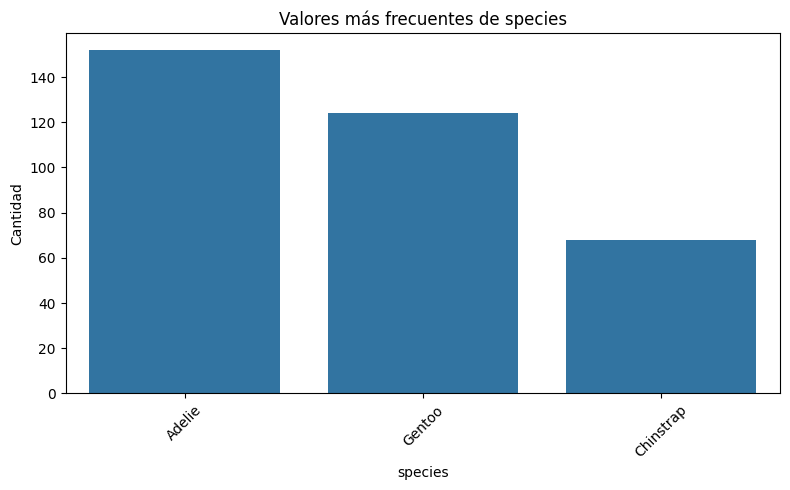

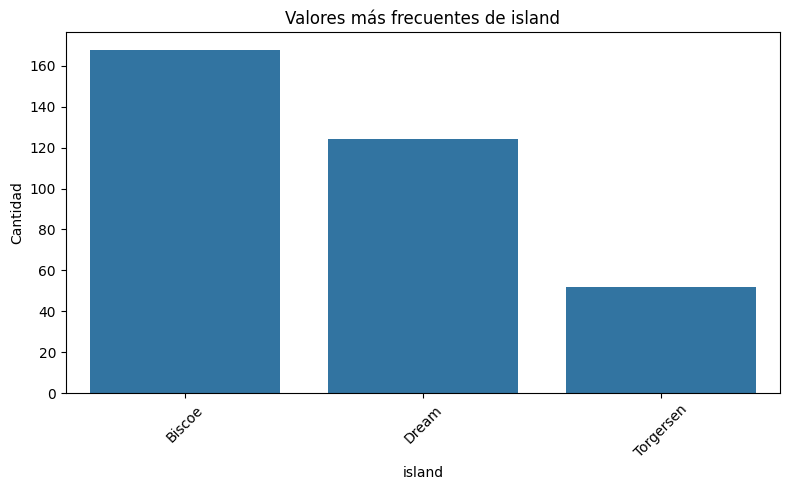

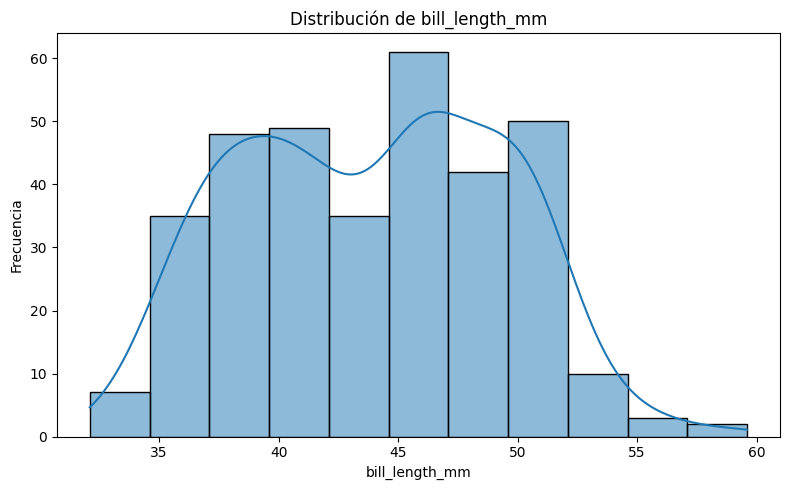

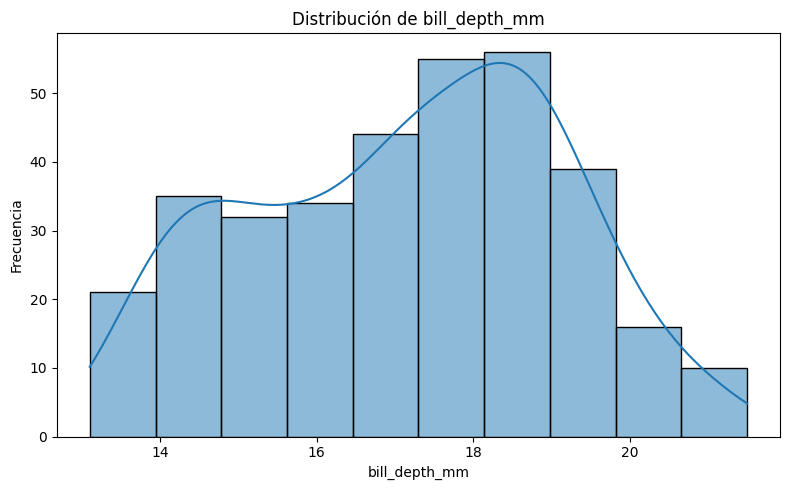

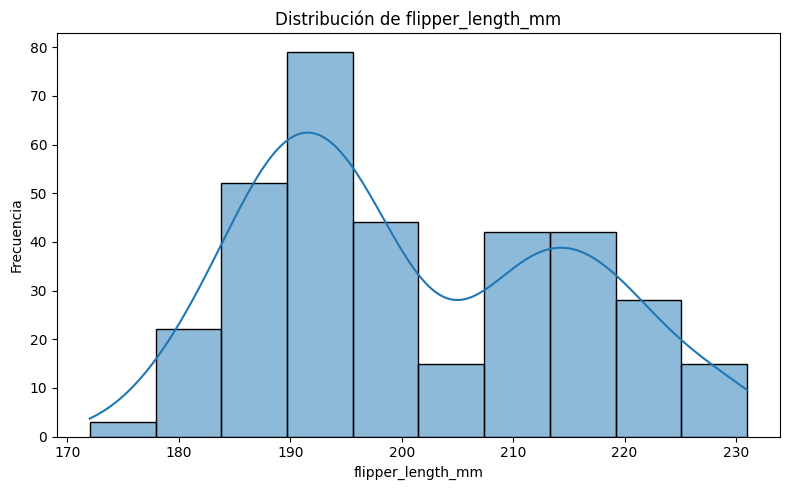

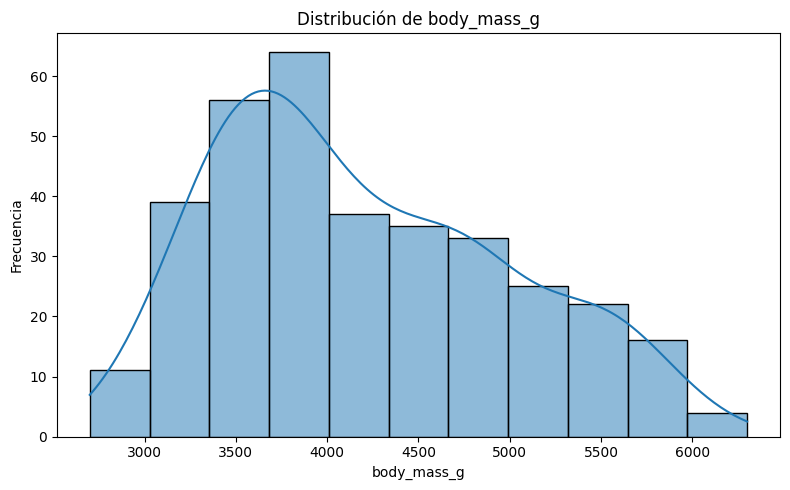

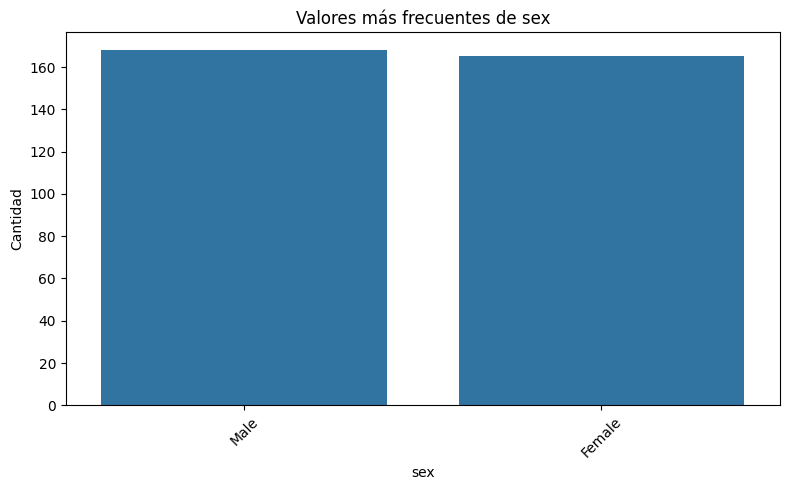

In [ ]:
crear_graficos(
    df_ejemplo,
    carpeta_graficos
)

In [ ]:
# Comprobamos qué archivos se han guardado en la carpeta.
print(os.listdir(carpeta_graficos))

['sex.png', 'bill_length_mm.png', 'bill_depth_mm.png', 'island.png', 'body_mass_g.png', 'species.png', 'flipper_length_mm.png']


La función ha generado un gráfico para cada una de las siete columnas del dataset y los ha guardado (exportado) correctamente en la carpeta indicada.

Las variables species, island y sex se han representado mediante gráficos de barras, mientras que las cuatro variables numéricas se han representado mediante histogramas.

Los histogramas permiten observar cómo se distribuyen las medidas físicas de los pingüinos. Los gráficos aparecen siguiendo el orden original de las columnas del DataFrame, por lo que no se muestran necesariamente agrupados por tipo.

## Ejercicio 2: Optimización de rutas (problema aplicado)

🌍 Contexto:

La empresa no dispone de un control fiable del kilometraje de los desplazamientos de sus trabajadores. Antes de implementar un sistema avanzado, se quiere realizar una prueba piloto con trabajadores ubicados en España.

Para esta prueba:

    » Se trabaja con una matriz de distancias entre ciudades.

    » Se quiere una solución simple, razonable y explicable.

    » No se busca la ruta óptima, sino una aproximación coherente.

Carga el archivo **matriz_distancies.xlsx** en pandas de modo que las filas y columnas sean las ciudades y se eliminen "Las Palmas de Gran Canaria" y "Palma".

Desarrolla una función que:

    » Reciba: una ciudad de origen y una ciudad de destino.

    » Retorne: el orden de las ciudades visitadas (ruta) y la distancia total recorrida.

La ruta debe construirse siguiendo una estrategia sencilla: ir siempre a la ciudad no visitada más cercana hasta llegar al destino.

### Paso 1. Cargar la matriz de distancias

Se carga el archivo Excel "matriu_distancies.xlsx", que contiene las distancias entre las distintas ciudades.

Se utiliza la primera columna como índice para que los nombres de las ciudades aparezcan tanto en las filas como en las columnas de la matriz.

Cada celda muestra la distancia entre la ciudad de la fila y la ciudad de la columna.

In [ ]:
ruta_matriz = "/content/drive/MyDrive/Sprint 8/matriu_distancies.xlsx"

df_distancias = pd.read_excel(ruta_matriz, index_col=0)

In [ ]:
display(df_distancias)

,Barcelona,Valencia,Sevilla,Zaragoza,Málaga,Murcia,Palma,Las Palmas de Gran Canaria,Bilbao,Alicante,Córdoba,Valladolid,Vigo,Gijón,Hospitalet de Llobregat
Barcelona,NaN,303.0,831.0,256.0,770.0,471.0,206.0,2175.0,469.0,407.0,711.0,576.0,908.0,686.0,7.0
Valencia,303.0,NaN,541.0,246.0,468.0,177.0,260.0,1874.0,473.0,125.0,421.0,441.0,766.0,632.0,297.0
Sevilla,831.0,541.0,NaN,646.0,158.0,433.0,791.0,1355.0,703.0,495.0,121.0,486.0,588.0,685.0,824.0
Zaragoza,256.0,246.0,646.0,NaN,628.0,408.0,377.0,2001.0,246.0,368.0,535.0,320.0,652.0,444.0,250.0
Málaga,770.0,468.0,158.0,628.0,NaN,323.0,695.0,1406.0,739.0,391.0,133.0,549.0,716.0,766.0,763.0
Murcia,471.0,177.0,433.0,408.0,323.0,NaN,372.0,1723.0,606.0,69.0,320.0,510.0,800.0,726.0,465.0
Palma,206.0,260.0,791.0,377.0,695.0,372.0,NaN,2093.0,621.0,303.0,671.0,664.0,1000.0,820.0,204.0
Las Palmas de Gran Canaria,2175.0,1874.0,1355.0,2001.0,1406.0,1723.0,2093.0,NaN,2022.0,1792.0,1470.0,1790.0,1682.0,1925.0,2168.0
Bilbao,469.0,473.0,703.0,246.0,739.0,606.0,621.0,2022.0,NaN,583.0,618.0,232.0,486.0,223.0,465.0
Alicante,407.0,125.0,495.0,368.0,391.0,69.0,303.0,1792.0,583.0,NaN,379.0,515.0,821.0,722.0,401.0


Los valores NaN de la diagonal corresponden a la distancia de cada ciudad consigo misma. No afectan al cálculo porque la ruta no debe volver a elegir una ciudad que ya ha sido visitada.

### Paso 2. Eliminar las ciudades indicadas

Se eliminará las ciudades de Las Palmas de Gran Canaria y Palma.

Ambas deben eliminarse de las filas y de las columnas, ya que la matriz utiliza las ciudades tanto como punto de salida como de llegada.

In [ ]:
ciudades_eliminar = ["Las Palmas de Gran Canaria", "Palma"]

df_distancias = df_distancias.drop(
    index=ciudades_eliminar,
    columns=ciudades_eliminar,
    errors="ignore")

display(df_distancias)

,Barcelona,Valencia,Sevilla,Zaragoza,Málaga,Murcia,Bilbao,Alicante,Córdoba,Valladolid,Vigo,Gijón,Hospitalet de Llobregat
Barcelona,NaN,303.0,831.0,256.0,770.0,471.0,469.0,407.0,711.0,576.0,908.0,686.0,7.0
Valencia,303.0,NaN,541.0,246.0,468.0,177.0,473.0,125.0,421.0,441.0,766.0,632.0,297.0
Sevilla,831.0,541.0,NaN,646.0,158.0,433.0,703.0,495.0,121.0,486.0,588.0,685.0,824.0
Zaragoza,256.0,246.0,646.0,NaN,628.0,408.0,246.0,368.0,535.0,320.0,652.0,444.0,250.0
Málaga,770.0,468.0,158.0,628.0,NaN,323.0,739.0,391.0,133.0,549.0,716.0,766.0,763.0
Murcia,471.0,177.0,433.0,408.0,323.0,NaN,606.0,69.0,320.0,510.0,800.0,726.0,465.0
Bilbao,469.0,473.0,703.0,246.0,739.0,606.0,NaN,583.0,618.0,232.0,486.0,223.0,465.0
Alicante,407.0,125.0,495.0,368.0,391.0,69.0,583.0,NaN,379.0,515.0,821.0,722.0,401.0
Córdoba,711.0,421.0,121.0,535.0,133.0,320.0,618.0,379.0,NaN,419.0,589.0,634.0,704.0
Valladolid,576.0,441.0,486.0,320.0,549.0,510.0,232.0,515.0,419.0,NaN,337.0,224.0,570.0


Se añade errors="ignore" para poder ejecutar la celda nuevamente sin que se produzca un error en caso de que las ciudades ya hayan sido eliminadas.

*Paso 2.1. Validación de ciudades eliminadas*



In [ ]:
ciudades_eliminadas = ["Las Palmas de Gran Canaria", "Palma"]

print(
    "¿Siguen en las filas?",
    df_distancias.index.isin(ciudades_eliminadas).any()
)

print(
    "¿Siguen en las columnas?",
    df_distancias.columns.isin(ciudades_eliminadas).any()
)

¿Siguen en las filas? False
¿Siguen en las columnas? False


Después de eliminar Palma y Las Palmas de Gran Canaria, se comprueba mediante isin() que ninguna de las dos ciudades permanezca entre las filas ni entre las columnas de la matriz.

En ambos casos se obtiene False, por lo que la eliminación se realizó correctamente.

### Paso 3. Crear la función para calcular la ruta

A continuación, se crea una función que recibe una ciudad de origen y otra de destino.

La ruta comienza en la ciudad de origen y, mientras no se haya alcanzado el destino, se selecciona la ciudad no visitada que se encuentre a menor distancia.

En cada desplazamiento se guarda la ciudad visitada y se suma la distancia recorrida.

*Paso 3.1. Definir la función y sus datos de entrada*

Primero se define la función calcular_ruta(), que recibe el nombre de la ciudad de origen y el de la ciudad de destino. Ambas se indican como texto.

La función devolverá dos resultados: una lista con el orden de las ciudades visitadas y un número decimal con la distancia total recorrida.

*Paso 3.2: Comprobar que las ciudades existen en la matriz*

Antes de comenzar el recorrido, se comprueba que las ciudades de origen y destino existan en el índice de la matriz.

Si alguna de ellas no aparece, la función se detiene y muestra un mensaje de error, ya que no sería posible consultar sus distancias.

*Paso 3.3: Preparar las variables iniciales*

Una vez comprobadas las ciudades, se preparan las variables necesarias para construir la ruta.

Al inicio, la ruta y el conjunto de ciudades visitadas contienen únicamente la ciudad de origen. También se establece esta como ciudad actual y se inicia la distancia total en cero.


*Paso 3.4. Repetir el recorrido hasta llegar al destino*

La búsqueda de ciudades se repite mientras la ciudad actual sea diferente de la ciudad de destino. (con while)

Cuando ambas coinciden, significa que la ruta ha llegado a su destino y el bucle termina.

*Paso 3.5. Obtener las distancias disponibles*

En cada etapa del recorrido se selecciona la fila correspondiente a la ciudad actual.

Después se eliminan las ciudades ya visitadas y los valores ausentes. De esta forma, solamente quedan disponibles las ciudades a las que todavía se puede viajar.

El resultado se va guardando en la variable "distancias_disponibles". Contendrá solo las distancias hacia ciudades que todavía no han sido visitadas.


*Paso 3.6: Seleccionar la ciudad más cercana y sumar la distancia*

Entre las ciudades que todavía no han sido visitadas, se selecciona la que se encuentra a menor distancia.

Después, esta distancia se suma al total acumulado.

*Paso 3.7. Actualizar la información del recorrido*

La ciudad seleccionada se añade a la ruta y al conjunto de ciudades visitadas.

Después pasa a ser la nueva ciudad actual, desde la cual se volverá a buscar la ciudad no visitada más cercana.

*Paso 3.8. Devolver la ruta y la distancia total*

Una vez alcanzada la ciudad de destino, la función devuelve la ruta completa y la distancia total recorrida.

Los dos resultados se devuelven juntos en una tupla.

In [ ]:
def calcular_ruta(origen: str, destino: str) -> tuple[list[str], float]:
    """
    Calcula una ruta eligiendo siempre la ciudad no visitada más cercana.

    Devuelve la ruta seguida y la distancia total recorrida.
    """
    if origen not in df_distancias.index or destino not in df_distancias.index:
      raise ValueError("La ciudad de origen o destino no existe en la matriz.")

    ruta = [origen]
    visitadas = {origen}
    ciudad_actual = origen
    distancia_total = 0.0

    while ciudad_actual != destino:
      distancias_disponibles = (
        df_distancias.loc[ciudad_actual]
        .drop(labels=visitadas, errors="ignore")
        .dropna()
      )
      ciudad_siguiente = distancias_disponibles.idxmin()
      distancia_total += distancias_disponibles.loc[ciudad_siguiente]

      ruta.append(ciudad_siguiente)
      visitadas.add(ciudad_siguiente)
      ciudad_actual = ciudad_siguiente

    return ruta, distancia_total

### Paso 4. Probar la función

Para comprobar el funcionamiento de la función, se calcula una ruta desde Barcelona hasta Madrid.

Los dos resultados se guardan por separado: por un lado, el orden de las ciudades visitadas y, por otro, la distancia total recorrida.

In [ ]:
ruta_resultado, distancia_resultado = calcular_ruta(
    "Barcelona",
    "Sevilla"
)

print("Ruta:")
print(" → ".join(ruta_resultado))

print(f"\nDistancia total: {distancia_resultado:.0f} km")

Ruta:
Barcelona → Hospitalet de Llobregat → Zaragoza → Valencia → Alicante → Murcia → Córdoba → Sevilla

Distancia total: 1138 km


La función ha creado una ruta desde Barcelona hasta Sevilla siguiendo el criterio indicado: en cada etapa ha seleccionado la ciudad no visitada más cercana.

La ruta obtenida pasa por Hospitalet de Llobregat, Zaragoza, Valencia, Alicante, Murcia y Córdoba antes de llegar a Sevilla. La distancia total recorrida es de 1.138 km. Cabe señalar que, según la matriz, la distancia directa entre Barcelona y Sevilla es de 831 km, menor que los 1.138 km obtenidos.

Esto demuestra que la estrategia de escoger siempre la ciudad más cercana ofrece una solución sencilla y coherente, pero no garantiza que el recorrido completo sea el más corto posible.